## Quy trình thực nghiệm thống nhất

Notebook thực hiện bài toán trong đề tài: phân loại tư thế nhân vật Phật giáo từ ảnh RGB 2D theo L1–L2, trả nhãn cụ thể nhất đủ tin cậy và giữ L1 hoặc Không xác định khi thiếu căn cứ. Bounding box, COCO-17 keypoint và khung xương hỗ trợ phân tích; không suy diễn danh tính hay nội dung tôn giáo.

Chạy lần lượt từ mục 1 để thực hiện một thí nghiệm: kiểm tra dữ liệu và chia tập theo hiện vật → khảo sát nhãn và kappa → huấn luyện, lựa chọn mô hình ảnh → ước lượng keypoint và đánh giá PCK/OKS/IoU → phân loại từ hình học → khóa lựa chọn trên validation → đánh giá cùng tập test, phân tích lỗi, lưu kết quả và demo. ConvNeXt, lấy mẫu cân bằng và hiệu chỉnh ngưỡng đã nằm trong quy trình này, không có mục cải tiến chạy riêng.

Để thử ảnh bằng model đã lưu, chạy riêng mục 18 sau khi mở lại notebook. Các kết quả của quy trình mới chỉ có sau khi chạy huấn luyện; đầu ra cũ đã được bỏ khỏi notebook để tránh gán số liệu lịch sử cho mã mới. Các model và báo cáo lịch sử vẫn được giữ trong `outputs`. Không cần file Python bên ngoài.


## 1. Thiết lập thí nghiệm

Khai báo ba kiến trúc ảnh ResNet18, MobileNetV2 và ConvNeXt-Tiny, cùng seed, batch và điều kiện dừng. Tất cả dùng một phép chia dữ liệu và một thư mục kết quả. Batch nhỏ kết hợp tích lũy gradient phù hợp với GPU hiện có.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter, defaultdict
import csv, gc, hashlib, json, math, os, platform, random, shutil, sys, time, warnings

def find_project_root():
    start = Path.cwd().resolve()
    candidates = []
    for base in [start, *start.parents]:
        candidates.extend([base, base / "Thangka_Pose_Training"])
    seen = set()
    for candidate in candidates:
        candidate = candidate.resolve()
        if candidate in seen:
            continue
        seen.add(candidate)
        if (candidate / "Thangka_Pose_Training.ipynb").is_file() and (candidate / "data").exists():
            return candidate
    raise FileNotFoundError("Không tìm thấy thư mục Thangka_Pose_Training chứa notebook và data.")

ROOT = find_project_root()
DATA_DIR = (ROOT / "data").resolve()
RATINGS_DIR = ROOT / "ratings"
OUTPUTS_DIR = ROOT / "outputs"
PRETRAINED_DIR = ROOT / "pretrained"
CACHE_DIR = ROOT / "cache"

SEED = 20261021
IMAGE_SIZE = 384
IMAGE_BATCH_SIZE = 2
IMAGE_MAX_EPOCHS = 100
IMAGE_PATIENCE = 20
IMAGE_HEAD_ONLY_EPOCHS = 5
IMAGE_DROPOUT = 0.30
IMAGE_LABEL_SMOOTHING = 0.05
# Moderate inverse-frequency weighting: rare classes count more without letting a few samples dominate.
CLASS_WEIGHT_POWER = 0.5
POSE_IMAGE_SIZE = 416
POSE_BATCH_SIZE = 2
POSE_INFERENCE_BATCH_SIZE = 1
POSE_EPOCHS = 50
POSE_PATIENCE = 10
# Pre-declared validation operating point: seek >=90% accuracy while retaining >=50% coverage.
# If validation cannot meet it, l1_rejection_curve records and uses a transparent fallback rule.
L1_TARGET_SELECTIVE_ACCURACY = 0.90
L1_MIN_COVERAGE = 0.50
L1_MIN_ACCEPTED = 30
# L2 is emitted only when validation supports both label confidence and sufficient visual evidence.
L2_TARGET_PRECISION = 0.90
L2_MAX_BLANK_ACCEPTANCE = 0.10
L2_MIN_COVERAGE = 0.25
# Use train-only inverse-frequency weights for all classes; no extra C2.2 copies.
RARE_L2_WEIGHT_BOOSTS = {}
C2_2_EXTRA_KEYPOINT_COPIES = 0
REUSE_EXISTING = True
# Each new run trains and compares all image architectures in this notebook.
# Rare posture labels belong to the classifier; do not retrain pose estimation unless its own metrics require it.
FORCE_RETRAIN_POSE = False

RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S") + f"_seed{SEED}"
RUN_ROOT = OUTPUTS_DIR / "notebook_runs" / RUN_ID
RUN_ROOT.mkdir(parents=True, exist_ok=False)

required_paths = [
    DATA_DIR / "classification_manifest.csv",
    DATA_DIR / "keypoints_coco.json",
    DATA_DIR / "ontology.json",
]
missing_data = [str(p) for p in required_paths if not p.is_file()]
if missing_data:
    raise FileNotFoundError("Thiếu dữ liệu bắt buộc:\n" + "\n".join(missing_data))

print("Thư mục dự án:", ROOT)
print("Snapshot dữ liệu:", DATA_DIR)
print("Run mới:", RUN_ROOT)

# Predeclared experiment settings. No test score enters model or threshold selection.
IMAGE_SEEDS = [20261021, 20261031, 20261107]
IMAGE_ARCHITECTURES = ["resnet18", "mobilenet_v2", "convnext_tiny"]
IMAGE_ACCUMULATION_STEPS = 8
IMAGE_MIN_EPOCHS = 30
IMAGE_FULL_FINETUNE_START = 16
TRAIN_MAX_BATCHES = None  # Integration runner may cap this; full training always uses all train rows.
RUN_MODE = "full"
MODEL_SCHEMA = 4
TARGET_L2_CODES = ["C2.3", "C2.5", "C2.11", "C2.10", "C2.7"]


Thư mục dự án: I:\nam4\phan tich anh phat giao\training\Thangka_Pose_Training
Snapshot dữ liệu: I:\nam4\phan tich anh phat giao\training\Thangka_Pose_Training\data
Run mới: I:\nam4\phan tich anh phat giao\training\Thangka_Pose_Training\outputs\notebook_runs\20261103_101754_seed20261021


**Giải thích và giới hạn.** Đường dẫn in ra xác định lần chạy. Chạy lại từ mục 1 tạo một lần chạy mới; chạy riêng demo nạp lần đã hoàn tất.


## 2. Kiểm tra môi trường tính toán

Trước khi xử lý dữ liệu, cell kiểm tra các thư viện cần thiết, phiên bản PyTorch và khả năng sử dụng GPU. Thông tin môi trường giúp giải thích khác biệt khi chạy trên máy khác và hỗ trợ tái lập thí nghiệm.

In [2]:
required_imports = {
    "numpy": "numpy",
    "pandas": "pandas",
    "PIL": "Pillow",
    "matplotlib": "matplotlib",
    "sklearn": "scikit-learn",
    "joblib": "joblib",
    "openpyxl": "openpyxl",
    "torch": "torch",
    "torchvision": "torchvision",
    "ultralytics": "ultralytics",
    "yaml": "PyYAML",
}
missing_packages = []
for module_name, package_name in required_imports.items():
    try:
        __import__(module_name)
    except Exception:
        missing_packages.append(package_name)
if missing_packages:
    raise RuntimeError(
        "Môi trường thiếu: " + ", ".join(missing_packages) +
        ". Cài đúng PyTorch CUDA trước, sau đó cài các gói còn lại và khởi động lại kernel."
    )

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import torch
import torchvision
from PIL import Image
from openpyxl import load_workbook
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, cohen_kappa_score, confusion_matrix, f1_score, classification_report
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from ultralytics import YOLO

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
environment = {
    "python": sys.version,
    "platform": platform.platform(),
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "cuda_available": torch.cuda.is_available(),
    "cuda_runtime": torch.version.cuda,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "seed": SEED,
}
(RUN_ROOT / "environment.json").write_text(json.dumps(environment, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(environment, ensure_ascii=False, indent=2))
if DEVICE == "cpu":
    warnings.warn("Đang chạy CPU. Pose training có thể rất chậm; kết quả vẫn hợp lệ nhưng thời gian dài hơn.")


{
  "python": "3.10.11 (tags/v3.10.11:7d4cc5a, Apr  5 2023, 00:38:17) [MSC v.1929 64 bit (AMD64)]",
  "platform": "Windows-10-10.0.26200-SP0",
  "torch": "2.10.0+cu126",
  "torchvision": "0.25.0+cu126",
  "cuda_available": true,
  "cuda_runtime": "12.6",
  "gpu": "NVIDIA GeForce RTX 3050 Laptop GPU",
  "seed": 20261021
}


**Giải thích và giới hạn.** Phiên bản thư viện và thiết bị được ghi cùng run. Bộ nhớ GPU ảnh hưởng batch và thời gian; không dùng thông tin môi trường để suy ra độ chính xác.


## 3. Xây dựng các hàm dùng chung

Định nghĩa tiền xử lý toàn thân, mô hình phân cấp, huấn luyện và đánh giá. ConvNeXt lấy mẫu theo tần suất L2 trong train; không đồng thời nhân thêm trọng số loss nghịch tần suất. Mẫu L2 trống vẫn học L1 và bằng chứng, nhưng không bị ép học một nhãn con. Ngưỡng theo nhánh cha được so với ngưỡng từng lớp và kiểm tra qua ba fold theo hiện vật.


In [3]:
"""Reproducible training utilities for the private DACNTT Thangka dataset."""

from __future__ import annotations

import csv
import hashlib
import json
import math
import os
import random
from collections import Counter, defaultdict
from pathlib import Path
from typing import Any

import numpy as np
import torch
from PIL import Image
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import models, transforms
from torchvision.transforms import InterpolationMode

PROJECT_ROOT = ROOT
DEFAULT_DATASET_ROOT = DATA_DIR
IGNORE_L2 = -100
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)


def seed_everything(seed: int = 20261021) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def _read_json(path: Path) -> dict[str, Any]:
    return json.loads(path.read_text(encoding="utf-8-sig"))


def load_snapshot(dataset_root: str | Path = DEFAULT_DATASET_ROOT) -> dict[str, Any]:
    root = Path(dataset_root).expanduser().resolve()
    metadata = _read_json(root / "dataset_metadata.json")
    ontology = _read_json(root / "ontology.json")
    registry = _read_json(root / "split_registry.json")
    with (root / "classification_manifest.csv").open(encoding="utf-8-sig", newline="") as stream:
        rows = list(csv.DictReader(stream))
    return {"root": root, "metadata": metadata, "ontology": ontology, "registry": registry, "rows": rows}


def _as_bool(value: str) -> bool:
    return str(value).strip().lower() in {"true", "1", "yes"}


def audit_snapshot(snapshot: dict[str, Any], check_files: bool = True) -> dict[str, Any]:
    root, metadata, ontology, registry, rows = (
        snapshot["root"], snapshot["metadata"], snapshot["ontology"], snapshot["registry"], snapshot["rows"]
    )
    errors: list[str] = []
    if not metadata.get("ready_for_training"):
        errors.append("Metadata does not mark this snapshot ready_for_training.")
    if metadata.get("scope") != "approved":
        errors.append(f"Expected approved-only snapshot; got scope={metadata.get('scope')!r}.")
    if len(rows) != int(metadata.get("records", -1)):
        errors.append(f"CSV row count {len(rows)} differs from metadata record count {metadata.get('records')}.")
    if len({r["instance_id"] for r in rows}) != len(rows):
        errors.append("Duplicate instance_id values in classification_manifest.csv.")

    l1_codes = [item["code"] for item in sorted(ontology["level_1"], key=lambda item: item["index"])]
    l2_codes = [item["code"] for item in sorted(ontology["level_2"], key=lambda item: item["index"])]
    l1_to_idx = {code: i for i, code in enumerate(l1_codes)}
    l2_to_idx = {code: i for i, code in enumerate(l2_codes)}
    l2_parent = {item["code"]: item["parent"] for item in ontology["level_2"]}

    split_counts: Counter[str] = Counter()
    l1_counts: Counter[str] = Counter()
    l2_counts: Counter[str] = Counter()
    split_l2_counts: dict[str, Counter[str]] = defaultdict(Counter)
    missing_files: list[str] = []
    hash_splits: dict[str, set[str]] = defaultdict(set)
    group_splits: dict[str, set[str]] = defaultdict(set)
    assignments = registry.get("assignments", {})
    group_assignments = registry.get("group_assignments", {})

    for row in rows:
        split = row.get("split", "")
        l1 = row.get("level_1_code", "")
        l2 = row.get("level_2_code", "")
        if split not in {"train", "val", "test"}:
            errors.append(f"Invalid split {split!r} for {row.get('instance_id')}.")
        split_counts[split] += 1
        if row.get("review_status") != "approved" or not _as_bool(row.get("human_verified", "")):
            errors.append(f"Non-approved or non-human-verified record: {row.get('instance_id')}.")
        if l1 not in l1_to_idx:
            errors.append(f"Missing/unknown L1 label for {row.get('instance_id')}: {l1!r}.")
        else:
            l1_counts[l1] += 1
        if l2:
            if l2 not in l2_to_idx:
                errors.append(f"Unknown L2 label {l2!r} for {row.get('instance_id')}.")
            else:
                l2_counts[l2] += 1
                split_l2_counts[split][l2] += 1
                if l2_parent[l2] != l1:
                    errors.append(f"Ontology parent mismatch for {row.get('instance_id')}: {l1} vs {l2}.")
        if row.get("rights_status") not in {"verified", "research_only"}:
            errors.append(f"Rights status not eligible for internal training: {row.get('instance_id')}.")
        if check_files:
            crop_rel = Path(row["crop_path"])
            if crop_rel.is_absolute() or ".." in crop_rel.parts:
                errors.append(f"Unsafe crop path in manifest: {row['crop_path']}.")
            elif not (root / crop_rel).is_file():
                missing_files.append(str(crop_rel))
        for digest in (row.get("content_sha256", ""), row.get("crop_sha256", "")):
            if digest:
                hash_splits[digest].add(split)
        artifact_id = row.get("artifact_id", "")
        group_id = group_assignments.get(artifact_id, artifact_id)
        expected_split = assignments.get(group_id, assignments.get(artifact_id))
        if expected_split and expected_split != split:
            errors.append(f"Split registry mismatch for {artifact_id}: CSV={split}, registry={expected_split}.")
        group_splits[group_id].add(split)

    if missing_files:
        errors.append(f"Missing crop files: {len(missing_files)} (first: {missing_files[:5]}).")
    leaking_groups = [group for group, splits in group_splits.items() if len(splits) > 1]
    leaking_hashes = [digest for digest, splits in hash_splits.items() if len(splits) > 1]
    if leaking_groups:
        errors.append(f"Group leakage across splits: {len(leaking_groups)} groups.")
    if leaking_hashes:
        errors.append(f"Exact-image hash leakage across splits: {len(leaking_hashes)} hashes.")
    if errors:
        raise ValueError("Snapshot audit failed:\n- " + "\n- ".join(errors))

    manifest_sha256 = hashlib.sha256((root / "classification_manifest.csv").read_bytes()).hexdigest()
    return {
        "dataset_version": metadata["dataset_version"],
        "manifest_sha256": manifest_sha256,
        "records": len(rows),
        "split_counts": dict(split_counts),
        "l1_counts": dict(l1_counts),
        "l2_counts": dict(l2_counts),
        "l2_by_split": {split: dict(counts) for split, counts in split_l2_counts.items()},
        "l2_labeled": sum(1 for row in rows if row.get("level_2_code")),
        "l2_unlabeled": sum(1 for row in rows if not row.get("level_2_code")),
        "l1_codes": l1_codes,
        "l2_codes": l2_codes,
        "l2_parent": l2_parent,
        "split_group_count": len(group_splits),
        "audit_status": "passed",
    }


def class_index_maps(ontology: dict[str, Any]) -> dict[str, Any]:
    l1_codes = [item["code"] for item in sorted(ontology["level_1"], key=lambda item: item["index"])]
    l2_codes = [item["code"] for item in sorted(ontology["level_2"], key=lambda item: item["index"])]
    l1_to_idx = {code: i for i, code in enumerate(l1_codes)}
    l2_to_idx = {code: i for i, code in enumerate(l2_codes)}
    l2_parent = {item["code"]: item["parent"] for item in ontology["level_2"]}
    return {"l1_codes": l1_codes, "l2_codes": l2_codes, "l1_to_idx": l1_to_idx, "l2_to_idx": l2_to_idx, "l2_parent": l2_parent}


class ResizeWithPad:
    """Resize without distorting body proportions, then pad to a square canvas."""
    def __init__(self, size: int, fill=(255, 255, 255)):
        self.size = int(size)
        self.fill = fill

    def __call__(self, image: Image.Image) -> Image.Image:
        image = image.copy()
        ratio = self.size / max(image.size)
        image = image.resize((max(1, round(image.width * ratio)), max(1, round(image.height * ratio))), Image.Resampling.BILINEAR)
        canvas = Image.new("RGB", (self.size, self.size), self.fill)
        left = (self.size - image.width) // 2
        top = (self.size - image.height) // 2
        canvas.paste(image, (left, top))
        return canvas


class ThangkaDataset(Dataset):
    def __init__(self, rows: list[dict[str, str]], root: Path, indices: dict[str, Any], train: bool = False):
        self.rows = [row for row in rows if row["split"] == "train"] if train else list(rows)
        self.root = root
        self.indices = indices
        if train:
            self.transform = transforms.Compose([
                # Rotate on an expanded canvas BEFORE resize: never cut off feet or a reclining body.
                transforms.RandomRotation(degrees=7, expand=True, fill=(255, 255, 255)),
                ResizeWithPad(IMAGE_SIZE),
                transforms.RandomHorizontalFlip(p=0.5),
                transforms.ColorJitter(brightness=0.10, contrast=0.10, saturation=0.05, hue=0.02),
                transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
            ])
        else:
            self.transform = transforms.Compose([
                ResizeWithPad(IMAGE_SIZE),
                transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
            ])

    def __len__(self) -> int:
        return len(self.rows)

    def __getitem__(self, index: int):
        row = self.rows[index]
        with Image.open(self.root / row["crop_path"]) as image:
            tensor = self.transform(image.convert("RGB"))
        l1 = self.indices["l1_to_idx"][row["level_1_code"]]
        l2 = self.indices["l2_to_idx"].get(row["level_2_code"], IGNORE_L2)
        return tensor, l1, l2, index


def make_loaders(snapshot: dict[str, Any], batch_size: int = 16, seed: int = 20261021, balanced_sampling=False):
    indices = class_index_maps(snapshot["ontology"])
    train_rows = [r for r in snapshot["rows"] if r["split"] == "train"]
    val_rows = [r for r in snapshot["rows"] if r["split"] == "val"]
    test_rows = [r for r in snapshot["rows"] if r["split"] == "test"]
    train_ds = ThangkaDataset(train_rows, snapshot["root"], indices, train=True)
    val_ds = ThangkaDataset(val_rows, snapshot["root"], indices, train=False)
    test_ds = ThangkaDataset(test_rows, snapshot["root"], indices, train=False)
    generator = torch.Generator().manual_seed(seed)
    pin_memory = torch.cuda.is_available()
    sampler = None
    if balanced_sampling:
        counts = Counter(r["level_2_code"] for r in train_rows if r["level_2_code"])
        weights = np.array([1 / np.sqrt(counts[r["level_2_code"]]) if r["level_2_code"] else 0. for r in train_rows])
        known = weights > 0
        if known.any() and (~known).any():
            weights[known] *= .8 / weights[known].sum()
            weights[~known] = .2 / (~known).sum()
        elif not known.any():
            weights[:] = 1.
        sampler = WeightedRandomSampler(weights, len(train_rows), replacement=True, generator=generator)
    loaders = {
        "train": DataLoader(train_ds, batch_size=batch_size, shuffle=sampler is None, sampler=sampler, num_workers=0, pin_memory=pin_memory, generator=generator),
        "val": DataLoader(val_ds, batch_size=batch_size, shuffle=False, num_workers=0, pin_memory=pin_memory),
        "test": DataLoader(test_ds, batch_size=batch_size, shuffle=False, num_workers=0, pin_memory=pin_memory),
    }
    return loaders, indices


class MultiTaskClassifier(nn.Module):
    def __init__(self, architecture: str, n_l1: int, n_l2: int, pretrained: bool = True):
        super().__init__()
        if architecture == "resnet18":
            weights = models.ResNet18_Weights.DEFAULT if pretrained else None
            backbone = models.resnet18(weights=weights)
            feature_dim = backbone.fc.in_features
            backbone.fc = nn.Identity()
        elif architecture == "mobilenet_v2":
            weights = models.MobileNet_V2_Weights.DEFAULT if pretrained else None
            legacy_cache = Path(torch.hub.get_dir()) / "checkpoints" / "mobilenet_v2-b0353104.pth"
            current_cache = Path(torch.hub.get_dir()) / "checkpoints" / "mobilenet_v2-7ebf99e0.pth"
            if pretrained and legacy_cache.is_file() and not current_cache.is_file():
                # Older official torchvision cache filename; strict loading verifies the
                # checkpoint matches this MobileNetV2 architecture before it is used.
                # The filename carries torchvision's SHA-256 prefix; verify it as well.
                cached_hash = hashlib.sha256(legacy_cache.read_bytes()).hexdigest()
                if not cached_hash.startswith("b0353104"):
                    raise ValueError(f"Unexpected MobileNetV2 cache checksum: {cached_hash}")
                backbone = models.mobilenet_v2(weights=None)
                state = torch.load(legacy_cache, map_location="cpu", weights_only=True)
                backbone.load_state_dict(state, strict=True)
            else:
                backbone = models.mobilenet_v2(weights=weights)
            feature_dim = backbone.classifier[-1].in_features
            backbone.classifier = nn.Identity()
        elif architecture == "convnext_tiny":
            backbone = models.convnext_tiny(weights=None)
            if pretrained:
                local = ROOT / "pretrained/convnext_tiny-983f1562.pth"
                if local.is_file():
                    if not hashlib.sha256(local.read_bytes()).hexdigest().startswith("983f1562"):
                        raise ValueError("ConvNeXt pretrained checksum mismatch")
                    backbone.load_state_dict(torch.load(local, map_location="cpu", weights_only=True))
                else:
                    backbone = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.DEFAULT)
            feature_dim = backbone.classifier[-1].in_features
            backbone.classifier[-1] = nn.Identity()
        else:
            raise ValueError(f"Unsupported architecture: {architecture}")
        self.architecture = architecture
        self.backbone = backbone
        self.l1_head = nn.Sequential(nn.Dropout(IMAGE_DROPOUT), nn.Linear(feature_dim, n_l1))
        self.l2_head = nn.Sequential(nn.Dropout(IMAGE_DROPOUT), nn.Linear(feature_dim, n_l2))
        self.evidence_head = nn.Sequential(nn.Dropout(IMAGE_DROPOUT), nn.Linear(feature_dim, 2))

    def forward(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        features = self.backbone(x)
        return self.l1_head(features), self.l2_head(features), self.evidence_head(features)


def _balanced_weights(labels: list[int], class_count: int, device: torch.device) -> torch.Tensor:
    counts = np.bincount(np.asarray(labels, dtype=np.int64), minlength=class_count).astype(np.float64)
    if np.any(counts == 0):
        raise ValueError(f"Training split lacks one or more classes: {counts.tolist()}")
    weights = 1.0 / np.power(counts, CLASS_WEIGHT_POWER)
    weights /= weights.mean()
    return torch.tensor(weights, dtype=torch.float32, device=device)


def configure_backbone_stage(model, head_only, full=False):
    """Small batches must not overwrite pretrained BN running statistics."""
    model.backbone.eval()
    for parameter in model.backbone.parameters():
        parameter.requires_grad = False
    if head_only:
        return
    if full:
        blocks = [model.backbone]
    elif model.architecture == "resnet18":
        blocks = [model.backbone.layer3, model.backbone.layer4]
    elif model.architecture == "convnext_tiny":
        blocks = [model.backbone.features[4:]]
    else:
        blocks = [model.backbone.features[7:]]
    for block in blocks:
        block.train()
        for parameter in block.parameters():
            parameter.requires_grad = True
    for module in model.backbone.modules():
        if isinstance(module, nn.modules.batchnorm._BatchNorm):
            module.eval()


def hierarchical_l2_loss(
    logits: torch.Tensor, y1: torch.Tensor, y2: torch.Tensor, indices: dict[str, Any],
    class_weights: torch.Tensor | None = None, label_smoothing: float = 0.0,
) -> torch.Tensor:
    """Train L2 only against siblings under the gold L1 branch."""
    branch_losses = []
    for parent_index, parent_code in enumerate(indices["l1_codes"]):
        child_codes = [code for code in indices["l2_codes"] if indices["l2_parent"][code] == parent_code]
        child_indices = [indices["l2_to_idx"][code] for code in child_codes]
        branch_mask = (y2 != IGNORE_L2) & (y1 == parent_index)
        if not branch_mask.any() or len(child_indices) <= 1:
            continue
        local_logits = logits[branch_mask][:, child_indices]
        global_targets = y2[branch_mask]
        local_targets = torch.empty_like(global_targets)
        for local_index, global_index in enumerate(child_indices):
            local_targets[global_targets == global_index] = local_index
        local_weights = class_weights[child_indices] if class_weights is not None else None
        branch_losses.append(F.cross_entropy(
            local_logits, local_targets, weight=local_weights, label_smoothing=label_smoothing,
        ))
    return torch.stack(branch_losses).mean() if branch_losses else logits.sum() * 0.0


def fit_hierarchical_temperatures(outputs: dict[str, np.ndarray], indices: dict[str, Any]) -> dict[str, float]:
    """Fit L1 and branch-aware L2 temperature scaling on validation logits only."""
    logits1 = torch.tensor(outputs["l1_logits"], dtype=torch.float32)
    logits2 = torch.tensor(outputs["l2_logits"], dtype=torch.float32)
    y1 = torch.tensor(outputs["y1"], dtype=torch.long)
    y2 = torch.tensor(outputs["y2"], dtype=torch.long)

    def optimize(loss_builder):
        log_temperature = torch.zeros(1, requires_grad=True)
        optimizer = torch.optim.LBFGS([log_temperature], lr=0.1, max_iter=60, line_search_fn="strong_wolfe")
        def closure():
            optimizer.zero_grad()
            temperature = log_temperature.exp().clamp(0.25, 10.0)
            loss = loss_builder(temperature)
            loss.backward()
            return loss
        optimizer.step(closure)
        return float(log_temperature.detach().exp().clamp(0.25, 10.0).item())

    t1_candidate = optimize(lambda temperature: F.cross_entropy(logits1 / temperature, y1))
    before_l1 = multiclass_calibration_metrics(outputs["l1_logits"], outputs["y1"])
    after_l1 = multiclass_calibration_metrics(outputs["l1_logits"] / t1_candidate, outputs["y1"])
    before_score = before_l1["ece_10_bins"] + before_l1["multiclass_brier"]
    after_score = after_l1["ece_10_bins"] + after_l1["multiclass_brier"]
    # NLL temperature scaling can worsen ECE/Brier on a small validation set.
    # Keep identity calibration unless the declared validation calibration score improves.
    t1 = t1_candidate if after_score <= before_score else 1.0
    def l2_objective(temperature):
        return hierarchical_l2_loss(logits2 / temperature, y1, y2, indices)
    t2 = optimize(l2_objective)
    temperatures = {"l1_temperature": t1, "l2_temperature": t2}
    if "l2_evidence_logits" in outputs:
        evidence_logits = torch.tensor(outputs["l2_evidence_logits"], dtype=torch.float32)
        evidence_gold = (y2 != IGNORE_L2).long()
        temperatures["evidence_temperature"] = optimize(lambda t: F.cross_entropy(evidence_logits / t, evidence_gold))
    return temperatures


def apply_temperatures(outputs: dict[str, np.ndarray], temperatures: dict[str, float]) -> dict[str, np.ndarray]:
    calibrated = dict(outputs)
    calibrated["l1_logits"] = outputs["l1_logits"] / temperatures["l1_temperature"]
    calibrated["l2_logits"] = outputs["l2_logits"] / temperatures["l2_temperature"]
    if "l2_evidence_logits" in outputs:
        calibrated["l2_evidence_logits"] = outputs["l2_evidence_logits"] / temperatures.get("evidence_temperature", 1.0)
    return calibrated


def multiclass_calibration_metrics(logits: np.ndarray, targets: np.ndarray, bins: int = 10) -> dict[str, float]:
    probabilities = torch.softmax(torch.tensor(logits), dim=1).numpy()
    confidence = probabilities.max(axis=1)
    prediction = probabilities.argmax(axis=1)
    correct = (prediction == targets).astype(np.float64)
    ece = 0.0
    edges = np.linspace(0.0, 1.0, bins + 1)
    for lower, upper in zip(edges[:-1], edges[1:]):
        mask = (confidence > lower) & (confidence <= upper)
        if mask.any():
            ece += float(mask.mean() * abs(correct[mask].mean() - confidence[mask].mean()))
    one_hot = np.eye(probabilities.shape[1], dtype=np.float64)[targets]
    brier = float(np.mean(np.sum((probabilities - one_hot) ** 2, axis=1)))
    return {"ece_10_bins": ece, "multiclass_brier": brier}


def collect_logits(model, loader, device):
    model.eval()
    values = {key: [] for key in ("l1_logits", "l2_logits", "l2_evidence_logits", "y1", "y2", "indices")}
    with torch.inference_mode():
        for images, y1, y2, sample_indices in loader:
            logits1, logits2, evidence = model(images.to(device, non_blocking=True))
            for key, value in zip(values, (logits1, logits2, evidence, y1, y2, sample_indices)):
                values[key].append(value.detach().float().cpu().numpy() if key.endswith("logits") else value.cpu().numpy())
    return {key: np.concatenate(value) for key, value in values.items()}


def classification_metrics(y_true: np.ndarray, y_pred: np.ndarray, labels: list[int]) -> dict[str, Any]:
    matrix = np.zeros((len(labels), len(labels)), dtype=np.int64)
    label_pos = {value: i for i, value in enumerate(labels)}
    for truth, pred in zip(y_true.tolist(), y_pred.tolist()):
        if truth in label_pos and pred in label_pos:
            matrix[label_pos[truth], label_pos[pred]] += 1
    per_class = []
    for i, label in enumerate(labels):
        tp = int(matrix[i, i])
        support = int(matrix[i, :].sum())
        predicted = int(matrix[:, i].sum())
        precision = tp / predicted if predicted else 0.0
        recall = tp / support if support else 0.0
        f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
        per_class.append({"label_index": int(label), "support": support, "precision": precision, "recall": recall, "f1": f1})
    total = int(matrix.sum())
    correct = int(np.trace(matrix))
    return {
        "n": total,
        "accuracy": float(correct / total) if total else 0.0,
        "accuracy_95ci_wilson": wilson_interval(correct, total),
        "macro_f1": float(np.mean([item["f1"] for item in per_class])) if per_class else 0.0,
        "per_class": per_class,
        "confusion_matrix": matrix.tolist(),
    }


def wilson_interval(successes: int, total: int, z: float = 1.96) -> list[float] | None:
    """Two-sided 95% Wilson score interval for a binomial proportion."""
    if total <= 0:
        return None
    p = successes / total
    denominator = 1 + z * z / total
    center = (p + z * z / (2 * total)) / denominator
    half_width = z * math.sqrt(p * (1 - p) / total + z * z / (4 * total * total)) / denominator
    return [max(0.0, center - half_width), min(1.0, center + half_width)]


def metrics_from_outputs(outputs: dict[str, np.ndarray], indices: dict[str, Any]) -> dict[str, Any]:
    pred_l1 = outputs["l1_logits"].argmax(axis=1)
    l1_metrics = classification_metrics(outputs["y1"], pred_l1, list(range(len(indices["l1_codes"]))))
    valid = outputs["y2"] != IGNORE_L2
    gold_l2 = outputs["y2"][valid]
    gold_l1 = outputs["y1"][valid]
    logits_l2 = outputs["l2_logits"][valid]
    pred_oracle = np.empty_like(gold_l2)
    for i, parent_idx in enumerate(gold_l1.tolist()):
        parent_code = indices["l1_codes"][parent_idx]
        child_idx = [indices["l2_to_idx"][code] for code, parent in indices["l2_parent"].items() if parent == parent_code]
        pred_oracle[i] = child_idx[int(logits_l2[i, child_idx].argmax())]
    l2_oracle = classification_metrics(gold_l2, pred_oracle, list(range(len(indices["l2_codes"]))))
    return {"l1": l1_metrics, "l2_oracle_given_gold_l1": l2_oracle}


def hierarchical_predictions(
    outputs: dict[str, np.ndarray], indices: dict[str, Any], threshold: float,
    l1_threshold: float = 0.0, evidence_ok: np.ndarray | list[bool] | None = None,
    l2_evidence_threshold: float = 0.0, class_thresholds: dict[str, float] | None = None,
) -> list[dict[str, Any]]:
    p_l1 = torch.softmax(torch.tensor(outputs["l1_logits"]), dim=1).numpy()
    logits_l2 = outputs["l2_logits"]
    if "l2_evidence_logits" in outputs:
        l2_evidence_probability = torch.softmax(torch.tensor(outputs["l2_evidence_logits"]), dim=1).numpy()[:, 1]
    else:
        l2_evidence_probability = np.ones(len(p_l1), dtype=np.float64)
    if evidence_ok is None:
        evidence_ok = np.ones(len(p_l1), dtype=bool)
    evidence_ok = np.asarray(evidence_ok, dtype=bool)
    if len(evidence_ok) != len(p_l1):
        raise ValueError("evidence_ok must have one value per prediction.")
    class_thresholds = class_thresholds or {}
    predictions = []
    for i in range(len(p_l1)):
        parent_idx = int(p_l1[i].argmax())
        parent_code = indices["l1_codes"][parent_idx]
        l1_confidence = float(p_l1[i, parent_idx])
        l1_accepted = bool(evidence_ok[i] and l1_confidence >= l1_threshold)
        child_codes = [code for code in indices["l2_codes"] if indices["l2_parent"][code] == parent_code]
        child_indices = [indices["l2_to_idx"][code] for code in child_codes]
        child_probs = torch.softmax(torch.tensor(logits_l2[i, child_indices]), dim=0).numpy()
        local_idx = int(child_probs.argmax())
        candidate_code = child_codes[local_idx]
        joint_confidence = float(l1_confidence * child_probs[local_idx])
        required_l2_confidence = float(class_thresholds.get(candidate_code, threshold))
        evidence_probability = float(l2_evidence_probability[i])
        l2_evidence_ok = evidence_probability >= l2_evidence_threshold
        l2_accepted = bool(l1_accepted and l2_evidence_ok and joint_confidence >= required_l2_confidence)
        decision_level = "l2" if l2_accepted else ("l1" if l1_accepted else "unknown")
        final_code = candidate_code if l2_accepted else (parent_code if l1_accepted else "")
        final_confidence = joint_confidence if l2_accepted else l1_confidence
        predictions.append({
            "l1_code": parent_code if l1_accepted else "",
            "l1_candidate": parent_code, "l1_confidence": l1_confidence,
            "l2_candidate": candidate_code, "l2_confidence": joint_confidence,
            "l2_required_confidence": required_l2_confidence,
            "l2_evidence_confidence": evidence_probability, "l2_evidence_ok": bool(l2_evidence_ok),
            "l2_code": candidate_code if l2_accepted else "",
            "used_l1_fallback": bool(l1_accepted and not l2_accepted),
            "is_unknown": not l1_accepted, "decision_level": decision_level,
            "final_code": final_code, "final_confidence": final_confidence,
            "evidence_ok": bool(evidence_ok[i]),
        })
    return predictions


def l1_rejection_curve(
    outputs: dict[str, np.ndarray], min_coverage: float = 0.50, min_accepted: int = 30,
    target_accuracy: float = 0.85, evidence_ok: np.ndarray | list[bool] | None = None,
):
    probabilities = torch.softmax(torch.tensor(outputs["l1_logits"]), dim=1).numpy()
    confidence = probabilities.max(axis=1)
    predicted = probabilities.argmax(axis=1)
    gold = np.asarray(outputs["y1"], dtype=np.int64)
    if evidence_ok is None:
        evidence_ok = np.ones(len(gold), dtype=bool)
    evidence_ok = np.asarray(evidence_ok, dtype=bool)
    candidates = sorted(set([0.0, 1.0] + [round(float(x), 4) for x in np.quantile(confidence, np.linspace(0, 1, 101))]))
    table = []
    for cutoff in candidates:
        accepted = evidence_ok & (confidence >= cutoff)
        accepted_count = int(accepted.sum())
        correct = int(((predicted == gold) & accepted).sum())
        coverage = accepted_count / len(gold) if len(gold) else 0.0
        accuracy = correct / accepted_count if accepted_count else 0.0
        table.append({
            "threshold": float(cutoff), "accepted": accepted_count,
            "rejected": int(len(gold) - accepted_count), "coverage": coverage,
            "selective_accuracy": accuracy, "selective_risk": 1.0 - accuracy if accepted_count else 1.0,
            "accuracy_95ci_wilson": wilson_interval(correct, accepted_count),
        })
    eligible = [row for row in table if row["coverage"] >= min_coverage and row["accepted"] >= min_accepted and row["selective_accuracy"] >= target_accuracy]
    if eligible:
        best = dict(max(eligible, key=lambda row: (row["coverage"], row["selective_accuracy"], -row["threshold"])))
        best["selection_rule"] = f"maximum validation coverage subject to accepted L1 accuracy >= {target_accuracy:.2f}"
    else:
        pool = [row for row in table if row["coverage"] >= min_coverage and row["accepted"] >= min_accepted]
        best = dict(max(pool, key=lambda row: (2 * row["coverage"] * row["selective_accuracy"] / max(row["coverage"] + row["selective_accuracy"], 1e-12), row["coverage"]))) if pool else dict(table[0])
        best["selection_rule"] = f"target accuracy {target_accuracy:.2f} not met; fallback to best harmonic mean of validation coverage and accuracy"
    return table, best


def threshold_curve(
    outputs: dict[str, np.ndarray], indices: dict[str, Any], min_coverage: float = 0.25,
    min_support: int = 15, target_precision: float = 0.90, max_blank_acceptance: float = 0.10,
    evidence_ok: np.ndarray | list[bool] | None = None, l1_threshold: float = 0.0,
):
    # Blank L2 means the human review found insufficient evidence for a detailed label.
    # It supervises an evidence gate, never a fabricated posture class.
    gold = np.asarray(outputs["y2"])
    known_mask = gold != IGNORE_L2
    blank_mask = ~known_mask
    base = hierarchical_predictions(
        outputs, indices, threshold=0.0, l1_threshold=l1_threshold, evidence_ok=evidence_ok
    )
    confidences = np.asarray([row["l2_confidence"] for row in base])
    evidence_scores = np.asarray([row["l2_evidence_confidence"] for row in base])
    candidate_codes = np.asarray([row["l2_candidate"] for row in base])
    source_ok = np.asarray([not row["is_unknown"] for row in base])
    gold_codes = np.asarray([indices["l2_codes"][int(value)] if value != IGNORE_L2 else "" for value in gold])
    confidence_candidates = sorted(set([0.0, 1.0001] + [round(float(x), 4) for x in np.quantile(confidences, np.linspace(0, 1, 41))]))
    evidence_candidates = ([0.0] if "l2_evidence_logits" not in outputs else
                           sorted(set([0.0, 1.0001] + [round(float(x), 4) for x in np.quantile(evidence_scores, np.linspace(0, 1, 21))])))
    labeled_count, blank_count = int(known_mask.sum()), int(blank_mask.sum())
    table = []
    for confidence_threshold in confidence_candidates:
        for evidence_threshold in evidence_candidates:
            accepted = source_ok & (confidences >= confidence_threshold) & (evidence_scores >= evidence_threshold)
            accepted_known = accepted & known_mask
            accepted_blank = accepted & blank_mask
            accepted_known_count = int(accepted_known.sum())
            accepted_blank_count = int(accepted_blank.sum())
            correct = accepted_known & (candidate_codes == gold_codes)
            true_positive = int(correct.sum())
            total_accepted = int(accepted.sum())
            coverage = accepted_known_count / labeled_count if labeled_count else 0.0
            blank_acceptance = accepted_blank_count / blank_count if blank_count else 0.0
            precision = true_positive / total_accepted if total_accepted else 0.0
            recall = true_positive / labeled_count if labeled_count else 0.0
            selective_accuracy = true_positive / accepted_known_count if accepted_known_count else 0.0
            selective_f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
            table.append({
                "threshold": float(confidence_threshold),
                "l2_confidence_threshold": float(confidence_threshold),
                "l2_evidence_threshold": float(evidence_threshold),
                "accepted_total": total_accepted, "accepted_on_labeled_l2": accepted_known_count,
                "accepted_on_blank_l2": accepted_blank_count, "blank_l2_acceptance_rate": blank_acceptance,
                "coverage_of_labeled_l2": coverage, "exact_accuracy_on_accepted_labeled_l2": selective_accuracy,
                "precision_including_blank_l2_abstention_examples": precision,
                "recall_of_gold_l2": recall, "selective_f1": selective_f1,
            })
    eligible = [row for row in table if row["coverage_of_labeled_l2"] >= min_coverage
                and row["accepted_on_labeled_l2"] >= min_support
                and row["precision_including_blank_l2_abstention_examples"] >= target_precision
                and row["blank_l2_acceptance_rate"] <= max_blank_acceptance]
    if eligible:
        best = dict(max(eligible, key=lambda row: (row["coverage_of_labeled_l2"], row["exact_accuracy_on_accepted_labeled_l2"], -row["accepted_on_blank_l2"])))
        best["selection_rule"] = (f"maximum validation L2 coverage subject to precision >= {target_precision:.2f} "
                                  f"and blank acceptance <= {max_blank_acceptance:.2f}")
    else:
        safe_pool = [row for row in table if row["accepted_on_labeled_l2"] >= min_support
                     and row["blank_l2_acceptance_rate"] <= max_blank_acceptance]
        best = dict(max(safe_pool, key=lambda row: (row["precision_including_blank_l2_abstention_examples"], row["coverage_of_labeled_l2"]))) if safe_pool else dict(table[-1])
        best["selection_rule"] = (f"strict target not met; safest validation fallback with blank acceptance <= "
                                  f"{max_blank_acceptance:.2f}")
    return table, best


def select_rare_class_threshold(
    outputs: dict[str, np.ndarray], indices: dict[str, Any], class_code: str,
    base_threshold: float, evidence_threshold: float = 0.0, target_precision: float = 0.75,
    min_accept: int = 2, evidence_ok: np.ndarray | list[bool] | None = None, l1_threshold: float = 0.0,
) -> dict[str, Any]:
    base = hierarchical_predictions(
        outputs, indices, threshold=0.0, l1_threshold=l1_threshold, evidence_ok=evidence_ok
    )
    gold = np.asarray(outputs["y2"])
    gold_codes = np.asarray([indices["l2_codes"][int(value)] if value != IGNORE_L2 else "" for value in gold])
    is_candidate = np.asarray([row["l2_candidate"] == class_code for row in base])
    source_ok = np.asarray([not row["is_unknown"] for row in base])
    scores = np.asarray([row["l2_confidence"] for row in base])
    evidence = np.asarray([row["l2_evidence_confidence"] for row in base])
    candidates = sorted(set([float(base_threshold), 1.0001] + [round(float(x), 4) for x in scores[is_candidate]]))
    trials = []
    for cutoff in candidates:
        accepted = source_ok & is_candidate & (scores >= cutoff) & (evidence >= evidence_threshold)
        count = int(accepted.sum())
        correct = int((accepted & (gold_codes == class_code)).sum())
        precision = correct / count if count else 0.0
        recall = correct / int((gold_codes == class_code).sum()) if np.any(gold_codes == class_code) else 0.0
        trials.append({"threshold": float(cutoff), "accepted": count, "correct": correct,
                       "precision": precision, "recall": recall})
    eligible = [row for row in trials if row["accepted"] >= min_accept and row["precision"] >= target_precision]
    if eligible:
        choice = dict(max(eligible, key=lambda row: (row["recall"], row["precision"], -row["threshold"])))
        choice["selection_rule"] = f"validation precision >= {target_precision:.2f} for {class_code}"
    else:
        choice = {"threshold": 1.0001, "accepted": 0, "correct": 0, "precision": 0.0, "recall": 0.0,
                  "selection_rule": f"insufficient validation evidence for {class_code}; always fallback to L1"}
    return choice


def fit_model(snapshot, architecture, run_dir, *, epochs=100, patience=20, batch_size=4,
              seed=20261021, backbone_lr=2e-5, head_lr=2e-4, weight_decay=5e-4):
    seed_everything(seed)
    torch.set_num_threads(max(1, min(6, os.cpu_count() or 1)))
    run_dir = Path(run_dir)
    run_dir.mkdir(parents=True, exist_ok=True)
    signature = {"architecture": architecture, "seed": seed, "epochs": epochs, "patience": patience,
                 "batch_size": batch_size, "image_size": IMAGE_SIZE, "model_schema": MODEL_SCHEMA,
                 "backbone_lr": backbone_lr, "head_lr": head_lr, "weight_decay": weight_decay,
                 "min_epochs": IMAGE_MIN_EPOCHS, "accumulation": IMAGE_ACCUMULATION_STEPS,
                 "full_finetune_start": IMAGE_FULL_FINETUNE_START, "train_max_batches": TRAIN_MAX_BATCHES,
                 "head_only_epochs": IMAGE_HEAD_ONLY_EPOCHS,
                 "source_sha256": hashlib.sha256((ROOT / "Thangka_Pose_Training.ipynb").read_bytes()).hexdigest(),
                 "manifest_sha256": hashlib.sha256((snapshot["root"] / "classification_manifest.csv").read_bytes()).hexdigest()}
    summary_path, validation_path = run_dir / "training_summary.json", run_dir / "validation_logits.npz"
    if summary_path.is_file() and validation_path.is_file():
        cached = json.loads(summary_path.read_text(encoding="utf-8"))
        if cached.get("training_signature") != signature:
            raise RuntimeError(f"Resume settings/source mismatch: {run_dir}. Start a new run.")
        cached["validation_outputs"] = dict(np.load(validation_path))
        print(f"Reusing completed training: {run_dir.name}", flush=True)
        return cached
    loaders, indices = make_loaders(snapshot, batch_size=batch_size, seed=seed, balanced_sampling=architecture == "convnext_tiny")
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = MultiTaskClassifier(architecture, len(indices["l1_codes"]), len(indices["l2_codes"]), pretrained=True).to(device)
    train_rows = [r for r in snapshot["rows"] if r["split"] == "train"]
    l1_weights = _balanced_weights([indices["l1_to_idx"][r["level_1_code"]] for r in train_rows], len(indices["l1_codes"]), device)
    l2_weights = _balanced_weights([indices["l2_to_idx"][r["level_2_code"]] for r in train_rows if r["level_2_code"]], len(indices["l2_codes"]), device)
    evidence_weights = _balanced_weights([int(bool(r["level_2_code"])) for r in train_rows], 2, device)
    # Balanced sampling already changes the class distribution for ConvNeXt;
    # do not apply inverse-frequency weights a second time.
    if architecture == "convnext_tiny":
        l1_weights = torch.ones_like(l1_weights)
        l2_weights = torch.ones_like(l2_weights)
        evidence_weights = torch.ones_like(evidence_weights)
    optimizer = torch.optim.AdamW([
        {"params": model.backbone.parameters(), "lr": backbone_lr},
        {"params": list(model.l1_head.parameters()) + list(model.l2_head.parameters()) + list(model.evidence_head.parameters()), "lr": head_lr},
    ], weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max(epochs, 1), eta_min=5e-7)
    scaler = torch.amp.GradScaler("cuda", enabled=device.type == "cuda")
    checkpoint = run_dir / "best_model.pt"
    history, best_score, best_epoch, waits = [], -math.inf, 0, 0
    resume_path = run_dir / "last_training_state.pt"
    start_epoch = 1
    if resume_path.is_file():
        state = torch.load(resume_path, map_location=device, weights_only=False)
        if state["signature"] != signature:
            raise RuntimeError("Resume settings/source mismatch; start a new run.")
        model.load_state_dict(state["model"])
        optimizer.load_state_dict(state["optimizer"])
        scheduler.load_state_dict(state["scheduler"])
        scaler.load_state_dict(state["scaler"])
        history, best_score, best_epoch, waits = state["history"], state["best_score"], state["best_epoch"], state["waits"]
        start_epoch = state["epoch"] + 1
        torch.set_rng_state(state["torch_rng"].cpu())
        if device.type == "cuda":
            torch.cuda.set_rng_state_all([s.cpu() for s in state["cuda_rng"]])
        np.random.set_state(state["numpy_rng"])
        random.setstate(state["python_rng"])
        loaders["train"].generator.set_state(state["loader_rng"].cpu())
        del state
    for epoch in range(start_epoch, epochs + 1):
        if epoch > IMAGE_MIN_EPOCHS and waits >= patience:
            break
        model.train()
        head_only = epoch <= IMAGE_HEAD_ONLY_EPOCHS
        full = epoch >= IMAGE_FULL_FINETUNE_START
        configure_backbone_stage(model, head_only, full=full)
        total_loss, total_examples = 0.0, 0
        optimizer.zero_grad(set_to_none=True)
        steps = len(loaders["train"])
        if TRAIN_MAX_BATCHES is not None:
            steps = min(steps, TRAIN_MAX_BATCHES)
        for step, (images, y1, y2, _) in enumerate(loaders["train"]):
            if step >= steps:
                break
            images, y1, y2 = images.to(device), y1.to(device), y2.to(device)
            with torch.autocast(device_type=device.type, enabled=device.type == "cuda"):
                z1, z2, ze = model(images)
                l1_loss = F.cross_entropy(z1.float(), y1, weight=l1_weights, label_smoothing=IMAGE_LABEL_SMOOTHING)
                l2_loss = hierarchical_l2_loss(z2.float(), y1, y2, indices, l2_weights, IMAGE_LABEL_SMOOTHING)
                known = y2 != IGNORE_L2
                joint_loss = (F.nll_loss(joint_leaf_log_probabilities(z1.float(), z2.float(), indices)[known],
                                         y2[known], weight=l2_weights) if known.any() else z2.sum() * 0.0)
                evidence_loss = F.cross_entropy(ze.float(), known.long(), weight=evidence_weights)
                loss = l1_loss + l2_loss + 0.5 * joint_loss + 0.5 * evidence_loss
            # Correct normalization also for the final incomplete accumulation group.
            group_start = (step // IMAGE_ACCUMULATION_STEPS) * IMAGE_ACCUMULATION_STEPS
            group_size = min(IMAGE_ACCUMULATION_STEPS, steps - group_start)
            scaler.scale(loss / group_size).backward()
            if (step + 1) % IMAGE_ACCUMULATION_STEPS == 0 or step + 1 == steps:
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad(set_to_none=True)
            total_loss += float(loss.detach()) * len(y1)
            total_examples += len(y1)
            if (step + 1) % 40 == 0:
                print(f"{architecture} seed={seed} epoch={epoch} batch={step+1}/{steps}", flush=True)
        validation = collect_logits(model, loaders["val"], device)
        score = quality_selection_score(validation, indices)
        metrics = metrics_from_outputs(validation, indices)
        history.append({"epoch": epoch, "train_loss": total_loss / total_examples,
                        "val_l1_macro_f1": metrics["l1"]["macro_f1"],
                        "val_l2_oracle_macro_f1": metrics["l2_oracle_given_gold_l1"]["macro_f1"],
                        "selection_score": score, "training_stage": "head" if head_only else ("full" if full else "upper_blocks")})
        if score > best_score + 1e-6:
            best_score, best_epoch, waits = score, epoch, 0
            torch.save({k: v.detach().cpu() for k, v in model.state_dict().items()}, checkpoint)
        else:
            waits += 1
        scheduler.step()
        # Save optimizer, scheduler and RNG state, so an interrupted long run can continue.
        state_path = run_dir / "last_training_state.tmp"
        torch.save({"signature": signature, "model": model.state_dict(), "optimizer": optimizer.state_dict(),
                    "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(), "epoch": epoch,
                    "history": history, "best_score": best_score, "best_epoch": best_epoch, "waits": waits,
                    "torch_rng": torch.get_rng_state(), "cuda_rng": torch.cuda.get_rng_state_all() if device.type == "cuda" else [],
                    "numpy_rng": np.random.get_state(), "python_rng": random.getstate(),
                    "loader_rng": loaders["train"].generator.get_state()}, state_path)
        state_path.replace(resume_path)
        (run_dir / "history.json").write_text(json.dumps(history, indent=2), encoding="utf-8")
        print(f"{architecture} seed={seed} epoch={epoch}/{epochs} loss={history[-1]['train_loss']:.4f} val score={score:.4f} best={best_score:.4f}", flush=True)
        if epoch >= IMAGE_MIN_EPOCHS and waits >= patience:
            break
    model.load_state_dict(torch.load(checkpoint, map_location=device, weights_only=True))
    best_validation = collect_logits(model, loaders["val"], device)
    summary = {"architecture": architecture, "seed": seed, "best_epoch": best_epoch,
               "best_validation_selection_score": best_score, "epochs_completed": len(history),
               "checkpoint": str(checkpoint), "image_size": IMAGE_SIZE, "model_schema": MODEL_SCHEMA,
               "manifest_sha256": hashlib.sha256((snapshot["root"] / "classification_manifest.csv").read_bytes()).hexdigest(),
               "selection_metric": "0.35 L1 macro-F1 + 0.40 L2 end-to-end macro-F1 + 0.15 oracle L2 macro-F1 + 0.10 evidence macro-F1",
               "training": "full-body resize; joint hierarchical loss; evidence head; progressive full fine-tuning; frozen BN statistics",
               "batch_size": batch_size, "accumulation_steps": IMAGE_ACCUMULATION_STEPS,
               "history": history, "validation_outputs": best_validation, "training_signature": signature}
    np.savez_compressed(validation_path, **best_validation)
    (run_dir / "training_summary.json").write_text(json.dumps({k: v for k, v in summary.items() if k != "validation_outputs"}, ensure_ascii=False, indent=2), encoding="utf-8")
    del model, optimizer, scaler, loaders
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return summary


def load_model(architecture: str, checkpoint: str | Path, ontology: dict[str, Any], device: str | None = None):
    indices = class_index_maps(ontology)
    device_obj = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))
    model = MultiTaskClassifier(architecture, len(indices["l1_codes"]), len(indices["l2_codes"]), pretrained=False)
    model.load_state_dict(torch.load(checkpoint, map_location=device_obj, weights_only=True))
    model.to(device_obj).eval()
    return model, device_obj, indices


def predict_image(model, image_path, indices, threshold, device, l1_threshold=0.0,
                  class_thresholds=None, temperatures=None, evidence_threshold=0.0):
    transform = transforms.Compose([ResizeWithPad(IMAGE_SIZE), transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)])
    with Image.open(image_path) as image:
        tensor = transform(image.convert("RGB")).unsqueeze(0).to(device)
    model.eval()
    with torch.inference_mode():
        z1, z2, ze = model(tensor)
    outputs = {"l1_logits": z1.cpu().numpy(), "l2_logits": z2.cpu().numpy(), "l2_evidence_logits": ze.cpu().numpy()}
    if temperatures:
        outputs = apply_temperatures(outputs, temperatures)
    return hierarchical_predictions(outputs, indices, threshold, l1_threshold, None, evidence_threshold, class_thresholds)[0]


def save_test_predictions(
    path: str | Path, rows: list[dict[str, str]], outputs: dict[str, np.ndarray],
    indices: dict[str, Any], threshold: float, l1_threshold: float = 0.0,
    evidence_ok: np.ndarray | list[bool] | None = None, l2_evidence_threshold: float = 0.0,
    class_thresholds: dict[str, float] | None = None,
) -> dict[str, Any]:
    rows = [row for row in rows if row["split"] == "test"]
    predictions = hierarchical_predictions(
        outputs, indices, threshold, l1_threshold, evidence_ok, l2_evidence_threshold, class_thresholds
    )
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fields = ["instance_id", "image_id", "split", "gold_l1", "pred_l1", "gold_l2", "pred_l2", "final_code", "decision_level", "is_unknown", "l1_confidence", "l2_candidate", "l2_confidence", "l2_evidence_confidence", "l2_evidence_ok", "used_l1_fallback"]
    with path.open("w", encoding="utf-8-sig", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=fields)
        writer.writeheader()
        for row, pred in zip(rows, predictions):
            writer.writerow({
                "instance_id": row["instance_id"], "image_id": row["image_id"], "split": row["split"],
                "gold_l1": row["level_1_code"], "pred_l1": pred["l1_code"], "gold_l2": row["level_2_code"],
                "pred_l2": pred["l2_code"], "final_code": pred["final_code"],
                "decision_level": pred["decision_level"], "is_unknown": pred["is_unknown"],
                "l1_confidence": pred["l1_confidence"],
                "l2_candidate": pred["l2_candidate"], "l2_confidence": pred["l2_confidence"],
                "l2_evidence_confidence": pred["l2_evidence_confidence"], "l2_evidence_ok": pred["l2_evidence_ok"],
                "used_l1_fallback": pred["used_l1_fallback"],
            })
    raw_metrics = metrics_from_outputs(outputs, indices)
    accepted_l1 = [(row, pred) for row, pred in zip(rows, predictions) if not pred["is_unknown"]]
    correct_l1 = sum(row["level_1_code"] == pred["l1_code"] for row, pred in accepted_l1)
    l1_selective = {
        "accepted": len(accepted_l1), "rejected_as_unknown": len(rows) - len(accepted_l1),
        "coverage": len(accepted_l1) / len(rows) if rows else 0.0,
        "selective_accuracy": correct_l1 / len(accepted_l1) if accepted_l1 else 0.0,
        "selective_accuracy_95ci_wilson": wilson_interval(correct_l1, len(accepted_l1)),
        "threshold": float(l1_threshold),
    }
    valid_rows = [(row, pred) for row, pred in zip(rows, predictions) if row["level_2_code"]]
    blank_rows = [(row, pred) for row, pred in zip(rows, predictions) if not row["level_2_code"]]
    accepted = [(row, pred) for row, pred in valid_rows if pred["l2_code"]]
    fallback_l1 = [(row, pred) for row, pred in valid_rows if pred["decision_level"] == "l1"]
    unknown_l1 = [(row, pred) for row, pred in valid_rows if pred["is_unknown"]]
    accepted_on_blank = [(row, pred) for row, pred in blank_rows if pred["l2_code"]]
    exact = sum(row["level_2_code"] == pred["l2_code"] for row, pred in accepted)
    gold_count, accepted_count = len(valid_rows), len(accepted)
    l2_end_to_end = {
        "n_with_gold_l2": gold_count, "accepted_leaf_predictions": accepted_count,
        "coverage": accepted_count / gold_count if gold_count else 0.0,
        "selective_accuracy": exact / accepted_count if accepted_count else 0.0,
        "selective_accuracy_95ci_wilson": wilson_interval(exact, accepted_count),
        "exact_leaf_correct_over_all_gold_l2": exact / gold_count if gold_count else 0.0,
        "exact_leaf_accuracy_95ci_wilson": wilson_interval(exact, gold_count),
        "fallback_to_l1_count_among_gold_l2": len(fallback_l1),
        "unknown_count_among_gold_l2": len(unknown_l1),
        "n_without_gold_l2": len(blank_rows),
        "accepted_leaf_predictions_on_blank_l2": len(accepted_on_blank),
        "abstention_rate_on_blank_l2": (len(blank_rows) - len(accepted_on_blank)) / len(blank_rows) if blank_rows else 0.0,
        "l2_confidence_threshold": float(threshold),
        "l2_evidence_threshold": float(l2_evidence_threshold),
        "class_specific_thresholds": dict(class_thresholds or {}),
    }
    l2_evidence_metrics = None
    if "l2_evidence_logits" in outputs:
        evidence_gold = (np.asarray(outputs["y2"]) != IGNORE_L2).astype(np.int64)
        evidence_pred = np.asarray(outputs["l2_evidence_logits"]).argmax(axis=1)
        l2_evidence_metrics = classification_metrics(evidence_gold, evidence_pred, [0, 1])
    return {
        "l1_all_test": raw_metrics["l1"],
        "l1_calibration": multiclass_calibration_metrics(outputs["l1_logits"], outputs["y1"]),
        "l1_selective_with_unknown": l1_selective,
        "l2_oracle_given_gold_l1": raw_metrics["l2_oracle_given_gold_l1"],
        "l2_evidence_classifier": l2_evidence_metrics,
        "l2_end_to_end_with_l1_fallback": l2_end_to_end,
        "test_rows": len(rows),
    }


def joint_leaf_log_probabilities(logits1, logits2, indices):
    log_parent = F.log_softmax(logits1, dim=1)
    result = torch.zeros_like(logits2)
    for p, parent in enumerate(indices["l1_codes"]):
        children = [indices["l2_to_idx"][c] for c in indices["l2_codes"] if indices["l2_parent"][c] == parent]
        result[:, children] = log_parent[:, p:p+1] + F.log_softmax(logits2[:, children], dim=1)
    return result


def quality_selection_score(outputs, indices):
    """End-to-end routing matters more than an oracle that supplies the correct L1."""
    metrics = metrics_from_outputs(outputs, indices)
    decisions = hierarchical_predictions(outputs, indices, 0.0)
    valid = outputs["y2"] != IGNORE_L2
    pred = np.array([indices["l2_to_idx"][r["l2_candidate"]] for r in decisions])
    e2e = classification_metrics(outputs["y2"][valid], pred[valid], list(range(len(indices["l2_codes"]))))
    evidence = classification_metrics((outputs["y2"] != IGNORE_L2).astype(int),
                                      outputs["l2_evidence_logits"].argmax(1), [0, 1])
    return (0.35 * metrics["l1"]["macro_f1"] + 0.40 * e2e["macro_f1"] +
            0.15 * metrics["l2_oracle_given_gold_l1"]["macro_f1"] + 0.10 * evidence["macro_f1"])


def average_hierarchical_outputs(outputs_list, indices, weights=None):
    """Average JOINT leaf mass, then recover conditional heads; preserve parent sums."""
    if not outputs_list:
        raise ValueError("No ensemble members.")
    n = len(outputs_list[0]["l1_logits"])
    if weights is None:
        weights = np.ones((len(outputs_list), n), dtype=np.float64) / len(outputs_list)
    weights = np.asarray(weights, dtype=np.float64)
    if weights.ndim == 1:
        weights = np.repeat(weights[:, None], n, axis=1)
    if weights.shape != (len(outputs_list), n) or np.any(weights < 0) or np.any(weights.sum(0) <= 0):
        raise ValueError("Invalid ensemble weights.")
    weights = weights / weights.sum(0, keepdims=True)
    p1 = np.zeros_like(outputs_list[0]["l1_logits"], dtype=np.float64)
    leaf = np.zeros_like(outputs_list[0]["l2_logits"], dtype=np.float64)
    pe = np.zeros((n, 2), dtype=np.float64)
    for w, out in zip(weights, outputs_list):
        for key in ("y1", "y2", "indices"):
            if key in outputs_list[0] and (key not in out or not np.array_equal(out[key], outputs_list[0][key])):
                raise ValueError(f"Ensemble row alignment mismatch: {key}")
        z1, z2 = torch.tensor(out["l1_logits"]), torch.tensor(out["l2_logits"])
        p1 += w[:, None] * torch.softmax(z1, 1).numpy()
        leaf += w[:, None] * joint_leaf_log_probabilities(z1, z2, indices).exp().numpy()
        pe += w[:, None] * torch.softmax(torch.tensor(out["l2_evidence_logits"]), 1).numpy()
    conditional = np.zeros_like(leaf)
    for p, parent in enumerate(indices["l1_codes"]):
        children = [indices["l2_to_idx"][c] for c in indices["l2_codes"] if indices["l2_parent"][c] == parent]
        conditional[:, children] = leaf[:, children] / np.maximum(p1[:, p:p+1], 1e-12)
    result = {k: outputs_list[0][k] for k in ("y1", "y2", "indices") if k in outputs_list[0]}
    result.update(l1_logits=np.log(np.clip(p1, 1e-12, 1)), l2_logits=np.log(np.clip(conditional, 1e-12, 1)),
                  l2_evidence_logits=np.log(np.clip(pe, 1e-12, 1)))
    return result


def select_class_operating_points(outputs, indices, l1_threshold, evidence_ok=None):
    """Do not let one weak class suppress every L2. Never relax the precision target."""
    base = hierarchical_predictions(outputs, indices, 0.0, l1_threshold, evidence_ok)
    candidate = np.array([r["l2_candidate"] for r in base])
    confidence = np.array([r["l2_confidence"] for r in base])
    evidence = np.array([r["l2_evidence_confidence"] for r in base])
    source_ok = np.array([not r["is_unknown"] for r in base])
    gold = np.array([indices["l2_codes"][v] if v != IGNORE_L2 else "" for v in outputs["y2"]])
    trials = []
    for evidence_cutoff in [0.0, 0.25, 0.5, 0.65, 0.75, 0.85, 0.9, 0.95]:
        per_class = {}
        for code in indices["l2_codes"]:
            eligible = []
            cutoffs = np.unique(np.r_[0.0, confidence[candidate == code], 1.0001])
            for cutoff in cutoffs:
                mask = source_ok & (candidate == code) & (confidence >= cutoff) & (evidence >= evidence_cutoff)
                count, correct = int(mask.sum()), int((mask & (gold == code)).sum())
                support = int((gold == code).sum())
                precision = correct / count if count else 0.0
                # Zero blank acceptances on validation per class; no silent lower-precision fallback.
                if count >= 3 and precision >= L2_TARGET_PRECISION and not np.any(mask & (gold == "")):
                    eligible.append({"threshold": float(cutoff), "accepted": count, "correct": correct,
                                     "precision": precision, "recall": correct / max(support, 1),
                                     "support": support, "precision_95ci_wilson": wilson_interval(correct, count)})
            per_class[code] = (max(eligible, key=lambda r: (r["recall"], r["precision"], -r["threshold"])) if eligible else
                               {"threshold": 1.0001, "accepted": 0, "correct": 0, "precision": 0.0, "recall": 0.0,
                                "support": int((gold == code).sum()), "precision_95ci_wilson": None})
        trials.append({"evidence_threshold": evidence_cutoff, "per_class": per_class,
                       "macro_recall": float(np.mean([v["recall"] for v in per_class.values()])),
                       "accepted": sum(v["accepted"] for v in per_class.values())})
    best = max(trials, key=lambda r: (r["macro_recall"], r["accepted"], -r["evidence_threshold"]))
    best["selection_rule"] = "maximize macro L2 recall; each accepted class requires >=3 validation predictions, precision >=0.90, zero blank-L2 acceptances"
    best["warning"] = "Empirical validation targets, not a guarantee; inspect small support and Wilson intervals."
    return 0.0, best["evidence_threshold"], {c: v["threshold"] for c, v in best["per_class"].items()}, best


def collect_image_members(members, loader, indices):
    results = []
    for member in members:
        model, device, _ = load_model(member["architecture"], member["checkpoint"], ontology, DEVICE)
        results.append(apply_temperatures(collect_logits(model, loader, device), member["temperatures"]))
        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    return average_hierarchical_outputs(results, indices)


def collect_image_path(image_path, members, indices):
    transform = transforms.Compose([ResizeWithPad(IMAGE_SIZE), transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)])
    with Image.open(image_path) as image:
        tensor = transform(image.convert("RGB")).unsqueeze(0)
    results = []
    for member in members:
        model, device, _ = load_model(member["architecture"], member["checkpoint"], ontology, DEVICE)
        with torch.inference_mode():
            z1, z2, ze = model(tensor.to(device))
        outputs = {"l1_logits": z1.cpu().numpy(), "l2_logits": z2.cpu().numpy(), "l2_evidence_logits": ze.cpu().numpy()}
        results.append(apply_temperatures(outputs, member["temperatures"]))
        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    return average_hierarchical_outputs(results, indices)


def fuse_outputs(image_outputs, pose_outputs, indices, image_weight, pose_detected):
    valid = np.asarray(pose_detected, dtype=bool)
    # A missing skeleton must not inject a fabricated all-zero pose prediction.
    w = np.where(valid, image_weight, 1.0)
    # Inference row labels are absent; validation/test row labels must align.
    aligned_pose = {k: v for k, v in pose_outputs.items() if k != "indices"}
    if "indices" in image_outputs:
        aligned_pose["indices"] = image_outputs["indices"]
    return average_hierarchical_outputs([image_outputs, aligned_pose], indices, np.stack([w, 1.0-w]))


def decision_quality(outputs, indices, l1_threshold, l2_threshold, evidence_threshold, class_thresholds):
    decisions = hierarchical_predictions(outputs, indices, l2_threshold, l1_threshold, None, evidence_threshold, class_thresholds)
    valid = outputs["y2"] != IGNORE_L2
    raw_metrics = metrics_from_outputs(outputs, indices)
    per_class = []
    for code in indices["l2_codes"]:
        idx = indices["l2_to_idx"][code]
        gold = valid & (outputs["y2"] == idx)
        predicted = np.array([r["final_code"] == code for r in decisions])
        tp = int((gold & predicted).sum())
        precision, recall = tp / max(int(predicted.sum()), 1), tp / max(int(gold.sum()), 1)
        per_class.append({"code": code, "support": int(gold.sum()), "predicted": int(predicted.sum()),
                          "correct": tp, "precision": precision, "recall": recall,
                          "f1": 2 * precision * recall / max(precision + recall, 1e-12)})
    l2_macro = float(np.mean([r["f1"] for r in per_class]))
    return {"score": 0.5 * raw_metrics["l1"]["macro_f1"] + 0.5 * l2_macro,
            "l1_macro_f1": raw_metrics["l1"]["macro_f1"], "l2_end_to_end_macro_f1": l2_macro, "per_class": per_class}


def pose_geometry_scores(pred, gt, bbox_norm, crop_size):
    """Use isotropic pixel coordinates; separately normalized x/y distorts reclining figures."""
    pred, gt = np.asarray(pred), np.asarray(gt)
    width, height = map(float, crop_size)
    distances = np.linalg.norm((pred[:, :2] - gt[:, :2]) * [width, height], axis=1)
    bw, bh = bbox_norm[2] * width, bbox_norm[3] * height
    visible = gt[:, 2] > 0
    hits = (distances <= 0.05 * max(math.hypot(bw, bh), 1e-8)) & visible
    sigmas = np.array([.26, .25, .25, .35, .35, .79, .79, .72, .72, .62, .62, 1.07, 1.07, .87, .87, .89, .89]) / 10.0
    # COCO uses (2*sigma)^2. Bbox area is explicitly used as the object-area proxy.
    oks = np.exp(-distances ** 2 / (2 * (2 * sigmas) ** 2 * max(bw * bh, 1e-8)))
    return hits, visible, float(oks[visible].mean()) if visible.any() else None


# Calibration shared by image selection and the final image/keypoint decision.
def softmax(x):
    x = np.asarray(x, dtype=np.float64)
    e = np.exp(x - x.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)

def subset(outputs, positions):
    return {k: v[positions] for k, v in outputs.items()}

def decision_arrays(outputs, indices):
    p1 = softmax(outputs['l1_logits'])
    l1 = p1.argmax(axis=1)
    candidate, confidence = np.zeros(len(l1), dtype=int), np.zeros(len(l1))
    for parent_idx, parent in enumerate(indices['l1_codes']):
        children = np.array([indices['l2_to_idx'][c] for c in indices['l2_codes'] if indices['l2_parent'][c] == parent])
        mask = l1 == parent_idx
        conditional = softmax(outputs['l2_logits'][mask][:, children])
        candidate[mask] = children[conditional.argmax(axis=1)]
        confidence[mask] = conditional.max(axis=1) * p1[mask, parent_idx]
    return l1, candidate, confidence, p1.max(axis=1), softmax(outputs['l2_evidence_logits'])[:, 1]

def score_decisions(outputs, candidate, accepted, l1, l1_accepted):
    gold = outputs['y2']
    known = gold >= 0
    correct = accepted & (candidate == gold)
    per_class = []
    for c in range(11):
        tp, pred, support = int((correct & (gold == c)).sum()), int((accepted & (candidate == c)).sum()), int((gold == c).sum())
        precision, recall = tp / max(pred, 1), tp / max(support, 1)
        per_class.append(dict(code=f'C2.{c+1}', support=support, predicted=pred, correct=tp,
                              precision=precision, recall=recall, f1=2*tp/max(pred+support, 1)))
    l1_confusion = np.zeros((4, 4), dtype=int)
    np.add.at(l1_confusion, (outputs['y1'], l1), 1)
    l1_f1 = [2*l1_confusion[c,c]/max(l1_confusion[c,:].sum()+l1_confusion[:,c].sum(),1) for c in range(4)]
    return dict(l1_accuracy=float((l1 == outputs['y1']).mean()), l1_macro_f1=float(np.mean(l1_f1)),
                l1_confusion_matrix=l1_confusion.tolist(),
                l1_selective_accuracy=float(((l1 == outputs['y1']) & l1_accepted).sum()/max(l1_accepted.sum(), 1)),
                l1_coverage=float(l1_accepted.mean()),
                macro_f1=float(np.mean([c['f1'] for c in per_class])),
                macro_recall=float(np.mean([c['recall'] for c in per_class])),
                precision=float(correct.sum()/max(accepted.sum(), 1)),
                blank_acceptance=float((accepted & ~known).sum()/max((~known).sum(), 1)),
                exact_recall=float(correct.sum()/max(known.sum(), 1)),
                accepted=int(accepted.sum()), correct=int(correct.sum()),
                nonzero_classes=sum(c['correct'] > 0 for c in per_class), per_class=per_class)

def apply_gate(outputs, indices, gate):
    l1, candidate, confidence, l1_conf, evidence = decision_arrays(outputs, indices)
    l1_ok = l1_conf >= gate['l1_threshold']
    cutoffs = np.array([gate['class_thresholds'].get(f'C2.{c+1}', gate['l2_threshold']) for c in candidate])
    accepted = l1_ok & (confidence >= cutoffs) & (evidence >= gate['evidence_threshold'])
    return score_decisions(outputs, candidate, accepted, l1, l1_ok), (candidate, accepted, l1, l1_ok)

def select_branch_gate(outputs, indices, min_precision=.925):
    l1, candidate, conf, l1_conf, evidence = decision_arrays(outputs, indices)
    gold = outputs['y2']; blank = gold < 0
    candidates_l1 = []
    for threshold in (0., .4, .5, .6, .7):
        mask = l1_conf >= threshold
        if mask.mean() >= .75 and ((l1 == outputs['y1']) & mask).sum()/max(mask.sum(),1) >= .9:
            candidates_l1.append(threshold)
    l1_threshold = min(candidates_l1) if candidates_l1 else 0.
    thresholds = np.r_[np.arange(.1, 1., .05), 1.0001]
    dims = len(thresholds)
    parents = np.array([indices['l1_to_idx'][indices['l2_parent'][c]] for c in indices['l2_codes']])
    best = None
    for evidence_threshold in (0., .5, .7, .85, .95):
        tables = []
        for parent in range(4):
            table = []
            for cutoff in thresholds:
                mask = (l1==parent) & (l1_conf>=l1_threshold) & (conf>=cutoff) & (evidence>=evidence_threshold)
                correct = mask & (candidate==gold)
                f1_sum = 0.
                for leaf in np.flatnonzero(parents==parent):
                    support = int((gold==leaf).sum())
                    count = int((mask & (candidate==leaf)).sum())
                    tp = int((correct & (gold==leaf)).sum())
                    f1_sum += 2*tp/max(support+count,1)
                table.append([int(mask.sum()),int(correct.sum()),int((mask & blank).sum()),f1_sum])
            tables.append(np.array(table))
        totals = []
        for field in range(4):
            total = 0.
            for parent in range(4):
                shape = [1]*4; shape[parent]=dims
                total = total + tables[parent][:,field].reshape(shape)
            totals.append(total)
        accepted, correct, blanks, score = totals
        precision = correct/np.maximum(accepted,1)
        valid = (accepted>=6) & (precision>=min_precision) & (blanks<=.10*max(blank.sum(),1))
        ranking = np.where(valid, score/11 + 1e-7*precision, -1.)
        flat = int(ranking.argmax())
        if ranking.flat[flat] < 0: continue
        position = np.unravel_index(flat,ranking.shape)
        if best is None or ranking.flat[flat]>best[0]:
            cutoffs = [float(thresholds[p]) for p in position]
            gate = dict(l1_threshold=l1_threshold,l2_threshold=0.,evidence_threshold=evidence_threshold,
                        class_thresholds={code:cutoffs[parents[i]] for i,code in enumerate(indices['l2_codes'])},
                        branch_thresholds=dict(zip(indices['l1_codes'],cutoffs)))
            best = (float(ranking.flat[flat]),gate)
    if best is None:
        gate = dict(l1_threshold=l1_threshold,l2_threshold=1.0001,evidence_threshold=0.,class_thresholds={})
    else: gate = best[1]
    return gate,apply_gate(outputs,indices,gate)[0]

def crossfit_branch_gate(outputs,indices,folds,min_precision=.925):
    collected=[np.empty(len(outputs['y1']),dtype=dtype) for dtype in (int,bool,int,bool)]
    for fit,held in folds:
        gate,_=select_branch_gate(subset(outputs,fit),indices,min_precision)
        _,decisions=apply_gate(subset(outputs,held),indices,gate)
        for target,source in zip(collected,decisions): target[held]=source
    return score_decisions(outputs,*collected)

def select_unified_operating_points(outputs, indices, l1_threshold):
    """Compare conservative class gates with shared-parent gates on validation only."""
    from sklearn.model_selection import StratifiedGroupKFold
    t2, te, tc, choice = select_class_operating_points(outputs, indices, l1_threshold)
    old_gate = dict(l1_threshold=l1_threshold, l2_threshold=t2, evidence_threshold=te, class_thresholds=tc)
    old_metrics = apply_gate(outputs, indices, old_gate)[0]
    gate, _ = select_branch_gate(outputs, indices, min_precision=.925)
    # The caller already selected the L1 operating point.
    gate['l1_threshold'] = l1_threshold
    metrics = apply_gate(outputs, indices, gate)[0]
    validation_rows = [r for r in rows if r['split'] == 'val']
    groups = np.array([r['artifact_id'] for r in validation_rows])
    folds = list(StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED).split(
        np.zeros(len(groups)), [r['level_2_code'] or 'blank' for r in validation_rows], groups))
    for fit, held in folds:
        assert not set(groups[fit]) & set(groups[held])
    cv = crossfit_branch_gate(outputs, indices, folds, min_precision=.925)
    accepted = (metrics['macro_f1'] > old_metrics['macro_f1'] and
                metrics['precision'] >= max(.925, old_metrics['precision'] - .05) and
                metrics['blank_acceptance'] <= .10 and cv['precision'] >= .85 and
                cv['blank_acceptance'] <= .15 and cv['macro_f1'] >= old_metrics['macro_f1'])
    choice = dict(choice, calibration='parent_branches' if accepted else 'per_class',
                  branch_validation=metrics, branch_crossfit=cv)
    if accepted:
        choice['per_class'] = {r['code']: dict(r, threshold=gate['class_thresholds'].get(r['code'],gate['l2_threshold']))
                               for r in metrics['per_class']}
        return gate['l2_threshold'], gate['evidence_threshold'], gate['class_thresholds'], choice
    return t2, te, tc, choice


**Giải thích và giới hạn.** Đây là định nghĩa hàm, chưa phải kết quả huấn luyện. Cân bằng tần suất không tạo thêm hiện vật độc lập; lớp ít dữ liệu vẫn có thể học kém. Kiểm tra chéo ngưỡng không thay thế nested cross-validation toàn mô hình.


## 4. Kiểm tra dữ liệu và phép chia tập

Cell đọc bản dữ liệu cố định, kiểm tra cấu trúc nhãn, số lượng mẫu, mức đầy đủ của điểm khớp và khả năng trùng lặp giữa các tập. Việc kiểm tra này diễn ra trước huấn luyện để tránh diễn giải kết quả từ dữ liệu sai cấu trúc hoặc bị rò rỉ.

In [4]:
snapshot = load_snapshot(DATA_DIR)
audit = audit_snapshot(snapshot, check_files=True)
rows = snapshot["rows"]
ontology = snapshot["ontology"]
indices = class_index_maps(ontology)
l1_names_vi = {item["code"]: item["vi"] for item in ontology["level_1"]}
l2_names_vi = {item["code"]: item["vi"] for item in ontology["level_2"]}

assert audit["records"] == 873, audit
assert audit["split_counts"] == {"train": 612, "val": 136, "test": 125}, audit["split_counts"]
assert audit["l2_unlabeled"] == 144, audit["l2_unlabeled"]

artifact_splits = defaultdict(set)
hash_splits = defaultdict(set)
for row in rows:
    artifact_splits[row["artifact_id"]].add(row["split"])
    hash_splits[row["content_sha256"]].add(row["split"])
artifact_leaks = {k: sorted(v) for k, v in artifact_splits.items() if len(v) > 1}
exact_hash_leaks = {k: sorted(v) for k, v in hash_splits.items() if k and len(v) > 1}
assert not artifact_leaks, f"Artifact leakage: {artifact_leaks}"
assert not exact_hash_leaks, f"Exact-image leakage: {exact_hash_leaks}"

full_coco = json.loads((DATA_DIR / "keypoints_coco.json").read_text(encoding="utf-8"))
partial_coco = json.loads((DATA_DIR / "keypoints_partial_coco.json").read_text(encoding="utf-8"))
full_split_counts = Counter(image["split"] for image in full_coco["images"])
partial_split_counts = Counter(image["split"] for image in partial_coco["images"])

audit_summary = {
    "dataset_version": audit["dataset_version"],
    "records": audit["records"],
    "split_counts": audit["split_counts"],
    "l2_labeled": audit["l2_labeled"],
    "l2_unlabeled": audit["l2_unlabeled"],
    "full_keypoint_records": len(full_coco["annotations"]),
    "full_keypoint_by_split": dict(full_split_counts),
    "partial_keypoint_records": len(partial_coco["annotations"]),
    "partial_keypoint_by_split": dict(partial_split_counts),
    "artifact_leakage_groups": len(artifact_leaks),
    "exact_hash_leakage_groups": len(exact_hash_leaks),
}
(RUN_ROOT / "dataset_audit.json").write_text(json.dumps(audit_summary, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(audit_summary, ensure_ascii=False, indent=2))


{
  "dataset_version": "thangka_pose_v1.1.0_dacntt_2026-10-20",
  "records": 873,
  "split_counts": {
    "val": 136,
    "train": 612,
    "test": 125
  },
  "l2_labeled": 729,
  "l2_unlabeled": 144,
  "full_keypoint_records": 612,
  "full_keypoint_by_split": {
    "val": 88,
    "train": 442,
    "test": 82
  },
  "partial_keypoint_records": 823,
  "partial_keypoint_by_split": {
    "val": 128,
    "train": 578,
    "test": 117
  },
  "artifact_leakage_groups": 0,
  "exact_hash_leakage_groups": 0
}


**Giải thích và giới hạn.** Kiểm tra số mẫu, nhãn trống và các nhóm hiện vật trùng giữa tập. Dừng khi phát hiện rò rỉ; không sửa phép chia dựa vào kết quả test.


## 5. Khảo sát phân bố nhãn

Các biểu đồ thể hiện số mẫu theo L1, L2 và tập dữ liệu. Mục đích là nhận diện mất cân bằng lớp trước khi đọc các chỉ số tổng hợp. Khi một số lớp chiếm phần lớn dữ liệu, accuracy cao vẫn có thể đi kèm khả năng nhận dạng kém ở các lớp hiếm.

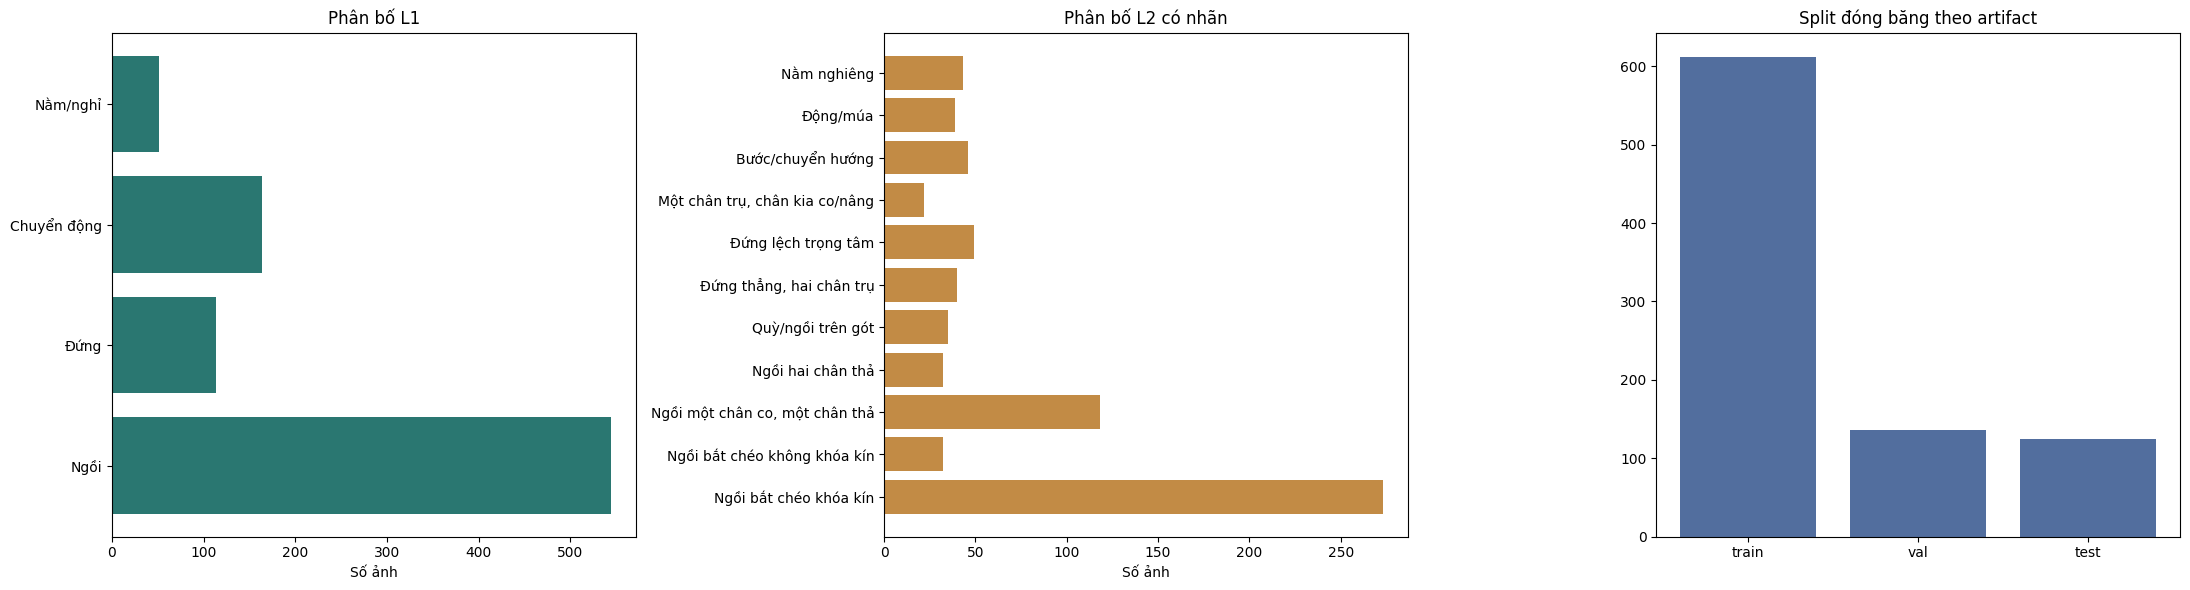

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(22, 6))
l1_counts = Counter(row["level_1_code"] for row in rows)
l2_counts = Counter(row["level_2_code"] for row in rows if row["level_2_code"])
axes[0].barh([l1_names_vi[c] for c in indices["l1_codes"]], [l1_counts[c] for c in indices["l1_codes"]], color="#2a7771")
axes[0].set_title("Phân bố L1")
axes[0].set_xlabel("Số ảnh")
axes[1].barh([l2_names_vi[c] for c in indices["l2_codes"]], [l2_counts[c] for c in indices["l2_codes"]], color="#c28b45")
axes[1].set_title("Phân bố L2 có nhãn")
axes[1].set_xlabel("Số ảnh")
split_order = ["train", "val", "test"]
axes[2].bar(split_order, [audit["split_counts"][s] for s in split_order], color="#526e9e")
axes[2].set_title("Split đóng băng theo artifact")
plt.tight_layout()
plt.show()


**Giải thích và giới hạn.** So sánh tần suất lớp giữa train, validation và test. Lớp có ít mẫu mang độ bất định lớn; tăng số lần lấy mẫu không bổ sung đa dạng thị giác.


## 6. Đánh giá mức đồng thuận gán nhãn

Cell ghép các bản gán nhãn theo cùng định danh mẫu, sau đó tính tỷ lệ trùng nhãn và hệ số kappa. Tỷ lệ trùng nhãn mô tả đồng thuận trực tiếp; kappa điều chỉnh phần đồng thuận có thể xảy ra ngẫu nhiên theo phân bố nhãn. Ma trận đối chiếu giúp xác định những cặp nhãn còn gây bất đồng.

{
  "annotators": [
    "Ngan",
    "My"
  ],
  "n_paired": 873,
  "hierarchical_exact_agreement": 0.9702176403207331,
  "hierarchical_cohen_kappa": 0.9652345724394614,
  "l1_agreement": 1.0,
  "l1_cohen_kappa": 1.0,
  "pairing_key": "image_id"
}


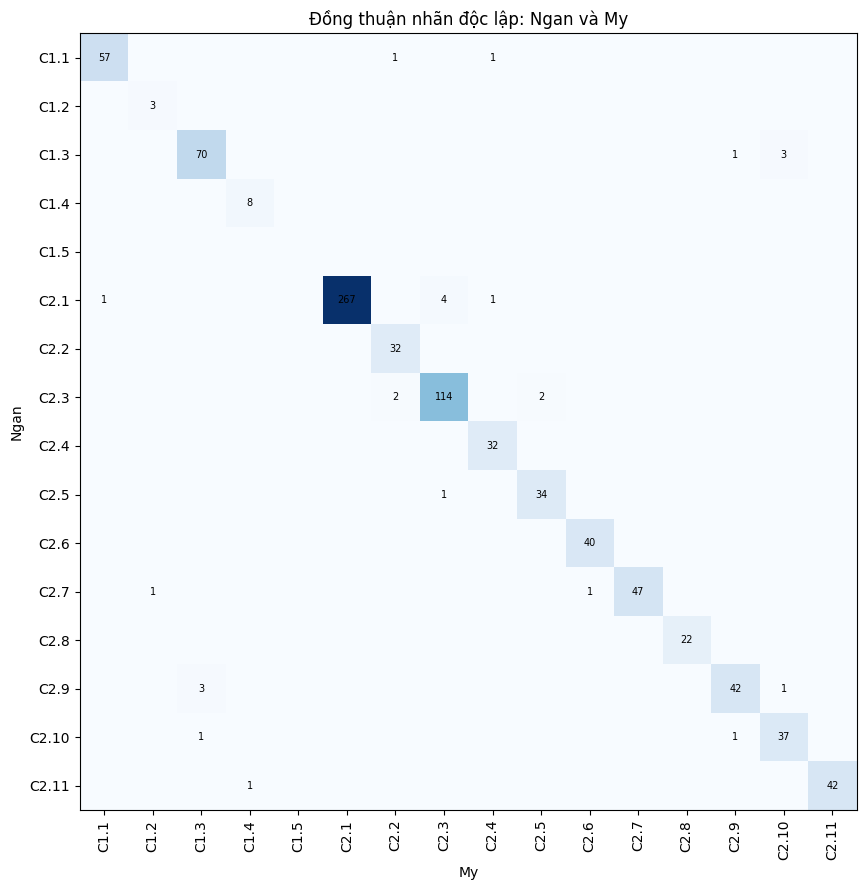

In [6]:
def read_rater_form(path):
    ws = load_workbook(path, data_only=True, read_only=False)["Form"]
    values = {}
    for row_number in range(5, ws.max_row + 1):
        image_id = ws.cell(row_number, 1).value
        label = ws.cell(row_number, 3).value
        if image_id is None and label is None:
            continue
        if image_id is None or label is None:
            raise ValueError(f"Dòng thiếu image_id hoặc label tại {path.name}:{row_number}")
        image_id, label = str(image_id).strip(), str(label).strip()
        if image_id in values:
            raise ValueError(f"Trùng image_id trong {path.name}: {image_id}")
        values[image_id] = label
    return values

ngan_path = RATINGS_DIR / "kappa_form_rater_ngan.xlsx"
my_path = RATINGS_DIR / "kappa_form_rater_my.xlsx"
if not ngan_path.is_file() or not my_path.is_file():
    raise FileNotFoundError(f"Thiếu phiếu gán nhãn: Ngan={ngan_path.is_file()}, My={my_path.is_file()}")
labels_ngan = read_rater_form(ngan_path)
labels_my = read_rater_form(my_path)
assert set(labels_ngan) == set(labels_my), "Phiếu của Ngan và My không có cùng tập image_id."
assert len(labels_ngan) == 873, len(labels_ngan)

valid_codes = set(indices["l1_codes"]) | {"C1.5"} | set(indices["l2_codes"])
invalid_ngan = sorted({v for v in labels_ngan.values() if v not in valid_codes})
invalid_my = sorted({v for v in labels_my.values() if v not in valid_codes})
assert not invalid_ngan and not invalid_my, {"Ngan": invalid_ngan, "My": invalid_my}

common_ids = sorted(labels_ngan)
y_ngan = [labels_ngan[i] for i in common_ids]
y_my = [labels_my[i] for i in common_ids]
to_l1 = lambda code: indices["l2_parent"].get(code, code)
y_ngan_l1 = [to_l1(code) for code in y_ngan]
y_my_l1 = [to_l1(code) for code in y_my]

kappa_summary = {
    "annotators": ["Ngan", "My"],
    "n_paired": len(common_ids),
    "hierarchical_exact_agreement": float(np.mean(np.array(y_ngan) == np.array(y_my))),
    "hierarchical_cohen_kappa": float(cohen_kappa_score(y_ngan, y_my)),
    "l1_agreement": float(np.mean(np.array(y_ngan_l1) == np.array(y_my_l1))),
    "l1_cohen_kappa": float(cohen_kappa_score(y_ngan_l1, y_my_l1)),
    "pairing_key": "image_id",
}
(RUN_ROOT / "inter_rater_agreement.json").write_text(json.dumps(kappa_summary, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(kappa_summary, ensure_ascii=False, indent=2))

all_codes = indices["l1_codes"] + ["C1.5"] + indices["l2_codes"]
cm = confusion_matrix(y_ngan, y_my, labels=all_codes)
fig, ax = plt.subplots(figsize=(11, 9))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(all_codes)), all_codes, rotation=90)
ax.set_yticks(range(len(all_codes)), all_codes)
ax.set_xlabel("My")
ax.set_ylabel("Ngan")
ax.set_title("Đồng thuận nhãn độc lập: Ngan và My")
for i in range(len(all_codes)):
    for j in range(len(all_codes)):
        if cm[i, j]: ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=7)
plt.tight_layout()
plt.show()


**Giải thích và giới hạn.** Kappa đo mức đồng thuận gán nhãn sau khi loại ảnh hưởng trùng ngẫu nhiên. Đồng thuận cao chưa đủ chứng minh mô hình phân loại tốt.


## 7. Huấn luyện và lựa chọn mô hình ảnh

Huấn luyện cả ba kiến trúc bằng cùng bộ hàm và ba seed, sau đó so sánh tổ hợp theo kiến trúc và tổ hợp tất cả trên validation. Checkpoint, xác suất hiệu chỉnh và ngưỡng đều thuộc lần chạy hiện tại. ConvNeXt là một ứng viên, không được mặc định chọn chỉ vì kiến trúc mới hơn.


In [7]:
seed_everything(SEED)
image_run_dir = RUN_ROOT / "image_classifier"
image_run_dir.mkdir(parents=True, exist_ok=True)
loaders, indices = make_loaders(snapshot, batch_size=IMAGE_BATCH_SIZE, seed=SEED)
image_trials, member_outputs, raw_member_outputs, all_members = {}, {}, {}, []
for architecture in IMAGE_ARCHITECTURES:
    for training_seed in IMAGE_SEEDS:
        name = f"{architecture}_seed{training_seed}"
        result = fit_model(snapshot, architecture, image_run_dir / name,
                           epochs=IMAGE_MAX_EPOCHS, patience=IMAGE_PATIENCE,
                           batch_size=IMAGE_BATCH_SIZE, seed=training_seed)
        raw = result["validation_outputs"]
        temperatures = fit_hierarchical_temperatures(raw, indices)
        member = {"architecture": architecture, "seed": training_seed, "checkpoint": result["checkpoint"],
                  "temperatures": temperatures, "best_epoch": result["best_epoch"]}
        all_members.append(member)
        raw_member_outputs[name] = raw
        member_outputs[name] = apply_temperatures(raw, temperatures)
        image_trials[name] = {k: v for k, v in result.items() if k not in ("validation_outputs", "history")}

# Fixed groups: no cherry-picking the best seed. Compare each architecture's three-seed
# ensemble and the equally weighted six-member ensemble, all on validation only.
image_groups = {architecture: [m for m in all_members if m["architecture"] == architecture] for architecture in IMAGE_ARCHITECTURES}
image_groups["all_architectures"] = all_members
image_group_trials = {}
for name, members in image_groups.items():
    member_names = [f"{m['architecture']}_seed{m['seed']}" for m in members]
    out = average_hierarchical_outputs([member_outputs[n] for n in member_names], indices)
    _, l1_choice = l1_rejection_curve(out, min_coverage=L1_MIN_COVERAGE, min_accepted=L1_MIN_ACCEPTED,
                                     target_accuracy=L1_TARGET_SELECTIVE_ACCURACY)
    t2, te, tc, choice = select_unified_operating_points(out, indices, l1_choice["threshold"])
    quality = decision_quality(out, indices, l1_choice["threshold"], t2, te, tc)
    image_group_trials[name] = {"outputs": out, "quality": quality, "l1_choice": l1_choice,
                                "threshold": t2, "evidence_threshold": te, "class_thresholds": tc, "threshold_choice": choice}
image_architecture = max(image_group_trials, key=lambda name: image_group_trials[name]["quality"]["score"])
chosen = image_group_trials[image_architecture]
image_members = image_groups[image_architecture]
image_val_outputs = chosen["outputs"]
image_val_outputs_raw = average_hierarchical_outputs(
    [raw_member_outputs[f"{m['architecture']}_seed{m['seed']}"] for m in image_members], indices)
image_l1_curve_rows, image_l1_choice = l1_rejection_curve(
    image_val_outputs, min_coverage=L1_MIN_COVERAGE, min_accepted=L1_MIN_ACCEPTED,
    target_accuracy=L1_TARGET_SELECTIVE_ACCURACY)
image_l1_threshold = float(image_l1_choice["threshold"])
image_threshold, image_l2_evidence_threshold = chosen["threshold"], chosen["evidence_threshold"]
image_class_thresholds, threshold_choice = chosen["class_thresholds"], chosen["threshold_choice"]
image_c2_2_choice = threshold_choice["per_class"]["C2.2"]
image_temperatures = {"per_member": [m["temperatures"] for m in image_members]}
image_checkpoint = Path(image_members[0]["checkpoint"])
image_selection = {
    "source": "unified_image_comparison", "architecture": image_architecture, "model_schema": MODEL_SCHEMA,
    "image_size": IMAGE_SIZE, "members": image_members, "manifest_sha256": audit["manifest_sha256"],
    "validation_selection_score": chosen["quality"]["score"],
    "group_comparison": {k: v["quality"] for k, v in image_group_trials.items()},
    "l1_rejection_threshold": image_l1_threshold, "l1_threshold_choice": image_l1_choice,
    "threshold": image_threshold, "l2_fallback_threshold": image_threshold,
    "l2_evidence_threshold": image_l2_evidence_threshold,
    "class_specific_thresholds": image_class_thresholds, "c2_2_threshold_choice": image_c2_2_choice,
    "threshold_choice": threshold_choice, "temperature_scaling": image_temperatures,
}
(image_run_dir / "selection.json").write_text(json.dumps(image_selection, ensure_ascii=False, indent=2), encoding="utf-8")
display(pd.DataFrame([{ "group": name, **trial["quality"], "calibration": trial["threshold_choice"].get("calibration") }
                      for name, trial in image_group_trials.items()]).drop(columns=["per_class"]))
print("Đã khóa lựa chọn nhánh ảnh trên validation:", image_architecture)


resnet18 seed=20261021 epoch=1 batch=40/306
resnet18 seed=20261021 epoch=1 batch=80/306
resnet18 seed=20261021 epoch=1 batch=120/306
resnet18 seed=20261021 epoch=1 batch=160/306
resnet18 seed=20261021 epoch=1 batch=200/306
resnet18 seed=20261021 epoch=1 batch=240/306
resnet18 seed=20261021 epoch=1 batch=280/306
resnet18 seed=20261021 epoch=1/100 loss=3.9818 val score=0.1811 best=0.1811
resnet18 seed=20261021 epoch=2 batch=40/306
resnet18 seed=20261021 epoch=2 batch=80/306
resnet18 seed=20261021 epoch=2 batch=120/306
resnet18 seed=20261021 epoch=2 batch=160/306
resnet18 seed=20261021 epoch=2 batch=200/306
resnet18 seed=20261021 epoch=2 batch=240/306
resnet18 seed=20261021 epoch=2 batch=280/306
resnet18 seed=20261021 epoch=2/100 loss=3.7780 val score=0.1915 best=0.1915
resnet18 seed=20261021 epoch=3 batch=40/306
resnet18 seed=20261021 epoch=3 batch=80/306
resnet18 seed=20261021 epoch=3 batch=120/306
resnet18 seed=20261021 epoch=3 batch=160/306
resnet18 seed=20261021 epoch=3 batch=200/306

,group,score,l1_macro_f1,l2_end_to_end_macro_f1,calibration
0,resnet18,0.588298,0.876970,0.299626,per_class
1,mobilenet_v2,0.531913,0.817906,0.245921,per_class
2,convnext_tiny,0.545194,0.838885,0.251503,per_class
3,all_architectures,0.533776,0.858961,0.208592,per_class


Đã khóa lựa chọn nhánh ảnh trên validation: resnet18


**Giải thích và giới hạn.** Bảng này chỉ có kết quả validation. Theo dõi đồng thời macro-F1 L1, L2 toàn quy trình và độ chính xác của các quyết định L2. Mô hình mạnh hơn có thể tăng nhận diện nhãn hiếm nhưng cũng tăng nhầm lẫn; kết luận dựa vào số liệu sau khi chạy.


## 8. Phân tích dự đoán trên validation

Đọc ma trận nhầm lẫn L1 và L2 với L1 chuẩn trên validation. Không mở test để điều chỉnh mô hình hoặc ngưỡng ở giai đoạn này.


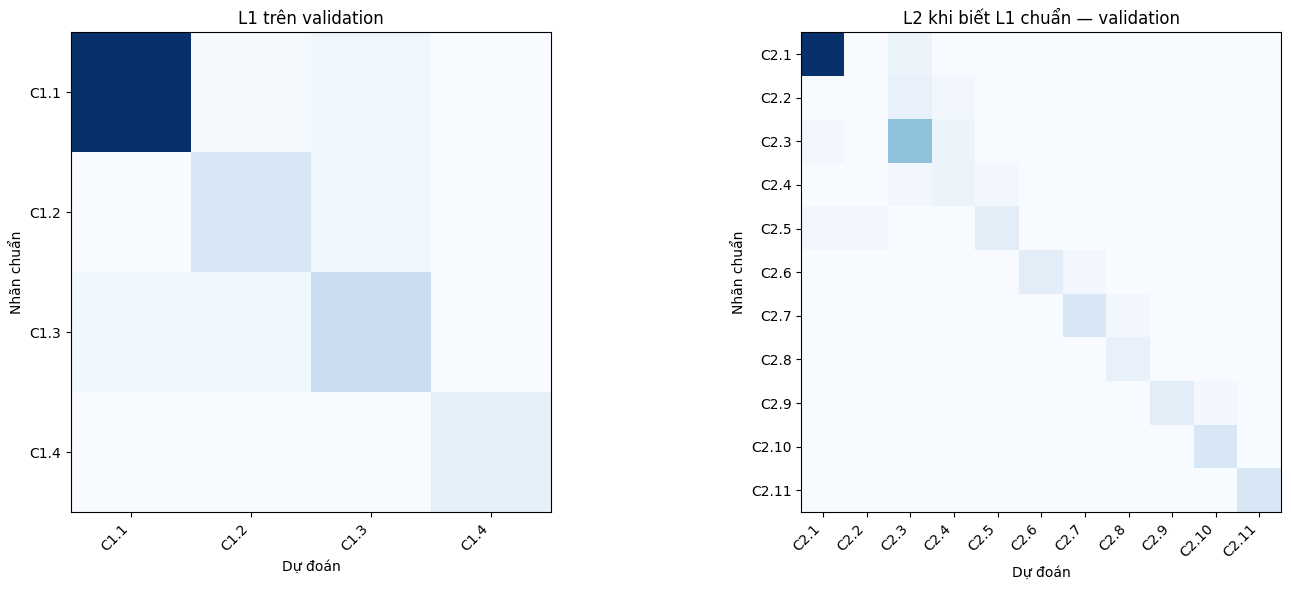

In [8]:
# Chỉ đọc validation tại giai đoạn chọn mô hình; test được đánh giá sau khi khóa cả hai nhánh.
validation_metrics = metrics_from_outputs(image_val_outputs, indices)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, metric, labels, title in [
    (axes[0], validation_metrics["l1"], indices["l1_codes"], "L1 trên validation"),
    (axes[1], validation_metrics["l2_oracle_given_gold_l1"], indices["l2_codes"], "L2 khi biết L1 chuẩn — validation")]:
    matrix = np.asarray(metric["confusion_matrix"])
    ax.imshow(matrix, cmap="Blues")
    ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right")
    ax.set_yticks(range(len(labels)), labels)
    ax.set_title(title); ax.set_xlabel("Dự đoán"); ax.set_ylabel("Nhãn chuẩn")
plt.tight_layout(); plt.show()


**Giải thích và giới hạn.** Sai L1 làm mô hình đi vào nhánh con sai. Kết quả L2 khi biết L1 chuẩn chỉ đo khả năng phân biệt trong nhánh, không thay thế chất lượng L2 toàn quy trình.


## 9. Chuẩn bị dữ liệu ước lượng điểm khớp

Cell chuyển dữ liệu ảnh, hộp giới hạn và điểm khớp sang định dạng huấn luyện YOLO Pose, đồng thời giữ phép chia tập đã xác định. Điểm khớp được đánh dấu theo mức nhìn thấy hoặc khả năng định vị. Dữ liệu chuẩn bị ở bước này phục vụ học hình học cơ thể, chưa phải đầu ra phân loại tư thế L1/L2.

In [9]:
def safe_stem(text):
    return "".join(ch if ch.isalnum() or ch in "-_" else "_" for ch in text)

def build_pose_dataset(data_dir, manifest_rows, coco, output_dir):
    marker = output_dir / "dataset.yaml"
    if marker.is_file() and REUSE_EXISTING:
        return marker
    if output_dir.exists():
        shutil.rmtree(output_dir)
    row_by_image = {row["image_id"]: row for row in manifest_rows}
    image_by_id = {int(image["id"]): image for image in coco["images"]}
    anns_by_image = {int(ann["image_id"]): ann for ann in coco["annotations"]}
    records = []
    for image_id, image in image_by_id.items():
        ann = anns_by_image[image_id]
        original_id = image["original_image_id"]
        if original_id not in row_by_image:
            raise KeyError(f"Không ghép được COCO image với manifest: {original_id}")
        row = row_by_image[original_id]
        split = "val" if row["split"] == "val" else row["split"]
        image_dir = output_dir / "images" / split
        label_dir = output_dir / "labels" / split
        image_dir.mkdir(parents=True, exist_ok=True)
        label_dir.mkdir(parents=True, exist_ok=True)
        source = data_dir / row["crop_path"]
        stem = safe_stem(row["instance_id"])
        destination = image_dir / (stem + source.suffix.lower())
        shutil.copy2(source, destination)
        crop_x, crop_y, crop_w, crop_h = json.loads(row["crop_extent_xywh"])
        bbox_x, bbox_y, bbox_w, bbox_h = [float(ann["bbox"][i]) for i in range(4)]
        xc = ((bbox_x - crop_x) + bbox_w / 2) / crop_w
        yc = ((bbox_y - crop_y) + bbox_h / 2) / crop_h
        bw, bh = bbox_w / crop_w, bbox_h / crop_h
        yolo_fields = [0, np.clip(xc, 0, 1), np.clip(yc, 0, 1), np.clip(bw, 1e-6, 1), np.clip(bh, 1e-6, 1)]
        adjusted_gt = []
        kp = ann["keypoints"]
        for index in range(0, len(kp), 3):
            x, y, visibility = float(kp[index]), float(kp[index + 1]), int(kp[index + 2])
            xn, yn = (x - crop_x) / crop_w, (y - crop_y) / crop_h
            if visibility > 0 and not (0 <= xn <= 1 and 0 <= yn <= 1):
                visibility = 0
            xn, yn = float(np.clip(xn, 0, 1)), float(np.clip(yn, 0, 1))
            yolo_fields.extend([xn, yn, visibility])
            adjusted_gt.append([xn, yn, visibility])
        (label_dir / (stem + ".txt")).write_text(" ".join(map(str, yolo_fields)) + "\n", encoding="utf-8")
        records.append({"image_id": original_id, "instance_id": row["instance_id"], "split": row["split"],
                        "file": str(destination), "bbox_norm": [xc, yc, bw, bh], "keypoints_norm": adjusted_gt})
    yaml_text = (
        f'path: "{output_dir.resolve().as_posix()}"\n'
        "train: images/train\nval: images/val\ntest: images/test\n"
        "kpt_shape: [17, 3]\n"
        "flip_idx: [0, 2, 1, 4, 3, 6, 5, 8, 7, 10, 9, 12, 11, 14, 13, 16, 15]\n"
        "names:\n  0: figure\n"
    )
    marker.write_text(yaml_text, encoding="utf-8")
    (output_dir / "records.json").write_text(json.dumps(records, ensure_ascii=False, indent=2), encoding="utf-8")
    return marker

pose_dataset_dir = CACHE_DIR / "formal_pose_yolo"
pose_yaml = build_pose_dataset(DATA_DIR, rows, full_coco, pose_dataset_dir)
pose_records = json.loads((pose_dataset_dir / "records.json").read_text(encoding="utf-8"))
print("Pose records:", len(pose_records), Counter(r["split"] for r in pose_records))


Pose records: 612 Counter({'train': 442, 'val': 88, 'test': 82})


**Giải thích và giới hạn.** Đối chiếu số ảnh và điểm khớp được xuất với dữ liệu nguồn. Mẫu thiếu keypoint có thể không tham gia huấn luyện pose nhưng vẫn dùng được cho phân loại ảnh.


## 10. Nạp hoặc huấn luyện bộ ước lượng tư thế

Cell kiểm tra điều kiện tái sử dụng mô hình tư thế đã lưu. Nếu có mô hình phù hợp với dữ liệu và cấu hình kiểm tra, chương trình nạp lại để đánh giá; nếu cần huấn luyện mới, chương trình thực hiện nhánh huấn luyện tương ứng. Nguồn trọng số được ghi lại để tránh nhầm kết quả tái sử dụng với một thí nghiệm huấn luyện mới.

In [10]:
import gc
pose_inference_batch_size = globals().get("POSE_INFERENCE_BATCH_SIZE", 1)
pose_run_dir = RUN_ROOT / "pose_estimator"
pose_run_dir.mkdir(parents=True, exist_ok=True)
cached_pose_checkpoint = OUTPUTS_DIR / "pose_baseline" / "best.pt"
cached_pose_config = OUTPUTS_DIR / "pose_baseline" / "config.json"
pretrained_pose = PRETRAINED_DIR / "yolo11n-pose.pt"
if not pretrained_pose.is_file():
    raise FileNotFoundError("Thiếu pretrained/yolo11n-pose.pt. Không tự tải để giữ khả năng tái lập offline.")

can_reuse_pose = False
if REUSE_EXISTING and not FORCE_RETRAIN_POSE and cached_pose_checkpoint.is_file() and cached_pose_config.is_file():
    pose_cache_config = json.loads(cached_pose_config.read_text(encoding="utf-8"))
    can_reuse_pose = pose_cache_config.get("manifest_sha256") == audit["manifest_sha256"]
if can_reuse_pose:
    pose_checkpoint = cached_pose_checkpoint
    pose_training_source = "cached_formal_pose_baseline"
else:
    base_pose_model = YOLO(str(pretrained_pose))
    pose_result = base_pose_model.train(
        data=str(pose_yaml), epochs=POSE_EPOCHS, patience=POSE_PATIENCE,
        imgsz=POSE_IMAGE_SIZE, batch=POSE_BATCH_SIZE, seed=SEED,
        project=str(pose_run_dir.resolve()), name="yolo11n_pose_formal",
        device=0 if DEVICE == "cuda" else "cpu", workers=0,
        pretrained=True, deterministic=True, exist_ok=False, verbose=True,
    )
    pose_save_dir = Path(pose_result.save_dir)
    pose_checkpoint = pose_save_dir / "weights" / "best.pt"
    if not pose_checkpoint.is_file():
        pose_checkpoint = pose_save_dir / "weights" / "last.pt"
    cached_pose_checkpoint.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(pose_checkpoint, cached_pose_checkpoint)
    cached_pose_config.write_text(json.dumps({
        "dataset_version": audit["dataset_version"],
        "manifest_sha256": audit["manifest_sha256"],
        "seed": SEED, "epochs": POSE_EPOCHS, "imgsz": POSE_IMAGE_SIZE,
        "batch": POSE_BATCH_SIZE, "base_weights": pretrained_pose.name,
    }, ensure_ascii=False, indent=2), encoding="utf-8")
    pose_checkpoint = cached_pose_checkpoint
    pose_training_source = "trained_in_notebook"

# The 4 GB GPU cannot hold the image classifier and YOLO-Pose validation
# buffers at the same time. Keep the already-evaluated image model on CPU;
# it is only used once more by the final demo.
if DEVICE == "cuda":
    gc.collect()
    torch.cuda.empty_cache()

pose_model = YOLO(str(pose_checkpoint))
pose_val_result = pose_model.val(
    project=str(pose_run_dir.resolve()), name="geometry_test", exist_ok=True,
    data=str(pose_yaml), split="test", imgsz=POSE_IMAGE_SIZE,
    batch=pose_inference_batch_size, device=0 if DEVICE == "cuda" else "cpu",
    half=DEVICE == "cuda",
    workers=0, verbose=False,
)
pose_ultralytics_metrics = {
    "training_source": pose_training_source,
    "checkpoint": str(pose_checkpoint),
    "pose_map50_95": float(getattr(pose_val_result.pose, "map", float("nan"))),
    "pose_map50": float(getattr(pose_val_result.pose, "map50", float("nan"))),
    "pose_map75": float(getattr(pose_val_result.pose, "map75", float("nan"))),
    "box_map50_95": float(getattr(pose_val_result.box, "map", float("nan"))),
}
del pose_val_result
# Validation builds an inference backend. Reload a clean checkpoint for
# feature extraction instead of moving that backend between devices.
del pose_model
gc.collect()
if DEVICE == "cuda":
    torch.cuda.empty_cache()
pose_model = YOLO(str(pose_checkpoint))
print(json.dumps(pose_ultralytics_metrics, ensure_ascii=False, indent=2))


Ultralytics 8.3.215  Python-3.10.11 torch-2.10.0+cu126 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
YOLO11n-pose summary (fused): 109 layers, 2,866,468 parameters, 0 gradients, 7.4 GFLOPs
val: Fast image access  (ping: 0.20.1 ms, read: 29.511.7 MB/s, size: 318.3 KB)
val: Scanning I:\nam4\phan tich anh phat giao\training\Thangka_Pose_Training\cache\formal_pose_yolo\labels\test.cache... 82 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 82/82  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Pose(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 82/82 1.3it/s 1:020.7sss
                   all         82         82      0.997          1      0.995      0.958      0.973      0.976      0.984       0.79
Speed: 1.7ms preprocess, 698.7ms inference, 0.0ms loss, 4.3ms postprocess per image
Results saved to I:\nam4\phan tich anh phat giao\training\Thangka_Pose_Training\outputs\notebook_runs\20261103_101754_seed20261021\pose_estimat

**Giải thích và giới hạn.** Đọc nguồn checkpoint để phân biệt nạp lại với huấn luyện mới. Tái sử dụng pose không phải bằng chứng PCK/OKS được cải thiện trong lần chạy này.


## 11. Trích xuất điểm khớp dự đoán

Mô hình tư thế được áp dụng để tạo dữ liệu điểm khớp dự đoán cho các tập. Kết quả được lưu vào bộ nhớ đệm nhằm tái sử dụng khi thử các bộ phân loại khác nhau. Cách làm này giúp đánh giá phân loại trên hình học mà mô hình thực sự suy ra từ ảnh.

In [11]:
import gc
pose_inference_batch_size = globals().get("POSE_INFERENCE_BATCH_SIZE", 1)
pose_feature_device = "cuda" if DEVICE == "cuda" else "cpu"

def _extract_pose_features_once(model, manifest_rows, batch_size, inference_device):
    # A list of paths makes this Ultralytics version decode every image up
    # front with LoadPilAndNumpy. Some source images are very large, so that
    # exhausts system RAM. Passing one path string at a time streams from disk.
    use_cuda = inference_device != "cpu"
    features, metadata = [], []
    total = len(manifest_rows)
    for index, row in enumerate(manifest_rows):
        path = str(DATA_DIR / row["crop_path"])
        results = model.predict(
            source=path, imgsz=POSE_IMAGE_SIZE, batch=1,
            device=inference_device, workers=0, half=use_cuda, max_det=1,
            verbose=False, stream=False,
        )
        if len(results) != 1:
            raise RuntimeError(f"Expected one pose result for {path}, got {len(results)}")
        result = results[0]
        feature = np.zeros(17 * 3 + 2, dtype=np.float32)
        detected = False
        if result.boxes is not None and len(result.boxes) and result.keypoints is not None:
            confs = result.boxes.conf.detach().cpu().numpy()
            best = int(np.argmax(confs))
            xy = result.keypoints.xyn[best].detach().cpu().numpy()
            if result.keypoints.conf is not None:
                kp_conf = result.keypoints.conf[best].detach().cpu().numpy()
            else:
                kp_conf = np.ones(17, dtype=np.float32)
            feature[:51] = np.column_stack([xy, kp_conf]).reshape(-1)
            feature[51] = float(confs[best])
            feature[52] = 1.0
            detected = True
            bbox_xywhn = result.boxes.xywhn[best].detach().cpu().numpy().astype(float).tolist()
        else:
            bbox_xywhn = None
        features.append(feature)
        metadata.append({"image_id": row["image_id"], "instance_id": row["instance_id"],
                         "split": row["split"], "detected": detected,
                         "bbox_xywhn": bbox_xywhn})
        del result, results
        if (index + 1) % 50 == 0 or index + 1 == total:
            print(f"Pose inference: {index + 1}/{total}")
    return np.stack(features), metadata

def extract_pose_features(model, manifest_rows, batch_size=1):
    global pose_model, pose_feature_device
    inference_device = 0 if DEVICE == "cuda" else "cpu"
    if DEVICE == "cuda":
        gc.collect()
        torch.cuda.empty_cache()
    try:
        return _extract_pose_features_once(model, manifest_rows, batch_size, inference_device)
    except RuntimeError as exc:
        if DEVICE != "cuda" or "out of memory" not in str(exc).lower():
            raise
        warnings.warn("GPU thiếu bộ nhớ khi trích keypoint; nạp lại checkpoint sạch và tiếp tục trên CPU.")
        model.predictor = None
        del model
        gc.collect()
        torch.cuda.empty_cache()
        pose_model = YOLO(str(pose_checkpoint))
        pose_feature_device = "cpu"
        return _extract_pose_features_once(pose_model, manifest_rows, 1, "cpu")

pose_feature_cache = CACHE_DIR / "predicted_pose_features.npz"
pose_metadata_cache = CACHE_DIR / "predicted_pose_metadata.json"
def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

pose_checkpoint_sha256 = file_sha256(pose_checkpoint)
pose_cache_metadata = (json.loads(pose_metadata_cache.read_text(encoding="utf-8"))
                       if pose_metadata_cache.is_file() else {})
can_reuse_features = (
    REUSE_EXISTING and not FORCE_RETRAIN_POSE and pose_feature_cache.is_file()
    and pose_cache_metadata.get("checkpoint_sha256") == pose_checkpoint_sha256
    and pose_cache_metadata.get("manifest_sha256") == audit["manifest_sha256"]
    and pose_cache_metadata.get("record_count") == len(rows)
    and pose_cache_metadata.get("cache_schema") == 2
)
if can_reuse_features:
    pose_features = np.load(pose_feature_cache)["features"]
    pose_feature_metadata = pose_cache_metadata["records"]
else:
    # Release allocations and traceback frames left by earlier failed runs.
    for attr in ("last_traceback", "last_value", "last_type"):
        if hasattr(sys, attr):
            setattr(sys, attr, None)
    if DEVICE == "cuda":
        pose_model.predictor = None
        gc.collect()
        torch.cuda.empty_cache()
    # Running this cell again must not reuse the backend left by val() or a failed inference.
    del pose_model
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    pose_model = YOLO(str(pose_checkpoint))
    pose_features, pose_feature_metadata = extract_pose_features(
        pose_model, rows, pose_inference_batch_size
    )
    CACHE_DIR.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(pose_feature_cache, features=pose_features)
    pose_metadata_cache.write_text(json.dumps({
        "checkpoint_sha256": pose_checkpoint_sha256,
        "manifest_sha256": audit["manifest_sha256"],
        "record_count": len(rows),
        "cache_schema": 2,
        "records": pose_feature_metadata,
    }, ensure_ascii=False, indent=2), encoding="utf-8")
assert len(pose_features) == len(rows)
print("Tỷ lệ phát hiện nhân vật:", np.mean([m["detected"] for m in pose_feature_metadata]))


Tỷ lệ phát hiện nhân vật: 1.0


**Giải thích và giới hạn.** Tỷ lệ phát hiện phản ánh việc tìm được đối tượng, không khẳng định vị trí mọi khớp đúng. Cache chỉ được dùng khi dữ liệu và nguồn mô hình tương thích.


## 12. Đánh giá độ chính xác hình học

Cell so sánh điểm khớp dự đoán với nhãn chuẩn bằng PCK và OKS. PCK đo tỷ lệ điểm nằm trong khoảng sai số cho phép; OKS tổng hợp mức tương đồng vị trí có xét quy mô đối tượng và độ nhạy theo loại khớp. Phiên bản chỉ số hiện tại tính trong tọa độ pixel, sử dụng diện tích hộp giới hạn làm đại diện quy mô và hệ số COCO `(2σ)²` cho OKS.

Phép tính dùng các khớp có cờ nhãn lớn hơn 0, bao gồm cả khớp bị che nhưng vẫn định vị được. Bảng theo lớp và vùng thân dưới giúp kiểm tra liệu chỉ số trung bình có che khuất sai số ở những tư thế khó hay không.

{
  "training_source": "cached_formal_pose_baseline",
  "checkpoint": "I:\\nam4\\phan tich anh phat giao\\training\\Thangka_Pose_Training\\outputs\\pose_baseline\\best.pt",
  "pose_map50_95": 0.7897520854580917,
  "pose_map50": 0.9841986531986531,
  "pose_map75": 0.8566573065759272,
  "box_map50_95": 0.9578562282250932,
  "test_full_keypoint_images": 82,
  "test_detection_rate": 1.0,
  "mean_bbox_iou": 0.8538573000002392,
  "pck_at_0_05_bbox_diagonal": 0.7862266857962698,
  "pck_visible_keypoints": 1394,
  "mean_oks": 0.8852506298351936,
  "oks_definition": "COCO (2*sigma)^2; pixel coordinates; bbox-area proxy; annotated ground-truth keypoints (v>0); metric schema 2, not comparable directly with old normalized-space scores"
}


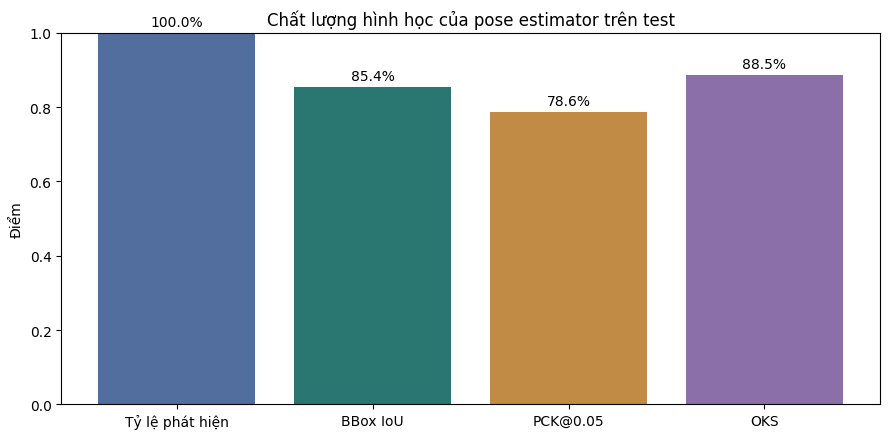

In [12]:
COCO_SIGMAS = np.array([.26, .25, .25, .35, .35, .79, .79, .72, .72, .62, .62, 1.07, 1.07, .87, .87, .89, .89]) / 10.0
def bbox_iou_xywhn(a, b):
    ax, ay, aw, ah = map(float, a); bx, by, bw, bh = map(float, b)
    a_box = [ax - aw / 2, ay - ah / 2, ax + aw / 2, ay + ah / 2]
    b_box = [bx - bw / 2, by - bh / 2, bx + bw / 2, by + bh / 2]
    inter_w = max(0.0, min(a_box[2], b_box[2]) - max(a_box[0], b_box[0]))
    inter_h = max(0.0, min(a_box[3], b_box[3]) - max(a_box[1], b_box[1]))
    intersection = inter_w * inter_h
    union = aw * ah + bw * bh - intersection
    return intersection / union if union > 0 else 0.0

gt_pose_by_image = {record["image_id"]: record for record in pose_records if record["split"] == "test"}
feature_by_image = {row["image_id"]: pose_features[i] for i, row in enumerate(rows)}
metadata_by_image = {record["image_id"]: record for record in pose_feature_metadata}
pck_hits, pck_total, oks_values, bbox_ious, detected_pose_test = 0, 0, [], [], 0
for image_id, gt in gt_pose_by_image.items():
    feature = feature_by_image[image_id]
    if feature[52] > 0:
        detected_pose_test += 1
        predicted_bbox = metadata_by_image[image_id].get("bbox_xywhn")
        if predicted_bbox is not None:
            bbox_ious.append(bbox_iou_xywhn(gt["bbox_norm"], predicted_bbox))
    pred = feature[:51].reshape(17, 3)
    gt_kp = np.array(gt["keypoints_norm"], dtype=float)
    visible = gt_kp[:, 2] > 0
    if not visible.any():
        continue
    row = next(r for r in rows if r["image_id"] == image_id)
    crop_size = (float(row["crop_width"]), float(row["crop_height"]))
    hits, visible, oks = pose_geometry_scores(pred, gt_kp, gt["bbox_norm"], crop_size)
    pck_hits += int(hits.sum())
    pck_total += int(visible.sum())
    if oks is not None:
        oks_values.append(oks)

pose_geometry_metrics = {
    **pose_ultralytics_metrics,
    "test_full_keypoint_images": len(gt_pose_by_image),
    "test_detection_rate": detected_pose_test / max(len(gt_pose_by_image), 1),
    "mean_bbox_iou": float(np.mean(bbox_ious)) if bbox_ious else None,
    "pck_at_0_05_bbox_diagonal": pck_hits / max(pck_total, 1),
    "pck_visible_keypoints": pck_total,
    "mean_oks": float(np.mean(oks_values)) if oks_values else None,
    "oks_definition": "COCO (2*sigma)^2; pixel coordinates; bbox-area proxy; annotated ground-truth keypoints (v>0); metric schema 2, not comparable directly with old normalized-space scores",
}
(pose_run_dir / "test_pose_metrics.json").write_text(json.dumps(pose_geometry_metrics, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(pose_geometry_metrics, ensure_ascii=False, indent=2))
pose_plot_values = {
    "Tỷ lệ phát hiện": pose_geometry_metrics["test_detection_rate"],
    "BBox IoU": pose_geometry_metrics["mean_bbox_iou"] or 0.0,
    "PCK@0.05": pose_geometry_metrics["pck_at_0_05_bbox_diagonal"],
    "OKS": pose_geometry_metrics["mean_oks"] or 0.0,
}
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(pose_plot_values.keys(), pose_plot_values.values(), color=["#526e9e", "#2a7771", "#c28b45", "#8b6fa8"])
ax.set_ylim(0, 1); ax.set_ylabel("Điểm"); ax.set_title("Chất lượng hình học của pose estimator trên test")
ax.bar_label(bars, labels=[f"{value:.1%}" for value in pose_plot_values.values()], padding=3)
plt.tight_layout()
plt.show()

# Per-class validation diagnostics reveal whether hip/knee/ankle geometry is the bottleneck.
pose_diagnostics = []
row_by_image = {r["image_id"]: r for r in rows}
for gt in pose_records:
    if gt["split"] not in ("val", "test"):
        continue
    row = row_by_image[gt["image_id"]]
    pred = feature_by_image[gt["image_id"]][:51].reshape(17, 3)
    hits, visible, oks = pose_geometry_scores(pred, gt["keypoints_norm"], gt["bbox_norm"],
                                             (row["crop_width"], row["crop_height"]))
    pose_diagnostics.append({"image_id": gt["image_id"], "split": gt["split"], "l2_code": row["level_2_code"],
                             "lower_body_hits": int(hits[11:17].sum()), "lower_body_support": int(visible[11:17].sum()),
                             "pck_hits": int(hits.sum()), "pck_support": int(visible.sum()), "oks_bbox_area": oks})
pd.DataFrame(pose_diagnostics).to_csv(pose_run_dir / "geometry_by_image.csv", index=False)
pose_class_rows = []
for (split, code), group in pd.DataFrame(pose_diagnostics).groupby(["split", "l2_code"]):
    pose_class_rows.append({"split": split, "l2_code": code, "images": len(group),
                           "lower_body_pck": group.lower_body_hits.sum() / max(group.lower_body_support.sum(), 1),
                           "pck": group.pck_hits.sum() / max(group.pck_support.sum(), 1)})
pd.DataFrame(pose_class_rows).to_csv(pose_run_dir / "geometry_by_class.csv", index=False)


**Giải thích và giới hạn.** PCK, OKS và IoU chỉ phản ánh tập con có nhãn hình học chuẩn. Không suy rộng trực tiếp thành accuracy phân loại; sai khớp chân hoặc hông có thể ảnh hưởng đặc trưng tư thế.


## 13. Chọn nhánh keypoint, khóa phương án và đánh giá test

Huấn luyện bộ phân loại từ đặc trưng hình học COCO-17, so sánh với nhánh ảnh trên cùng validation và lựa chọn cách kết hợp. Sau khi lưu lựa chọn cố định, đánh giá cả hai hướng và phương án sử dụng trên cùng tập test.


In [13]:
def _joint_angle_cos(xy, confidence, first, middle, last):
    if min(confidence[first], confidence[middle], confidence[last]) < 0.05:
        return 0.0
    left = xy[first] - xy[middle]
    right = xy[last] - xy[middle]
    denominator = np.linalg.norm(left) * np.linalg.norm(right)
    return float(np.dot(left, right) / denominator) if denominator > 1e-8 else 0.0


def engineer_pose_features(raw_features):
    """Add translation/scale-invariant geometry while retaining original pose evidence."""
    raw_features = np.asarray(raw_features, dtype=np.float32)
    engineered = []
    for raw in raw_features:
        joints = raw[:51].reshape(17, 3)
        xy, confidence = joints[:, :2].copy(), joints[:, 2].copy()
        if len(raw) != 54 or not np.isfinite(raw[53]) or raw[53] <= 0:
            raise ValueError("Pose geometry requires 53 pose fields plus positive crop width/height ratio.")
        # x and y were normalized by DIFFERENT lengths. Restore isotropic geometry
        # before measuring angles; keep original normalized coordinates as separate features.
        xy[:, 0] *= raw[53]
        valid = confidence >= 0.05
        if valid[11] and valid[12]:
            center = (xy[11] + xy[12]) / 2.0
        elif valid.any():
            center = xy[valid].mean(axis=0)
        else:
            center = np.zeros(2, dtype=np.float32)
        if valid.any():
            span = xy[valid].max(axis=0) - xy[valid].min(axis=0)
            scale = max(float(np.linalg.norm(span)), 1e-3)
        else:
            scale = 1.0
        relative_xy = (xy - center) / scale
        relative_xy[~valid] = 0.0
        shoulder_mid = (xy[5] + xy[6]) / 2.0 if valid[5] and valid[6] else center
        hip_mid = (xy[11] + xy[12]) / 2.0 if valid[11] and valid[12] else center
        geometry = np.asarray([
            _joint_angle_cos(xy, confidence, 5, 11, 13),
            _joint_angle_cos(xy, confidence, 6, 12, 14),
            _joint_angle_cos(xy, confidence, 11, 13, 15),
            _joint_angle_cos(xy, confidence, 12, 14, 16),
            (shoulder_mid[0] - hip_mid[0]) / scale,
            (shoulder_mid[1] - hip_mid[1]) / scale,
            np.linalg.norm(xy[5] - xy[6]) / scale if valid[5] and valid[6] else 0.0,
            np.linalg.norm(xy[11] - xy[12]) / scale if valid[11] and valid[12] else 0.0,
            np.linalg.norm(xy[13] - xy[14]) / scale if valid[13] and valid[14] else 0.0,
            np.linalg.norm(xy[15] - xy[16]) / scale if valid[15] and valid[16] else 0.0,
            float(valid.mean()), float(confidence[valid].mean()) if valid.any() else 0.0,
        ], dtype=np.float32)
        engineered.append(np.concatenate([raw, relative_xy.reshape(-1), geometry]))
    return np.asarray(engineered, dtype=np.float32)


def augment_pose_training_data(raw_features, labels, seed, copies=1, include_original=True):
    rng = np.random.default_rng(seed)
    raw_features = np.asarray(raw_features, dtype=np.float32)
    labels = np.asarray(labels)
    feature_sets = [engineer_pose_features(raw_features)] if include_original else []
    label_sets = [labels] if include_original else []
    for _ in range(copies):
        noisy = raw_features.copy()
        joints = noisy[:, :51].reshape(-1, 17, 3)
        valid = joints[:, :, 2] >= 0.05
        jitter = rng.normal(0.0, 0.008, size=joints[:, :, :2].shape).astype(np.float32)
        joints[:, :, :2] += jitter * valid[:, :, None]
        joints[:, :, :2] = np.clip(joints[:, :, :2], 0.0, 1.0)
        # Mirror anatomy and image coordinates together; these labels are side-invariant.
        mirror = rng.random(len(joints)) < 0.5
        permutation = [0, 2, 1, 4, 3, 6, 5, 8, 7, 10, 9, 12, 11, 14, 13, 16, 15]
        reflected = joints[mirror][:, permutation, :].copy()
        reflected[:, :, 0] = np.where(reflected[:, :, 2] >= 0.05, 1.0 - reflected[:, :, 0], 0.0)
        joints[mirror] = reflected
        valid = joints[:, :, 2] >= 0.05
        drop = (rng.random(valid.shape) < 0.04) & valid
        joints[drop] = 0.0
        feature_sets.append(engineer_pose_features(noisy))
        label_sets.append(labels.copy())
    if not feature_sets:
        raise ValueError("At least one original or augmented copy is required.")
    return np.concatenate(feature_sets), np.concatenate(label_sets)


pose_classifier_features = np.column_stack([
    pose_features,
    np.asarray([float(row["crop_width"]) / float(row["crop_height"]) for row in rows], dtype=np.float32),
])
pose_geometry_features = engineer_pose_features(pose_classifier_features)
print("Số chiều đặc trưng keypoint sau chuẩn hóa hình học:", pose_geometry_features.shape[1])


def probability_matrix(model, X, codes):
    raw = model.predict_proba(X)
    if isinstance(raw, list):
        raise TypeError("Classifier phải trả một ma trận probability.")
    matrix = np.full((len(X), len(codes)), 1e-9, dtype=np.float64)
    class_to_index = {str(code): i for i, code in enumerate(model.classes_)}
    for j, code in enumerate(codes):
        key = str(code)
        if key in class_to_index:
            matrix[:, j] = raw[:, class_to_index[key]]
    matrix /= matrix.sum(axis=1, keepdims=True)
    return matrix

def outputs_from_classifiers(l1_model, l2_models, evidence_model, X, y1_codes=None, y2_codes=None):
    p1 = probability_matrix(l1_model, X, indices["l1_codes"])
    p2 = np.full((len(X), len(indices["l2_codes"])), 1e-9, dtype=np.float64)
    for parent_code in indices["l1_codes"]:
        child_codes = [code for code in indices["l2_codes"] if indices["l2_parent"][code] == parent_code]
        child_indices = [indices["l2_to_idx"][code] for code in child_codes]
        if len(child_codes) == 1:
            p2[:, child_indices[0]] = 1.0
        else:
            local = probability_matrix(l2_models[parent_code], X, child_codes)
            p2[:, child_indices] = local
    p_evidence = probability_matrix(evidence_model, X, [0, 1])
    outputs = {"l1_logits": np.log(np.clip(p1, 1e-9, 1)),
               "l2_logits": np.log(np.clip(p2, 1e-9, 1)),
               "l2_evidence_logits": np.log(np.clip(p_evidence, 1e-9, 1))}
    if y1_codes is not None:
        outputs["y1"] = np.asarray([indices["l1_to_idx"][code] for code in y1_codes], dtype=np.int64)
    if y2_codes is not None:
        outputs["y2"] = np.asarray([indices["l2_to_idx"].get(code, IGNORE_L2) for code in y2_codes], dtype=np.int64)
    return outputs

split_indices = {split: np.array([i for i, row in enumerate(rows) if row["split"] == split]) for split in ["train", "val", "test"]}
y_l1 = np.array([row["level_1_code"] for row in rows])
y_l2 = np.array([row["level_2_code"] for row in rows])
train_idx, val_idx, test_idx = split_indices["train"], split_indices["val"], split_indices["test"]
l2_train_idx = np.array([i for i in train_idx if y_l2[i]])

from sklearn.ensemble import ExtraTreesClassifier

candidates = {
    "logistic_regression": Pipeline([
        ("scale", StandardScaler()),
        ("model", LogisticRegression(max_iter=3000, random_state=SEED)),
    ]),
    "random_forest": RandomForestClassifier(
        n_estimators=500, min_samples_leaf=2,
        random_state=SEED, n_jobs=-1,
    ),
}
candidates["extra_trees"] = ExtraTreesClassifier(n_estimators=1000, min_samples_leaf=2, random_state=SEED, n_jobs=-1)
for regularization in [0.1, 10.0]:
    candidates[f"logistic_C{regularization}"] = Pipeline([
        ("scale", StandardScaler()),
        ("model", LogisticRegression(C=regularization, max_iter=5000, random_state=SEED)),
    ])

def inverse_sqrt_class_weights(y, boosts=None):
    labels, counts = np.unique(np.asarray(y), return_counts=True)
    if len(labels) == 0 or np.any(counts == 0):
        raise ValueError("Cannot compute class weights from an empty training split.")
    weights = 1.0 / np.power(counts.astype(np.float64), CLASS_WEIGHT_POWER)
    for i, label in enumerate(labels.tolist()):
        weights[i] *= float((boosts or {}).get(label, 1.0))
    weights /= weights.mean()
    return {label: float(weight) for label, weight in zip(labels.tolist(), weights)}

def fit_with_train_class_weights(estimator, X, y, boosts=None):
    model = clone(estimator)
    class_weights = inverse_sqrt_class_weights(y, boosts=boosts)
    if isinstance(model, Pipeline):
        model.set_params(model__class_weight=class_weights)
    else:
        model.set_params(class_weight=class_weights)
    model.fit(X, y)
    return model, class_weights

def fit_l2_branch_models(estimator, seed):
    branch_models, branch_weights = {}, {}
    for parent_offset, parent_code in enumerate(indices["l1_codes"]):
        child_codes = [code for code in indices["l2_codes"] if indices["l2_parent"][code] == parent_code]
        if len(child_codes) == 1:
            branch_models[parent_code] = None
            branch_weights[parent_code] = {child_codes[0]: 1.0}
            continue
        branch_indices = np.asarray([
            i for i in train_idx if y_l1[i] == parent_code and y_l2[i] in child_codes
        ], dtype=np.int64)
        branch_X, branch_y = augment_pose_training_data(
            pose_classifier_features[branch_indices], y_l2[branch_indices], seed + parent_offset + 1, copies=1,
        )
        if C2_2_EXTRA_KEYPOINT_COPIES > 0 and parent_code == "C1.1" and "C2.2" in child_codes:
            rare_indices = branch_indices[y_l2[branch_indices] == "C2.2"]
            rare_X, rare_y = augment_pose_training_data(
                pose_classifier_features[rare_indices], y_l2[rare_indices], seed + 101,
                copies=C2_2_EXTRA_KEYPOINT_COPIES, include_original=False,
            )
            branch_X = np.concatenate([branch_X, rare_X])
            branch_y = np.concatenate([branch_y, rare_y])
        branch_models[parent_code], branch_weights[parent_code] = fit_with_train_class_weights(
            estimator, branch_X, branch_y, boosts=RARE_L2_WEIGHT_BOOSTS,
        )
    return branch_models, branch_weights


l1_train_X, l1_train_y = augment_pose_training_data(
    pose_classifier_features[train_idx], y_l1[train_idx], SEED, copies=1,
)
evidence_train_X, evidence_train_y = augment_pose_training_data(
    pose_classifier_features[train_idx], (y_l2[train_idx] != "").astype(np.int64), SEED + 77, copies=1,
)
keypoint_trials = {}
for name, estimator in candidates.items():
    l1_model, l1_class_weights = fit_with_train_class_weights(estimator, l1_train_X, l1_train_y)
    l2_models, l2_class_weights = fit_l2_branch_models(estimator, SEED)
    evidence_model, evidence_class_weights = fit_with_train_class_weights(
        estimator, evidence_train_X, evidence_train_y,
    )
    val_outputs = outputs_from_classifiers(
        l1_model, l2_models, evidence_model, pose_geometry_features[val_idx], y_l1[val_idx], y_l2[val_idx]
    )
    val_metrics = metrics_from_outputs(val_outputs, indices)
    evidence_gold = (val_outputs["y2"] != IGNORE_L2).astype(np.int64)
    evidence_pred = val_outputs["l2_evidence_logits"].argmax(axis=1)
    evidence_metrics = classification_metrics(evidence_gold, evidence_pred, [0, 1])
    score = quality_selection_score(val_outputs, indices)
    keypoint_trials[name] = {"l1_model": l1_model, "l2_models": l2_models, "evidence_model": evidence_model,
                             "val_outputs": val_outputs, "val_metrics": val_metrics,
                             "evidence_metrics": evidence_metrics, "selection_score": score,
                             "class_weights": {"l1": l1_class_weights, "l2_by_parent": l2_class_weights,
                                               "l2_evidence": evidence_class_weights}}
    print(name, "validation selection score", round(score, 4))

keypoint_model_name = max(keypoint_trials, key=lambda name: keypoint_trials[name]["selection_score"])
keypoint_best = keypoint_trials[keypoint_model_name]
keypoint_temperatures = fit_hierarchical_temperatures(keypoint_best["val_outputs"], indices)
keypoint_val_outputs = apply_temperatures(keypoint_best["val_outputs"], keypoint_temperatures)
keypoint_val_pose_ok = np.asarray([m["detected"] for m in pose_feature_metadata], dtype=bool)[val_idx]
keypoint_l1_curve_rows, keypoint_l1_choice = l1_rejection_curve(
    keypoint_val_outputs, min_coverage=L1_MIN_COVERAGE, min_accepted=L1_MIN_ACCEPTED,
    target_accuracy=L1_TARGET_SELECTIVE_ACCURACY, evidence_ok=keypoint_val_pose_ok,
)
keypoint_l1_threshold = float(keypoint_l1_choice["threshold"])
kp_threshold_rows, kp_threshold_choice = threshold_curve(
    keypoint_val_outputs, indices, min_coverage=L2_MIN_COVERAGE, min_support=15,
    target_precision=L2_TARGET_PRECISION, max_blank_acceptance=L2_MAX_BLANK_ACCEPTANCE,
    evidence_ok=keypoint_val_pose_ok, l1_threshold=keypoint_l1_threshold,
)
keypoint_threshold = float(kp_threshold_choice["l2_confidence_threshold"])
keypoint_l2_evidence_threshold = float(kp_threshold_choice["l2_evidence_threshold"])
keypoint_threshold, keypoint_l2_evidence_threshold, keypoint_class_thresholds, kp_class_choice = select_class_operating_points(
    keypoint_val_outputs, indices, keypoint_l1_threshold, keypoint_val_pose_ok,
)
keypoint_c2_2_choice = kp_class_choice["per_class"]["C2.2"]
kp_threshold_choice = kp_class_choice
keypoint_run_dir = RUN_ROOT / "keypoint_classifier"
keypoint_run_dir.mkdir(parents=True, exist_ok=True)
keypoint_test_pose_ok = np.asarray([m["detected"] for m in pose_feature_metadata], dtype=bool)[test_idx]
keypoint_selection = {
    "model": keypoint_model_name,
    "class_weight_rule": f"normalized inverse-frequency power {CLASS_WEIGHT_POWER:g}, computed from train only",
    "l2_training": "separate classifier within each L1 branch",
    "feature_schema": "raw COCO-17 + crop aspect ratio + isotropic body-centered geometry + joint angles; uniform train-only jitter and anatomical reflection",
    "l2_evidence_model": "binary classifier trained from labeled-versus-blank L2 records",
    "training_class_weights": keypoint_best["class_weights"],
    "validation_selection_score": keypoint_best["selection_score"],
    "l1_rejection_threshold": keypoint_l1_threshold,
    "l1_threshold_choice": keypoint_l1_choice,
    "l2_fallback_threshold": keypoint_threshold,
    "l2_evidence_threshold": keypoint_l2_evidence_threshold,
    "class_specific_thresholds": keypoint_class_thresholds,
    "c2_2_threshold_choice": keypoint_c2_2_choice,
    "threshold_choice": kp_threshold_choice,
    "temperature_scaling": keypoint_temperatures,
}
joblib.dump({
    "model_schema": MODEL_SCHEMA, "model_name": keypoint_model_name,
    "l1_model": keypoint_best["l1_model"], "l2_models": keypoint_best["l2_models"],
    "evidence_model": keypoint_best["evidence_model"],
    "indices": indices, "temperatures": keypoint_temperatures,
    "l1_threshold": keypoint_l1_threshold, "l2_threshold": keypoint_threshold,
    "l2_evidence_threshold": keypoint_l2_evidence_threshold,
    "class_thresholds": keypoint_class_thresholds,
    "feature_dimension": int(pose_geometry_features.shape[1]),
}, keypoint_run_dir / "final_keypoint_classifier.joblib")
(keypoint_run_dir / "selection.json").write_text(json.dumps(keypoint_selection, ensure_ascii=False, indent=2), encoding="utf-8")
print("Đã chọn nhánh keypoint trên validation:", keypoint_model_name)

# The two required research baselines stay separately reported. Deployment is a third
# validation-selected comparison and must use exactly the same inference path as demo.
deployment_trials = []
for image_weight in [0.0, 0.25, 0.5, 0.75, 1.0]:
    mixed = fuse_outputs(image_val_outputs, keypoint_val_outputs, indices, image_weight, keypoint_val_pose_ok)
    _, l1_choice = l1_rejection_curve(mixed, min_coverage=L1_MIN_COVERAGE, min_accepted=L1_MIN_ACCEPTED,
                                     target_accuracy=L1_TARGET_SELECTIVE_ACCURACY)
    t2, te, tc, choice = select_unified_operating_points(mixed, indices, l1_choice["threshold"])
    quality = decision_quality(mixed, indices, l1_choice["threshold"], t2, te, tc)
    deployment_trials.append({"image_weight": image_weight, "l1_threshold": l1_choice["threshold"],
                              "l2_threshold": t2, "evidence_threshold": te, "class_thresholds": tc,
                              "l1_choice": l1_choice, "threshold_choice": choice, "quality": quality})
deployment_selection = max(deployment_trials, key=lambda r: r["quality"]["score"])
deployment_l1_threshold = deployment_selection["l1_threshold"]
deployment_threshold = deployment_selection["l2_threshold"]
deployment_evidence_threshold = deployment_selection["evidence_threshold"]
deployment_class_thresholds = deployment_selection["class_thresholds"]
deployment_dir = RUN_ROOT / "deployment"
deployment_dir.mkdir(parents=True, exist_ok=True)
# Write the complete locked selection before evaluating its test predictions.
(deployment_dir / "selection.json").write_text(json.dumps({"selected": deployment_selection, "trials": deployment_trials,
    "image_members": image_members, "keypoint_classifier": str(keypoint_run_dir / "final_keypoint_classifier.joblib"),
    "manifest_sha256": audit["manifest_sha256"], "model_schema": MODEL_SCHEMA}, ensure_ascii=False, indent=2), encoding="utf-8")
image_test_outputs = collect_image_members(image_members, loaders["test"], indices)
image_test_metrics = save_test_predictions(image_run_dir / "test_predictions.csv", rows, image_test_outputs, indices,
                                          image_threshold, image_l1_threshold, None, image_l2_evidence_threshold, image_class_thresholds)
(image_run_dir / "test_metrics.json").write_text(json.dumps(image_test_metrics, ensure_ascii=False, indent=2), encoding="utf-8")

keypoint_test_outputs = apply_temperatures(outputs_from_classifiers(
    keypoint_best["l1_model"], keypoint_best["l2_models"], keypoint_best["evidence_model"], pose_geometry_features[test_idx],
    y_l1[test_idx], y_l2[test_idx],
), keypoint_temperatures)
keypoint_test_metrics = save_test_predictions(
    keypoint_run_dir / "test_predictions.csv", rows, keypoint_test_outputs, indices,
    keypoint_threshold, keypoint_l1_threshold, keypoint_test_pose_ok,
    keypoint_l2_evidence_threshold, keypoint_class_thresholds,
)
(keypoint_run_dir / "test_metrics.json").write_text(json.dumps(keypoint_test_metrics, ensure_ascii=False, indent=2), encoding="utf-8")

deployment_test_outputs = fuse_outputs(image_test_outputs, keypoint_test_outputs, indices,
                                       deployment_selection["image_weight"], keypoint_test_pose_ok)
deployment_test_metrics = save_test_predictions(deployment_dir / "test_predictions.csv", rows, deployment_test_outputs,
    indices, deployment_threshold, deployment_l1_threshold, None, deployment_evidence_threshold, deployment_class_thresholds)
(deployment_dir / "test_metrics.json").write_text(json.dumps(deployment_test_metrics, ensure_ascii=False, indent=2), encoding="utf-8")
deployment_test_diagnostics = decision_quality(deployment_test_outputs, indices, deployment_l1_threshold,
    deployment_threshold, deployment_evidence_threshold, deployment_class_thresholds)
pd.DataFrame(deployment_test_diagnostics["per_class"]).to_csv(deployment_dir / "per_class_end_to_end.csv", index=False)
target_diagnostics = [r for r in deployment_test_diagnostics["per_class"] if r["code"] in TARGET_L2_CODES]
display(pd.DataFrame(target_diagnostics))
print("Trọng số nhánh ảnh được chọn trên validation:", deployment_selection["image_weight"])

validation_decisions = hierarchical_predictions(
    fuse_outputs(image_val_outputs, keypoint_val_outputs, indices, deployment_selection["image_weight"], keypoint_val_pose_ok),
    indices, deployment_threshold, deployment_l1_threshold, None, deployment_evidence_threshold, deployment_class_thresholds)
validation_case_rows = []
for row, decision in zip([r for r in rows if r["split"] == "val"], validation_decisions):
    if row["level_2_code"] in TARGET_L2_CODES:
        validation_case_rows.append({"image_id": row["image_id"], "gold_l1": row["level_1_code"],
                                     "gold_l2": row["level_2_code"], **decision})
pd.DataFrame(validation_case_rows).to_csv(deployment_dir / "target_validation_cases.csv", index=False, encoding="utf-8-sig")


Số chiều đặc trưng keypoint sau chuẩn hóa hình học: 100
logistic_regression validation selection score 0.6481
random_forest validation selection score 0.6227
extra_trees validation selection score 0.6222
logistic_C0.1 validation selection score 0.6528
logistic_C10.0 validation selection score 0.6325
Đã chọn nhánh keypoint trên validation: logistic_C0.1


,code,support,predicted,correct,precision,recall,f1
0,C2.3,17,10,8,0.8,0.470588,0.592593
1,C2.5,6,0,0,0.0,0.000000,0.000000
2,C2.7,7,0,0,0.0,0.000000,0.000000
3,C2.10,4,0,0,0.0,0.000000,0.000000
4,C2.11,8,7,7,1.0,0.875000,0.933333


Trọng số nhánh ảnh được chọn trên validation: 1.0


**Giải thích và giới hạn.** Bảng từng lớp phải được đọc cùng số mẫu, số dự đoán và số đúng. F1 bằng 0 có thể do sai nhóm L1, nhầm nhãn con hoặc bị ngưỡng từ chối. Phương án dùng trong demo được chọn bằng validation; không đổi ngưỡng theo kết quả test vừa thấy.


## 14. So sánh hai hướng tiếp cận trên tập test

Cell tổng hợp kết quả ảnh và điểm khớp trên cùng phép chia test. Accuracy cho biết tỷ lệ đúng chung; macro-F1 nhấn mạnh chất lượng giữa các lớp; ECE và Brier đánh giá sự phù hợp giữa độ tin cậy và kết quả thực tế. Với cơ chế từ chối, cần đọc cả độ bao phủ và độ chính xác trên phần được chấp nhận.

Các bảng L2 có điều kiện giả sử biết L1 đúng. Các bảng quyết định cuối cùng tính cả việc trả L1 và từ chối, nên sát hành vi demo hơn. Hai loại kết quả trả lời những câu hỏi khác nhau và không được dùng thay thế nhau.

,l1_accuracy,l1_macro_f1,l2_oracle_macro_f1,l2_exact_over_all,l2_blank_abstention
direct_image,0.888,0.838599,0.767168,0.339806,0.954545
predicted_keypoints,0.856,0.809070,0.668982,0.097087,0.954545


method,Keypoint,Phương án sử dụng,Ảnh
code,,,
C2.1,0.195122,0.654545,0.654545
C2.10,0.000000,0.000000,0.000000
C2.11,0.800000,0.933333,0.933333
C2.2,0.000000,0.000000,0.000000
C2.3,0.000000,0.592593,0.592593
C2.4,0.000000,0.000000,0.000000
C2.5,0.000000,0.000000,0.000000
C2.6,0.000000,0.000000,0.000000
C2.7,0.000000,0.000000,0.000000


,code,label,support,predicted,correct,precision,recall,f1
22,C2.1,Ngồi bắt chéo khóa kín,37,18,18,1.000000,0.486486,0.654545
23,C2.2,Ngồi bắt chéo không khóa kín,4,0,0,0.000000,0.000000,0.000000
24,C2.3,"Ngồi một chân co, một chân thả",17,10,8,0.800000,0.470588,0.592593
25,C2.4,Ngồi hai chân thả,6,0,0,0.000000,0.000000,0.000000
26,C2.5,Quỳ/ngồi trên gót,6,0,0,0.000000,0.000000,0.000000
27,C2.6,"Đứng thẳng, hai chân trụ",3,0,0,0.000000,0.000000,0.000000
28,C2.7,Đứng lệch trọng tâm,7,0,0,0.000000,0.000000,0.000000
29,C2.8,"Một chân trụ, chân kia co/nâng",3,3,2,0.666667,0.666667,0.666667
30,C2.9,Bước/chuyển hướng,8,0,0,0.000000,0.000000,0.000000
31,C2.10,Động/múa,4,0,0,0.000000,0.000000,0.000000


Ảnh: macro-F1 L2=0.2588; precision L2 gộp=0.9211
Keypoint: macro-F1 L2=0.0905; precision L2 gộp=0.9091
Phương án sử dụng: macro-F1 L2=0.2588; precision L2 gộp=0.9211


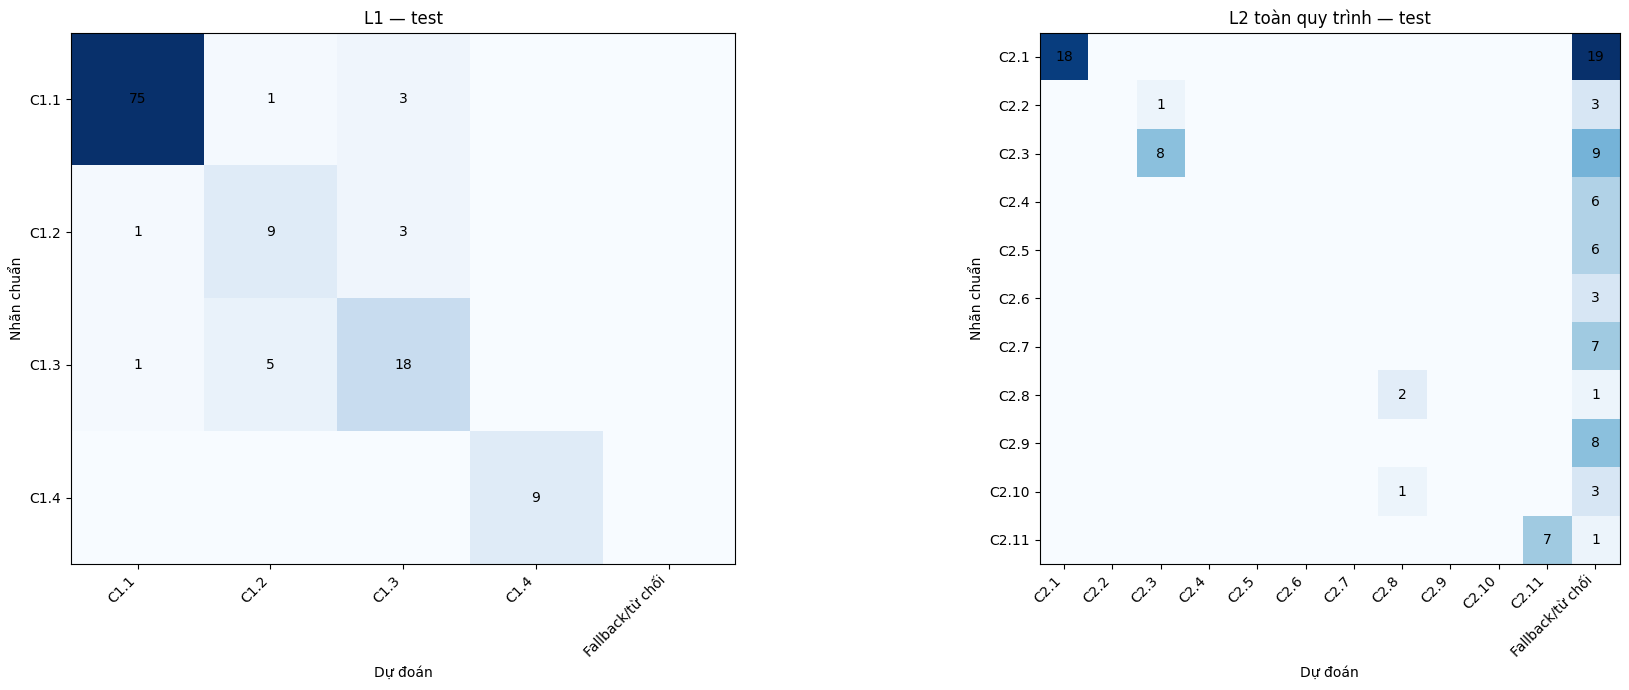

In [14]:
def compact_metrics(metrics):
    return {
        "l1_accuracy": metrics["l1_all_test"]["accuracy"],
        "l1_macro_f1": metrics["l1_all_test"]["macro_f1"],
        "l1_ece": metrics["l1_calibration"]["ece_10_bins"],
        "l1_brier": metrics["l1_calibration"]["multiclass_brier"],
        "l1_selective_coverage": metrics["l1_selective_with_unknown"]["coverage"],
        "l1_selective_accuracy": metrics["l1_selective_with_unknown"]["selective_accuracy"],
        "unknown_rate": 1.0 - metrics["l1_selective_with_unknown"]["coverage"],
        "l2_oracle_accuracy": metrics["l2_oracle_given_gold_l1"]["accuracy"],
        "l2_oracle_macro_f1": metrics["l2_oracle_given_gold_l1"]["macro_f1"],
        "l2_coverage": metrics["l2_end_to_end_with_l1_fallback"]["coverage"],
        "l2_selective_accuracy": metrics["l2_end_to_end_with_l1_fallback"]["selective_accuracy"],
        "l2_exact_over_all": metrics["l2_end_to_end_with_l1_fallback"]["exact_leaf_correct_over_all_gold_l2"],
        "l2_blank_abstention": metrics["l2_end_to_end_with_l1_fallback"]["abstention_rate_on_blank_l2"],
        "l2_evidence_accuracy": (metrics["l2_evidence_classifier"]["accuracy"]
                                 if metrics.get("l2_evidence_classifier") else np.nan),
    }

comparison = {"direct_image": compact_metrics(image_test_metrics),
              "predicted_keypoints": compact_metrics(keypoint_test_metrics)}
comparison_df = pd.DataFrame(comparison).T
display(comparison_df[["l1_accuracy", "l1_macro_f1", "l2_oracle_macro_f1",
                       "l2_exact_over_all", "l2_blank_abstention"]])

# Đánh giá quyết định cuối, tính cả dự đoán L2 sai trên ảnh có L2 trống.
test_decisions = {name: pd.read_csv(folder / "test_predictions.csv", keep_default_na=False)
                  for name, folder in [("Ảnh", image_run_dir), ("Keypoint", keypoint_run_dir),
                                       ("Phương án sử dụng", deployment_dir)]}
final_class_rows = []
for name, predictions in test_decisions.items():
    for code in indices["l2_codes"]:
        support = int((predictions.gold_l2 == code).sum())
        predicted = int((predictions.final_code == code).sum())
        correct = int(((predictions.gold_l2 == code) & (predictions.final_code == code)).sum())
        final_class_rows.append(dict(method=name, code=code, label=l2_names_vi[code], support=support,
            predicted=predicted, correct=correct, precision=correct/max(predicted,1),
            recall=correct/max(support,1), f1=2*correct/max(support+predicted,1)))
final_class_df = pd.DataFrame(final_class_rows)
display(final_class_df.pivot(index="code", columns="method", values="f1"))
display(final_class_df[final_class_df.method == "Phương án sử dụng"].drop(columns="method"))
final_class_df.to_csv(RUN_ROOT / "l2_end_to_end_all_methods.csv", index=False, encoding="utf-8-sig")
for name, predictions in test_decisions.items():
    accepted = predictions.decision_level == "l2"
    correct = (predictions.gold_l2 == predictions.final_code) & accepted & (predictions.gold_l2 != "")
    mean_f1 = final_class_df.loc[final_class_df.method == name, "f1"].mean()
    print(f"{name}: macro-F1 L2={mean_f1:.4f}; precision L2 gộp={correct.sum()/max(accepted.sum(),1):.4f}")

# Ma trận test được đọc sau khi đã khóa phương án sử dụng.
predictions = test_decisions["Phương án sử dụng"]
fig, axes = plt.subplots(1, 2, figsize=(19, 7))
for ax, gold_column, codes, title in [
    (axes[0], "gold_l1", indices["l1_codes"], "L1 — test"),
    (axes[1], "gold_l2", indices["l2_codes"], "L2 toàn quy trình — test")]:
    columns = codes + ["Fallback/từ chối"]
    matrix = np.zeros((len(codes),len(columns)),dtype=int)
    for _, row in predictions.iterrows():
        if row[gold_column] not in codes: continue
        predicted = row.pred_l1 if gold_column == "gold_l1" else row.final_code
        j = codes.index(predicted) if predicted in codes else len(codes)
        matrix[codes.index(row[gold_column]),j] += 1
    ax.imshow(matrix,cmap="Blues")
    ax.set_xticks(range(len(columns)),columns,rotation=45,ha="right")
    ax.set_yticks(range(len(codes)),codes); ax.set_title(title)
    ax.set_xlabel("Dự đoán"); ax.set_ylabel("Nhãn chuẩn")
    for i,j in np.ndindex(matrix.shape):
        if matrix[i,j]: ax.text(j,i,str(matrix[i,j]),ha="center",va="center")
plt.tight_layout(); plt.show()


**Giải thích và giới hạn.** So sánh ảnh và keypoint trên cùng test. Đọc cả macro-F1 và kết quả từng lớp để tránh lớp đông che lấp lớp hiếm. Không thay đổi lựa chọn đã khóa sau khi xem bảng.


## 15. Ước lượng độ bất định của chênh lệch kết quả

Cell lấy mẫu lại có hoàn lại 2.000 lần từ các dòng test, giữ cặp dự đoán của hai phương pháp trên cùng mẫu. Phép bootstrap theo cặp ước lượng khoảng biến động của chênh lệch accuracy L1 do thành phần tập test. Nó không huấn luyện lại mô hình và không đo đầy đủ biến động giữa các seed.

In [15]:
def bootstrap_accuracy_difference(outputs_a, outputs_b, n_boot=2000, seed=SEED):
    rng = np.random.default_rng(seed)
    gold = np.array([indices["l1_to_idx"][row["level_1_code"]] for row in rows if row["split"] == "test"])
    pred_a = outputs_a["l1_logits"].argmax(axis=1)
    pred_b = outputs_b["l1_logits"].argmax(axis=1)
    differences = []
    for _ in range(n_boot):
        sample = rng.integers(0, len(gold), len(gold))
        differences.append(np.mean(pred_a[sample] == gold[sample]) - np.mean(pred_b[sample] == gold[sample]))
    return {"image_minus_keypoint_accuracy_difference": float(np.mean(differences)),
            "bootstrap_95ci": [float(x) for x in np.quantile(differences, [0.025, 0.975])],
            "bootstrap_resamples": n_boot}

paired_uncertainty = bootstrap_accuracy_difference(image_test_outputs, keypoint_test_outputs)
(RUN_ROOT / "paired_bootstrap.json").write_text(json.dumps(paired_uncertainty, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(paired_uncertainty, ensure_ascii=False, indent=2))


{
  "image_minus_keypoint_accuracy_difference": 0.03188000000000002,
  "bootstrap_95ci": [
    -0.02400000000000002,
    0.09599999999999997
  ],
  "bootstrap_resamples": 2000
}


**Giải thích và giới hạn.** Khoảng bootstrap phản ánh biến thiên trên tập đang có. Nếu khoảng chứa 0, chưa có bằng chứng chắc chắn về ưu thế của một phương pháp; các mẫu cùng hiện vật có thể còn phụ thuộc.


## 16. Phân tích các trường hợp còn sai

Cell lập danh sách những mẫu mà ít nhất một trong hai phương pháp dự đoán sai L1 hoặc từ chối trả L1, đồng thời khảo sát kết quả theo mức đầy đủ của điểm khớp. Danh sách này giúp chọn ảnh để kiểm tra trực quan và đối chiếu lại quy tắc gán nhãn. Các lỗi chỉ xảy ra ở L2 cần được xem thêm trong bảng theo lớp ở mục 13.

In [16]:
# Phân rã lỗi của đúng phương án được dùng trong demo.
predictions = pd.read_csv(deployment_dir / "test_predictions.csv", keep_default_na=False)
error_records = []
for _, row in predictions.iterrows():
    if row.gold_l2 == "":
        reason = "L2 trống nhưng trả nhãn chi tiết" if row.decision_level == "l2" else "Giữ mức tổng quát đúng yêu cầu"
    elif row.pred_l1 != row.gold_l1:
        reason = "Sai hoặc từ chối L1"
    elif row.l2_candidate != row.gold_l2:
        reason = "Sai ứng viên L2"
    elif row.final_code != row.gold_l2:
        reason = "Đúng ứng viên nhưng chưa vượt ngưỡng"
    else:
        reason = "Trả đúng L2"
    error_records.append(dict(instance_id=row.instance_id, gold_l1=row.gold_l1, gold_l2=row.gold_l2,
                              final_code=row.final_code, reason=reason))
error_df = pd.DataFrame(error_records)
display(pd.crosstab(error_df.gold_l2.replace("", "L2 trống"), error_df.reason))
display(error_df[~error_df.reason.isin(["Trả đúng L2", "Giữ mức tổng quát đúng yêu cầu"])])
error_df.to_csv(RUN_ROOT / "error_decomposition.csv", index=False, encoding="utf-8-sig")


reason,Giữ mức tổng quát đúng yêu cầu,L2 trống nhưng trả nhãn chi tiết,Sai hoặc từ chối L1,Sai ứng viên L2,Trả đúng L2,Đúng ứng viên nhưng chưa vượt ngưỡng
gold_l2,,,,,,
C2.1,0,0,1,4,18,14
C2.10,0,0,3,1,0,0
C2.11,0,0,0,0,7,1
C2.2,0,0,0,3,0,1
C2.3,0,0,1,1,8,7
C2.4,0,0,0,3,0,3
C2.5,0,0,2,2,0,2
C2.6,0,0,1,0,0,2
C2.7,0,0,2,2,0,3


,instance_id,gold_l1,gold_l2,final_code,reason
0,THK000506_01,C1.1,C2.1,C1.1,Đúng ứng viên nhưng chưa vượt ngưỡng
2,THK000513_01,C1.1,C2.3,C1.1,Sai ứng viên L2
4,THK000155_01,C1.2,C2.7,C1.2,Đúng ứng viên nhưng chưa vượt ngưỡng
5,THK000434_01,C1.1,C2.1,C1.1,Đúng ứng viên nhưng chưa vượt ngưỡng
6,THK000705_01,C1.1,C2.2,C2.3,Sai ứng viên L2
...,...,...,...,...,...
114,HAR_52548545_01,C1.1,C2.5,C1.3,Sai hoặc từ chối L1
115,HAR_86434_01,C1.1,C2.5,C1.1,Đúng ứng viên nhưng chưa vượt ngưỡng
119,WC_27292074_01,C1.1,C2.4,C1.1,Đúng ứng viên nhưng chưa vượt ngưỡng
120,WKM_10293661_01,C1.1,C2.3,C1.3,Sai hoặc từ chối L1


**Giải thích và giới hạn.** Phân biệt sai L1, sai nhãn con và fallback do thiếu độ tin cậy. Quan sát từng ảnh trước khi kết luận nguyên nhân thị giác như che khuất, mất chân hoặc nhầm bệ đỡ.


## 17. Lưu kết quả và báo cáo

Lưu cấu hình, nguồn checkpoint, lựa chọn validation, kết quả test của ảnh và keypoint, PCK/OKS/IoU, kappa và phân tích độ bất định trong cùng thư mục run. Sau bước này có thể nạp lại demo mà không huấn luyện lại.


In [17]:
summary = {
    "run_id": RUN_ID,
    "created_at": datetime.now(timezone.utc).isoformat(),
    "dataset_audit": audit_summary,
    "inter_rater_agreement": kappa_summary,
    "image_selection": image_selection,
    "image_test": compact_metrics(image_test_metrics),
    "pose_geometry_test": pose_geometry_metrics,
    "keypoint_selection": keypoint_selection,
    "keypoint_test": compact_metrics(keypoint_test_metrics),
    "paired_uncertainty": paired_uncertainty,
    "run_mode": RUN_MODE,
    "pipeline": "unified_image_keypoint",
    "image_architectures": IMAGE_ARCHITECTURES,
    "image_seeds": IMAGE_SEEDS,
    "deployment_selection": deployment_selection,
    "deployment_test": compact_metrics(deployment_test_metrics),
    "limitations": [
        "Ensemble nhiều seed ảnh; chưa phải nested cross-validation toàn pipeline.",
        "Test lịch sử đã được xem ở các vòng phát triển trước; cần tập độc lập mới để kết luận tổng quát hóa.",
        "Một số lớp L2 chỉ có 3-4 mẫu test.",
        "Không xác định hiện là cơ chế từ chối theo validation trong phân phối; chưa có tập âm/OOD để đánh giá phát hiện ngoài phân phối.",
        "Phạm vi sử dụng nội bộ, không phát hành dữ liệu hoặc trọng số.",
    ],
}
(RUN_ROOT / "source_notebook.ipynb").write_bytes((ROOT / "Thangka_Pose_Training.ipynb").read_bytes())
(RUN_ROOT / "SUMMARY.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")

report = f"""# Kết quả thực nghiệm phân tích tư thế Thangka

Run: {RUN_ID}  \nChế độ: {RUN_MODE} (smoke chỉ kiểm tra thực thi, không phải kết quả mô hình cuối)  \nSeeds ảnh thực tế: {IMAGE_SEEDS}  
Dataset: {audit_summary['dataset_version']}  
Seed: {SEED}

## Kiểm tra dữ liệu

- Tổng số mẫu: {audit_summary['records']}.
- Split train/validation/test: {audit_summary['split_counts']}.
- Mẫu đủ 17 keypoint: {audit_summary['full_keypoint_records']}.
- Rò rỉ artifact giữa split: {audit_summary['artifact_leakage_groups']} nhóm.
- Rò rỉ ảnh trùng hash giữa split: {audit_summary['exact_hash_leakage_groups']} nhóm.

## Độ đồng thuận

- Cặp nhãn độc lập của Ngan và My: {kappa_summary['n_paired']}.
- Kappa nhãn phân cấp: {kappa_summary['hierarchical_cohen_kappa']:.4f}.
- Kappa L1: {kappa_summary['l1_cohen_kappa']:.4f}.

## Phân loại trực tiếp từ ảnh

- Kiến trúc: {image_architecture}.
- L1 accuracy: {comparison['direct_image']['l1_accuracy']:.4f}.
- L1 macro-F1: {comparison['direct_image']['l1_macro_f1']:.4f}.
- Hiệu chỉnh độ tin cậy L1 (ECE / Brier): {comparison['direct_image']['l1_ece']:.4f} / {comparison['direct_image']['l1_brier']:.4f}.
- Ngưỡng từ chối L1: {image_l1_threshold:.4f}.
- L1 selective coverage/accuracy: {comparison['direct_image']['l1_selective_coverage']:.4f} / {comparison['direct_image']['l1_selective_accuracy']:.4f}.
- Tỷ lệ Không xác định: {comparison['direct_image']['unknown_rate']:.4f}.
- L2 oracle macro-F1: {comparison['direct_image']['l2_oracle_macro_f1']:.4f}.
- L2 exact trên toàn bộ mẫu có gold L2: {comparison['direct_image']['l2_exact_over_all']:.4f}.
- Tỷ lệ fallback trên mẫu người gán nhãn để trống L2: {comparison['direct_image']['l2_blank_abstention']:.4f}.

## Pose và phân loại từ keypoint dự đoán

- Pose PCK@0.05 bbox diagonal: {pose_geometry_metrics['pck_at_0_05_bbox_diagonal']:.4f}.
- Mean bbox IoU: {pose_geometry_metrics['mean_bbox_iou'] if pose_geometry_metrics['mean_bbox_iou'] is not None else 'n.a.'}.
- Mean OKS: {pose_geometry_metrics['mean_oks'] if pose_geometry_metrics['mean_oks'] is not None else 'n.a.'}.
- Classifier keypoint: {keypoint_model_name}.
- L1 accuracy: {comparison['predicted_keypoints']['l1_accuracy']:.4f}.
- L1 macro-F1: {comparison['predicted_keypoints']['l1_macro_f1']:.4f}.
- Hiệu chỉnh độ tin cậy L1 (ECE / Brier): {comparison['predicted_keypoints']['l1_ece']:.4f} / {comparison['predicted_keypoints']['l1_brier']:.4f}.
- Ngưỡng từ chối L1: {keypoint_l1_threshold:.4f}.
- L1 selective coverage/accuracy: {comparison['predicted_keypoints']['l1_selective_coverage']:.4f} / {comparison['predicted_keypoints']['l1_selective_accuracy']:.4f}.
- Tỷ lệ Không xác định: {comparison['predicted_keypoints']['unknown_rate']:.4f}.
- L2 oracle macro-F1: {comparison['predicted_keypoints']['l2_oracle_macro_f1']:.4f}.
- L2 exact trên toàn bộ mẫu có gold L2: {comparison['predicted_keypoints']['l2_exact_over_all']:.4f}.
- Tỷ lệ fallback trên mẫu người gán nhãn để trống L2: {comparison['predicted_keypoints']['l2_blank_abstention']:.4f}.
- Accuracy bộ kiểm tra đủ bằng chứng L2: {comparison['predicted_keypoints']['l2_evidence_accuracy']:.4f}.

## So sánh và giới hạn

- Chênh lệch L1 accuracy hướng ảnh trừ hướng keypoint: {paired_uncertainty['image_minus_keypoint_accuracy_difference']:.4f}.
- Bootstrap 95% CI: {paired_uncertainty['bootstrap_95ci']}.
- Mô hình ảnh học head, mở các block trên rồi toàn backbone; cố định thống kê BatchNorm, dùng loss phân cấp joint và head bằng chứng L2.
- Mô hình keypoint dùng đặc trưng hình học chuẩn hóa, classifier L2 riêng theo nhánh và bộ kiểm tra đủ bằng chứng L2.
- So sánh ngưỡng theo lớp với ngưỡng chung theo nhánh cha trên validation; kiểm tra độ ổn định theo nhóm hiện vật, không ép nhãn hiếm.
- Xác suất được temperature scaling trên validation trước khi chọn ngưỡng từ chối.
- ConvNeXt được huấn luyện trong cùng vòng so sánh với ResNet18 và MobileNetV2; lấy mẫu cân bằng chỉ trên train, không ép mẫu L2 trống.
- Ensemble nhiều seed; không suy rộng quá phạm vi snapshot hoặc coi test đã xem là đánh giá độc lập mới.
- Các lớp L2 support nhỏ phải được báo cùng support và confusion matrix.
- Không xác định là từ chối do bằng chứng yếu theo validation; chưa thể diễn giải như bộ phát hiện OOD vì chưa có tập âm/OOD.
- Dữ liệu và trọng số chỉ dùng nội bộ theo metadata quyền sử dụng.
"""
(RUN_ROOT / "REPORT.md").write_text(report, encoding="utf-8")
print(report)
print("\nHoàn tất. Tất cả kết quả của run ở:", RUN_ROOT)

with (RUN_ROOT / "REPORT.md").open("a", encoding="utf-8") as stream:
    stream.write("\n\n## Đầu ra triển khai\n\n" + json.dumps({"selection": deployment_selection, "test": compact_metrics(deployment_test_metrics)}, ensure_ascii=False, indent=2))


# Kết quả thực nghiệm phân tích tư thế Thangka

Run: 20261103_101754_seed20261021  
Chế độ: full (smoke chỉ kiểm tra thực thi, không phải kết quả mô hình cuối)  
Seeds ảnh thực tế: [20261021, 20261031, 20261107]  
Dataset: thangka_pose_v1.1.0_dacntt_2026-10-20  
Seed: 20261021

## Kiểm tra dữ liệu

- Tổng số mẫu: 873.
- Split train/validation/test: {'val': 136, 'train': 612, 'test': 125}.
- Mẫu đủ 17 keypoint: 612.
- Rò rỉ artifact giữa split: 0 nhóm.
- Rò rỉ ảnh trùng hash giữa split: 0 nhóm.

## Độ đồng thuận

- Cặp nhãn độc lập của Ngan và My: 873.
- Kappa nhãn phân cấp: 0.9652.
- Kappa L1: 1.0000.

## Phân loại trực tiếp từ ảnh

- Kiến trúc: resnet18.
- L1 accuracy: 0.8880.
- L1 macro-F1: 0.8386.
- Hiệu chỉnh độ tin cậy L1 (ECE / Brier): 0.0516 / 0.1597.
- Ngưỡng từ chối L1: 0.0000.
- L1 selective coverage/accuracy: 1.0000 / 0.8880.
- Tỷ lệ Không xác định: 0.0000.
- L2 oracle macro-F1: 0.7672.
- L2 exact trên toàn bộ mẫu có gold L2: 0.3398.
- Tỷ lệ fallback trên mẫu người gán nhãn 

**Giải thích và giới hạn.** Lưu thành công giúp tái lập, không chứng minh chất lượng đã tăng. Test lịch sử từng được xem khi phát triển; cần dữ liệu độc lập mới để xác nhận khả năng khái quát hóa. Các lớp ít mẫu phải được báo cùng support và lỗi cụ thể.


## 18. Demo bằng mô hình đã lưu

Khi mở lại notebook, chạy riêng cell dưới để thử ảnh mà không cần huấn luyện lại. Mỗi lần chạy cell, demo nạp lại checkpoint của lần huấn luyện đầy đủ mới nhất. Nút **Nạp model mới nhất** trong giao diện cũng nạp lại checkpoint mà không cần chạy lại cell. Để dùng model trước, chạy `DEMO_RUN_ID = "20261031_174634_seed20261021"` trong một cell riêng, rồi chạy lại cell demo. Đặt `DEMO_RUN_ID = None` và chạy lại cell demo để trở về model mới nhất.

Đường dẫn run được in ra cho biết chính xác model đang dùng. Mỗi ảnh nhận một quyết định L2, L1 hoặc Không xác định, kèm độ tin cậy và phần minh họa hình học.


In [1]:
# Nạp trực tiếp từ checkpoint và bản mã nguồn của lần chạy đã hoàn thành.
from pathlib import Path
_saved_demo_root = next(candidate.resolve()
    for base in [Path.cwd(), *Path.cwd().parents]
    for candidate in [base, base / "Thangka_Pose_Training"]
    if (candidate / "Thangka_Pose_Training.ipynb").is_file() and (candidate / "data").is_dir())
"""Resolve executable notebook cells independently of explanatory markdown."""

CELL_KEY = "thangka_original_cell_index"


def get_code_cell(notebook, original_index):
    tagged = [cell for cell in notebook["cells"] if CELL_KEY in cell.get("metadata", {})]
    if tagged:
        matches = [cell for cell in tagged if cell["metadata"][CELL_KEY] == original_index]
        if len(matches) != 1 or matches[0]["cell_type"] != "code":
            raise ValueError(f"Missing or ambiguous code cell {original_index}")
        return matches[0]
    # Historical run snapshots predate stable cell metadata.
    cell = notebook["cells"][original_index]
    if cell["cell_type"] != "code":
        raise ValueError(f"Expected code at legacy cell {original_index}")
    return cell

"""Restore the most recent completed full run for the notebook demo.

This module only loads the frozen model artifacts and the exact utility definitions
saved with the run. It never executes training, calibration, or test selection cells.
"""


import ast
import csv
import hashlib
import json
from pathlib import Path


def _load_json(path: Path):
    return json.loads(path.read_text(encoding="utf-8"))


def _latest_completed_run(root: Path) -> tuple[Path, dict]:
    runs = root / "outputs" / "notebook_runs"
    candidates = []
    for run_dir in runs.iterdir():
        if not run_dir.is_dir():
            continue
        summary_path = run_dir / "SUMMARY.json"
        selection_path = run_dir / "deployment" / "selection.json"
        source_path = run_dir / "source_notebook.ipynb"
        if not (summary_path.is_file() and selection_path.is_file() and source_path.is_file()):
            continue
        summary = _load_json(summary_path)
        if summary.get("run_mode") == "full" and summary.get("run_id") == run_dir.name:
            candidates.append((run_dir, summary))
    if not candidates:
        raise FileNotFoundError("Chưa có run huấn luyện đầy đủ đã hoàn tất trong outputs/notebook_runs.")
    return max(candidates, key=lambda item: item[0].name)


def load_saved_demo_globals(root: str | Path | None = None, *, run_id: str | None = None) -> dict:
    """Return globals needed by cell Demo, without calling fit_model or Run All."""
    root = Path(root or _saved_demo_root).expanduser().resolve()
    data_dir = root / "data"
    run_dir, summary = _latest_completed_run(root)
    if run_id is not None:
        if not isinstance(run_id, str) or Path(run_id).name != run_id:
            raise ValueError("Tên run không hợp lệ.")
        run_dir = root / "outputs" / "notebook_runs" / run_id
        summary = _load_json(run_dir / "SUMMARY.json")
        if summary.get("run_mode") != "full" or summary.get("run_id") != run_id or not (run_dir / "source_notebook.ipynb").is_file():
            raise ValueError("Run được chọn chưa hoàn thành hoặc thiếu bản mã nguồn để nạp demo.")
    active_path = root / 'outputs/active_quality_v2.json'
    selection = _load_json(run_dir / "deployment" / "selection.json")
    image_selection = summary["image_selection"]
    manifest_hash = hashlib.sha256((data_dir / "classification_manifest.csv").read_bytes()).hexdigest()
    for record in (image_selection, selection):
        if record.get("manifest_sha256") != manifest_hash:
            raise RuntimeError("Manifest hiện tại khác manifest lúc huấn luyện; không nạp demo sai dữ liệu.")
        if record.get("model_schema") != 4:
            raise RuntimeError("Không hỗ trợ schema mô hình của run đã chọn.")
    image_size = int(image_selection["image_size"])
    if image_size != 384:
        raise RuntimeError(f"Image size không khớp mã mô hình: {image_size}.")

    source = _load_json(run_dir / "source_notebook.ipynb")
    utilities = "".join(get_code_cell(source, 6)["source"])
    namespace = {
        "ROOT": root,
        "DATA_DIR": data_dir,
        "IMAGE_SIZE": image_size,
        "IMAGE_DROPOUT": 0.30,
        "CLASS_WEIGHT_POWER": 0.5,
        "MODEL_SCHEMA": 4,
    }
    exec(compile(utilities, str(run_dir / "source_notebook.ipynb") + ":cell_6", "exec"), namespace)
    # Cell 22 also trains classifiers at top level. Load only the definitions needed
    # for its frozen keypoint model and demo, never the training statements.
    cell22 = ast.parse("".join(get_code_cell(source, 22)["source"]))
    required = {"_joint_angle_cos", "engineer_pose_features", "probability_matrix", "outputs_from_classifiers"}
    definitions = ast.Module(body=[node for node in cell22.body if isinstance(node, ast.FunctionDef) and node.name in required], type_ignores=[])
    if {node.name for node in definitions.body} != required:
        raise RuntimeError("Thiếu hàm suy luận keypoint trong snapshot của run.")
    exec(compile(definitions, str(run_dir / "source_notebook.ipynb") + ":cell_22", "exec"), namespace)

    import joblib
    import matplotlib.pyplot as plt
    import numpy as np
    import pandas as pd
    import torch
    from IPython.display import display
    from PIL import Image
    from ultralytics import YOLO

    ontology = _load_json(data_dir / "ontology.json")
    indices = namespace["class_index_maps"](ontology)
    with (data_dir / "classification_manifest.csv").open(encoding="utf-8-sig", newline="") as stream:
        rows = list(csv.DictReader(stream))

    image_members = []
    for member in selection["image_members"]:
        restored = dict(member)
        checkpoint = run_dir / "image_classifier" / f"{member['architecture']}_seed{member['seed']}" / "best_model.pt"
        if not checkpoint.is_file():
            raise FileNotFoundError(f"Thiếu checkpoint ảnh: {checkpoint}")
        restored["checkpoint"] = str(checkpoint)
        image_members.append(restored)
    if not image_members:
        raise RuntimeError("Run không chứa mô hình ảnh để demo.")

    keypoint_path = run_dir / "keypoint_classifier" / "final_keypoint_classifier.joblib"
    keypoint_state = joblib.load(keypoint_path)
    if keypoint_state.get("model_schema") != 4 or keypoint_state.get("feature_dimension") != 100:
        raise RuntimeError("Checkpoint keypoint không tương thích với đặc trưng của demo.")
    if keypoint_state["indices"] != indices:
        raise RuntimeError("Ontology hiện tại khác ontology của checkpoint keypoint.")
    pose_checkpoint = root / "outputs" / "pose_baseline" / "best.pt"
    if not pose_checkpoint.is_file():
        raise FileNotFoundError(f"Thiếu checkpoint pose: {pose_checkpoint}")
    selected = selection["selected"]
    namespace.update({
        "Path": Path, "np": np, "pd": pd, "plt": plt, "torch": torch, "Image": Image, "display": display,
        "ROOT": root, "DATA_DIR": data_dir, "CACHE_DIR": root / "cache", "RUN_ROOT": run_dir,
        "ontology": ontology, "indices": indices, "rows": rows,
        "l1_names_vi": {item["code"]: item["vi"] for item in ontology["level_1"]},
        "l2_names_vi": {item["code"]: item["vi"] for item in ontology["level_2"]},
        "DEVICE": "cuda" if torch.cuda.is_available() else "cpu",
        "POSE_IMAGE_SIZE": 416,
        "pose_feature_device": "cuda" if torch.cuda.is_available() else "cpu",
        "pose_model": YOLO(str(pose_checkpoint)),
        "image_members": image_members,
        "keypoint_best": {"l1_model": keypoint_state["l1_model"], "l2_models": keypoint_state["l2_models"],
                          "evidence_model": keypoint_state["evidence_model"]},
        "keypoint_temperatures": keypoint_state["temperatures"],
        "deployment_selection": selected,
        "deployment_threshold": float(selected["l2_threshold"]),
        "deployment_l1_threshold": float(selected["l1_threshold"]),
        "deployment_evidence_threshold": float(selected["evidence_threshold"]),
        "deployment_class_thresholds": selected["class_thresholds"],
    })
    print(f"Đã nạp mô hình và ngưỡng từ run {run_dir.name}; có thể chạy demo ngay.")
    return namespace

# None: nạp lần huấn luyện đầy đủ mới nhất; có thể chọn mã run cũ.
DEMO_RUN_ID = globals().get("DEMO_RUN_ID", None)
def reload_demo_model(run_id=None):
    restored = load_saved_demo_globals(_saved_demo_root, run_id=run_id)
    globals().update(restored)
    globals()["DEMO_RUN_ID"] = run_id
    return restored["RUN_ROOT"]

reload_demo_model(DEMO_RUN_ID)

def format_prediction_vi(prediction):
    percent = 100.0 * prediction["final_confidence"]
    if prediction["is_unknown"]:
        return f"Không xác định – độ tin cậy L1 cao nhất {percent:.0f}%"
    code = prediction["final_code"]
    name = l2_names_vi[code] if prediction["decision_level"] == "l2" else l1_names_vi[code]
    return f"{name} – {percent:.0f}%"

def prediction_reason_vi(prediction):
    if prediction["is_unknown"]:
        return "Độ tin cậy tư thế tổng quát chưa đạt ngưỡng được chọn trên validation."
    if prediction["decision_level"] == "l2":
        return "Đủ bằng chứng thị giác và độ tin cậy để trả nhãn chi tiết L2."
    if not prediction["l2_evidence_ok"]:
        return "Chưa đủ bằng chứng thị giác cho L2; hệ thống giữ nhãn tổng quát L1."
    return "Độ tin cậy L2 chưa đạt ngưỡng; hệ thống giữ nhãn tổng quát L1."

def predict_posture(image_path):
    image_path = Path(image_path).expanduser().resolve()
    if not image_path.is_file():
        raise FileNotFoundError(f"Không tìm thấy ảnh demo: {image_path}")
    pose_result = pose_model.predict(
        source=str(image_path), imgsz=POSE_IMAGE_SIZE,
        device=pose_feature_device, half=pose_feature_device != "cpu", max_det=1, verbose=False,
    )[0]
    feature = np.zeros((1, 54), dtype=np.float32)
    with Image.open(image_path) as source_image:
        feature[0, 53] = source_image.width / source_image.height
    detected = False
    if pose_result.boxes is not None and len(pose_result.boxes) and pose_result.keypoints is not None:
        best = int(np.argmax(pose_result.boxes.conf.detach().cpu().numpy()))
        xy = pose_result.keypoints.xyn[best].detach().cpu().numpy()
        kp_conf = (pose_result.keypoints.conf[best].detach().cpu().numpy()
                   if pose_result.keypoints.conf is not None else np.ones(17))
        feature[0, :51] = np.column_stack([xy, kp_conf]).reshape(-1)
        feature[0, 51] = float(pose_result.boxes.conf[best])
        feature[0, 52] = 1.0
        detected = True
    geometry_feature = engineer_pose_features(feature)
    outputs = apply_temperatures(outputs_from_classifiers(
        keypoint_best["l1_model"], keypoint_best["l2_models"], keypoint_best["evidence_model"],
        geometry_feature,
    ), keypoint_temperatures)
    image_outputs = collect_image_path(image_path, image_members, indices)
    outputs = fuse_outputs(image_outputs, outputs, indices, deployment_selection["image_weight"], [detected])
    prediction = hierarchical_predictions(
        outputs, indices, deployment_threshold, deployment_l1_threshold, None,
        deployment_evidence_threshold, deployment_class_thresholds,
    )[0]
    return {
        "image_path": str(image_path), "pose_detected": detected,
        "prediction": prediction, "display_text": format_prediction_vi(prediction),
        "reason_text": prediction_reason_vi(prediction),
        "l1_probabilities": torch.softmax(torch.tensor(outputs["l1_logits"]), dim=1).numpy()[0],
        "l2_logits": outputs["l2_logits"][0], "pose_result": pose_result,
    }

# COCO-17 không có keypoint cổ. Hai cạnh tai-vai mặc định dễ gây hiểu nhầm trên tranh Thangka,
# nên phần minh họa tách khung mặt khỏi khung thân; dữ liệu keypoint dùng cho phân loại không đổi.
DEMO_SKELETON_EDGES = [
    (0, 1), (0, 2), (1, 2), (1, 3), (2, 4),  # mặt
    (5, 6), (5, 7), (7, 9), (6, 8), (8, 10),
    (5, 11), (6, 12), (11, 12), (11, 13), (13, 15), (12, 14), (14, 16),
]

def draw_demo_pose(ax, pose_result, min_keypoint_confidence=0.25):
    from matplotlib.patches import Rectangle
    image_rgb = pose_result.orig_img[..., ::-1]
    ax.imshow(image_rgb)
    if pose_result.boxes is None or len(pose_result.boxes) == 0 or pose_result.keypoints is None:
        return
    box_confidences = pose_result.boxes.conf.detach().cpu().numpy()
    best = int(np.argmax(box_confidences))
    x1, y1, x2, y2 = pose_result.boxes.xyxy[best].detach().cpu().numpy()
    ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="#ffd23f", linewidth=2.5))
    xy = pose_result.keypoints.xy[best].detach().cpu().numpy()
    confidence = (pose_result.keypoints.conf[best].detach().cpu().numpy()
                  if pose_result.keypoints.conf is not None else np.ones(len(xy), dtype=np.float32))
    visible = confidence >= float(min_keypoint_confidence)
    for start, end in DEMO_SKELETON_EDGES:
        if visible[start] and visible[end]:
            is_face = start <= 4 and end <= 4
            ax.plot([xy[start, 0], xy[end, 0]], [xy[start, 1], xy[end, 1]],
                    color="#23e05f" if is_face else "#20a4f3", linewidth=2.5, alpha=0.9)
    face_points = np.arange(0, 5)
    body_points = np.arange(5, 17)
    face_visible = face_points[visible[face_points]]
    body_visible = body_points[visible[body_points]]
    if len(face_visible):
        ax.scatter(xy[face_visible, 0], xy[face_visible, 1], s=55, c="#23e05f", edgecolors="white", linewidths=0.8, zorder=3)
    if len(body_visible):
        ax.scatter(xy[body_visible, 0], xy[body_visible, 1], s=55, c="#20a4f3", edgecolors="white", linewidths=0.8, zorder=3)
    ax.text(x1, max(0, y1 - 8), f"Pose {100 * box_confidences[best]:.0f}%", color="#ffe066",
            fontsize=11, fontweight="bold", bbox={"facecolor": "black", "alpha": 0.55, "pad": 3})

def show_prediction(result):
    pred = result["prediction"]
    # Tách ảnh khỏi biểu đồ để ảnh Thangka không bị co nhỏ khi trình chiếu.
    image_fig, image_ax = plt.subplots(figsize=(15, 9), dpi=120)
    draw_demo_pose(image_ax, result["pose_result"])
    image_ax.set_title(result["display_text"], fontsize=16, fontweight="bold")
    image_ax.axis("off")
    image_fig.tight_layout()
    plt.show()
    plt.close(image_fig)
    fig, axes = plt.subplots(1, 3, figsize=(20, 6), dpi=120)
    l1_prob = result["l1_probabilities"]
    l1_labels = [l1_names_vi[code] for code in indices["l1_codes"]]
    colors = ["#2a7771" if code == pred["l1_candidate"] else "#9fbfbc" for code in indices["l1_codes"]]
    axes[0].barh(l1_labels, l1_prob, color=colors)
    axes[0].axvline(deployment_l1_threshold, color="#b33a3a", linestyle="--", label=f"Ngưỡng L1 = {deployment_l1_threshold:.2f}")
    axes[0].set_xlim(0, 1); axes[0].set_title("Độ tin cậy nhãn tổng quát L1"); axes[0].legend()
    evidence_value = pred["l2_evidence_confidence"]
    axes[1].barh(["Đủ bằng chứng L2"], [evidence_value], color="#526e9e")
    axes[1].axvline(deployment_evidence_threshold, color="#b33a3a", linestyle="--",
                    label=f"Ngưỡng bằng chứng = {deployment_evidence_threshold:.2f}")
    axes[1].set_xlim(0, 1); axes[1].set_title("Bằng chứng cho nhãn chi tiết"); axes[1].legend()
    parent = pred["l1_candidate"]
    child_codes = [code for code in indices["l2_codes"] if indices["l2_parent"][code] == parent]
    child_idx = [indices["l2_to_idx"][code] for code in child_codes]
    conditional = torch.softmax(torch.tensor(result["l2_logits"][child_idx]), dim=0).numpy()
    joint = pred["l1_confidence"] * conditional
    axes[2].barh([l2_names_vi[code] for code in child_codes], joint, color="#c28b45")
    axes[2].axvline(deployment_threshold, color="#b33a3a", linestyle="--", label=f"Ngưỡng L2 = {deployment_threshold:.2f}")
    selected_cutoff = deployment_class_thresholds[pred["l2_candidate"]]
    if selected_cutoff <= 1.0:
        axes[2].axvline(selected_cutoff, color="#7b3294", linestyle=":", label="Ngưỡng riêng nhãn ứng viên")
    else:
        axes[2].text(0.02, 0.95, "Nhãn ứng viên chưa đủ bằng chứng validation để trả L2", transform=axes[2].transAxes, va="top", fontsize=9)
    axes[2].set_xlim(0, 1); axes[2].set_title("Độ tin cậy nhãn chi tiết trong nhánh L1"); axes[2].legend()
    fig.suptitle("Căn cứ cho quyết định phân loại", fontsize=16, fontweight="bold")
    fig.tight_layout()
    plt.show()
    plt.close(fig)

def run_demo(image_path="", split="val", index=0):
    selected_row = None
    if str(image_path).strip():
        demo_path = Path(str(image_path).strip())
        source_text = f"Ảnh ngoài: {demo_path.name}"
    else:
        split_rows = [row for row in rows if row["split"] == split]
        if not split_rows:
            raise ValueError(f"Split không hợp lệ hoặc không có ảnh: {split}")
        selected_row = split_rows[int(index) % len(split_rows)]
        demo_path = DATA_DIR / selected_row["crop_path"]
        source_text = (f"Dataset {split}, ảnh gốc {Path(selected_row['image_path']).name} "
                       f"→ crop mục tiêu {Path(selected_row['crop_path']).name}")
    result = predict_posture(demo_path)
    pred = result["prediction"]
    gold_text = "Không có nhãn tham chiếu"
    if selected_row is not None:
        gold_text = l2_names_vi.get(selected_row["level_2_code"], l1_names_vi[selected_row["level_1_code"]])
    display(pd.DataFrame([{
        "Nguồn ảnh": source_text, "Nhãn tham chiếu": gold_text,
        "Kết quả hệ thống": result["display_text"],
        "Mức quyết định": pred["decision_level"].upper(),
        "Bằng chứng L2": f"{100 * pred['l2_evidence_confidence']:.0f}%",
        "Giải thích fallback": result["reason_text"],
    }]))
    show_prediction(result)
    return result

# Demo mặc định. Có thể đổi split/index hoặc truyền đường dẫn ảnh ngoài dataset.
SUPPORTED_DEMO_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp", ".bmp", ".tif", ".tiff"}

def run_demo_batch(image_paths, max_images=None):
    from IPython.display import Markdown
    paths = [Path(path).expanduser().resolve() for path in image_paths]
    if max_images is not None:
        paths = paths[:max(1, int(max_images))]
    if not paths:
        raise ValueError("Chưa chọn ảnh hợp lệ để demo.")
    import gc
    summary_rows = []
    for number, image_path in enumerate(paths, start=1):
        display(Markdown(f"## Ảnh {number}/{len(paths)} — `{image_path.name}`"))
        try:
            result = run_demo(image_path=image_path)
            summary_rows.append({"Ảnh": image_path.name, "Kết quả": result["display_text"],
                                 "Mức quyết định": result["prediction"]["decision_level"].upper(), "Trạng thái": "Thành công"})
            del result
        except Exception as exc:
            print(type(exc).__name__ + ":", exc)
            summary_rows.append({"Ảnh": image_path.name, "Kết quả": "—", "Mức quyết định": "—", "Trạng thái": str(exc)})
        finally:
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
    display(Markdown("## Tổng hợp lô ảnh"))
    summary = pd.DataFrame(summary_rows)
    display(summary)
    return summary

def run_demo_folder(folder_path, recursive=False, max_images=20):
    folder = Path(str(folder_path).strip()).expanduser().resolve()
    if not folder.is_dir():
        raise NotADirectoryError(f"Không tìm thấy thư mục: {folder}")
    candidates = folder.rglob("*") if recursive else folder.iterdir()
    image_paths = sorted(
        (path for path in candidates if path.is_file() and path.suffix.lower() in SUPPORTED_DEMO_EXTENSIONS),
        key=lambda path: str(path).lower(),
    )
    if not image_paths:
        raise FileNotFoundError(f"Thư mục không có ảnh định dạng được hỗ trợ: {folder}")
    if len(image_paths) > int(max_images):
        print(f"Tìm thấy {len(image_paths)} ảnh; demo {int(max_images)} ảnh đầu để kiểm soát thời gian và bộ nhớ.")
    return run_demo_batch(image_paths, max_images=max_images)

def run_demo_dataset_batch(split, selected_indices, max_images=20):
    from IPython.display import Markdown
    import gc
    split_rows = [row for row in rows if row["split"] == split]
    if not split_rows:
        raise ValueError(f"Split không hợp lệ hoặc không có ảnh: {split}")
    chosen = list(selected_indices)[:max(1, int(max_images))]
    if not chosen:
        raise ValueError("Hãy chọn ít nhất một ảnh trong danh sách dataset.")
    summary_rows = []
    for number, index in enumerate(chosen, start=1):
        index = int(index) % len(split_rows)
        row = split_rows[index]
        image_name = Path(row["crop_path"]).name
        display(Markdown(f"## Ảnh dataset {number}/{len(chosen)} — `{image_name}`"))
        try:
            result = run_demo(split=split, index=index)
            gold = l2_names_vi.get(row["level_2_code"], l1_names_vi[row["level_1_code"]])
            summary_rows.append({"Ảnh": image_name, "Nhãn tham chiếu": gold,
                                 "Kết quả": result["display_text"],
                                 "Mức quyết định": result["prediction"]["decision_level"].upper(),
                                 "Trạng thái": "Thành công"})
            del result
        except Exception as exc:
            print(type(exc).__name__ + ":", exc)
            summary_rows.append({"Ảnh": image_name, "Nhãn tham chiếu": "—", "Kết quả": "—",
                                 "Mức quyết định": "—", "Trạng thái": str(exc)})
        finally:
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
    display(Markdown("## Tổng hợp các ảnh dataset đã chọn"))
    summary = pd.DataFrame(summary_rows)
    display(summary)
    return summary

def run_demo_dataset_files(selected_paths, required_split=None):
    from IPython.display import Markdown
    import gc
    lookup = {}
    for split_name in sorted({row["split"] for row in rows}):
        split_rows = [row for row in rows if row["split"] == split_name]
        for index, row in enumerate(split_rows):
            image_name = Path(row["image_path"]).name.casefold()
            lookup[(split_name, image_name)] = (split_name, index, row)
    chosen_paths = [Path(path).expanduser().resolve() for path in selected_paths]
    if not chosen_paths:
        raise ValueError("Hãy bấm 'Chọn ảnh dataset' và chọn ít nhất một ảnh.")
    summary_rows = []
    for number, image_path in enumerate(chosen_paths, start=1):
        display(Markdown(f"## Ảnh dataset {number}/{len(chosen_paths)} — `{image_path.name}`"))
        split_candidates = [required_split] if required_split else sorted({key[0] for key in lookup})
        matches = [lookup[(split_name, image_path.name.casefold())] for split_name in split_candidates
                   if (split_name, image_path.name.casefold()) in lookup]
        match = matches[0] if matches else None
        if match is None:
            message = f"Ảnh không thuộc split {required_split!r} trong DATA_DIR/images hoặc không có trong manifest."
            print("ValueError:", message)
            summary_rows.append({"Ảnh": image_path.name, "Split": "—", "Nhãn tham chiếu": "—",
                                 "Kết quả": "—", "Mức quyết định": "—", "Trạng thái": message})
            continue
        split_name, index, row = match
        try:
            result = run_demo(split=split_name, index=index)
            gold = l2_names_vi.get(row["level_2_code"], l1_names_vi[row["level_1_code"]])
            summary_rows.append({"Ảnh": image_path.name, "Split": split_name, "Nhãn tham chiếu": gold,
                                 "Kết quả": result["display_text"],
                                 "Mức quyết định": result["prediction"]["decision_level"].upper(),
                                 "Trạng thái": "Thành công"})
            del result
        except Exception as exc:
            print(type(exc).__name__ + ":", exc)
            summary_rows.append({"Ảnh": image_path.name, "Split": split_name, "Nhãn tham chiếu": "—",
                                 "Kết quả": "—", "Mức quyết định": "—", "Trạng thái": str(exc)})
        finally:
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
    display(Markdown("## Tổng hợp các ảnh dataset đã chọn"))
    summary = pd.DataFrame(summary_rows)
    display(summary)
    return summary

demo_result = None  # Chọn nguồn ảnh trong giao diện bên dưới; không tự chạy ảnh validation.
print("Dùng ảnh ngoài dataset: run_demo(r'C:\\duong_dan\\anh.jpg')")
print("Dùng mẫu khác: run_demo(split='val', index=5) hoặc run_demo(split='test', index=5)")

# Giao diện nút bấm đơn giản trong Jupyter/VS Code; vẫn dùng được run_demo nếu ipywidgets chưa cài.
try:
    import ipywidgets as widgets
    from IPython.display import clear_output
    demo_source = widgets.Dropdown(options=[("Validation", "val"), ("Test đã khóa", "test")], description="Nguồn:")
    dataset_selected_paths = []
    dataset_picker_button = widgets.Button(
        description="Chọn ảnh dataset (0)", icon="folder-open",
        layout=widgets.Layout(width="240px"),
    )
    dataset_selection_status = widgets.HTML("<i>Chưa chọn ảnh gốc thuộc split Validation.</i>")
    demo_button = widgets.Button(description="Chạy ảnh đã chọn", button_style="primary")
    model_reload_button = widgets.Button(description="Nạp model mới nhất", icon="refresh")
    demo_output = widgets.Output()

    def _prepare_split_picker_directory(split_name):
        import os
        import shutil
        picker_dir = CACHE_DIR / "dataset_file_picker" / split_name
        picker_dir.mkdir(parents=True, exist_ok=True)
        split_rows = [row for row in rows if row["split"] == split_name]
        for row in split_rows:
            source = (DATA_DIR / row["image_path"]).resolve()
            target = picker_dir / source.name
            if target.exists():
                continue
            try:
                os.link(source, target)  # hard link: không nhân đôi dung lượng ảnh
            except OSError:
                shutil.copy2(source, target)
        return picker_dir

    def _reset_dataset_selection(change):
        dataset_selected_paths.clear()
        dataset_picker_button.description = "Chọn ảnh dataset (0)"
        split_label = "Validation" if change["new"] == "val" else "Test đã khóa"
        dataset_selection_status.value = f"<i>Chưa chọn ảnh gốc thuộc split {split_label}.</i>"

    def _choose_dataset_files(_):
        root = None
        try:
            import tkinter as tk
            from tkinter import filedialog
            initial_dir = _prepare_split_picker_directory(demo_source.value)
            split_label = "Validation" if demo_source.value == "val" else "Test đã khóa"
            root = tk.Tk()
            root.withdraw()
            root.attributes("-topmost", True)
            root.update()
            chosen = filedialog.askopenfilenames(
                parent=root, title=f"Chọn ảnh gốc thuộc split {split_label}",
                initialdir=str(initial_dir),
                filetypes=[("Tệp ảnh", "*.jpg *.jpeg *.png *.webp *.bmp *.tif *.tiff"), ("Tất cả tệp", "*.*")],
            )
            if chosen:
                dataset_selected_paths[:] = list(chosen)
                dataset_picker_button.description = f"Chọn ảnh dataset ({len(chosen)})"
                preview = ", ".join(Path(path).name for path in chosen[:4])
                if len(chosen) > 4:
                    preview += f" và {len(chosen) - 4} ảnh khác"
                dataset_selection_status.value = f"<small><b>Đã chọn {split_label}:</b> {preview}</small>"
        except Exception as exc:
            with demo_output:
                print("Không mở được hộp thoại dataset:", type(exc).__name__ + ":", exc)
        finally:
            if root is not None:
                root.destroy()

    def _show_in_widget(button, action):
        if button.disabled:
            return
        button.disabled = True
        demo_output.outputs = ()
        try:
            with demo_output:
                try:
                    action()
                except Exception as exc:
                    print(type(exc).__name__ + ":", exc)
        finally:
            button.disabled = False

    def _run_demo_button(_):
        _show_in_widget(demo_button,
                        lambda: run_demo_dataset_files(dataset_selected_paths, required_split=demo_source.value))
    demo_source.observe(_reset_dataset_selection, names="value")
    dataset_picker_button.on_click(_choose_dataset_files)
    demo_button.on_click(_run_demo_button)
    model_reload_button.on_click(lambda _: _show_in_widget(model_reload_button, reload_demo_model))
    import uuid
    upload_picker = widgets.FileUpload(
        accept=".jpg,.jpeg,.png,.webp,.bmp,.tif,.tiff", multiple=True,
        description="Chọn nhiều ảnh", layout=widgets.Layout(width="220px"),
    )
    upload_button = widgets.Button(description="Dự đoán ảnh đã chọn", button_style="success")
    folder_box = widgets.Text(value="", placeholder=r"C:\thu_muc_anh", description="Thư mục:", layout=widgets.Layout(width="700px"))
    recursive_box = widgets.Checkbox(value=False, description="Gồm thư mục con")
    batch_limit = widgets.BoundedIntText(value=20, min=1, max=200, description="Tối đa:")
    folder_button = widgets.Button(description="Chạy cả thư mục", button_style="info")

    def _uploaded_items(value):
        if isinstance(value, dict):  # ipywidgets 7
            items = []
            for name, metadata in value.items():
                item = dict(metadata); item.setdefault("name", name); items.append(item)
            return items
        return [dict(item) for item in value]  # ipywidgets 8

    def _process_uploads():
        items = _uploaded_items(upload_picker.value)
        if not items:
            raise ValueError("Hãy bấm 'Chọn nhiều ảnh' và chọn ít nhất một tệp.")
        upload_dir = CACHE_DIR / "demo_uploads"
        upload_dir.mkdir(parents=True, exist_ok=True)
        saved_paths = []
        for item in items[:batch_limit.value]:
            safe_name = Path(item.get("name", "image.jpg")).name
            target = upload_dir / f"{uuid.uuid4().hex[:8]}_{safe_name}"
            target.write_bytes(bytes(item["content"]))
            saved_paths.append(target)
        if len(items) > batch_limit.value:
            print(f"Đã chọn {len(items)} ảnh; demo {batch_limit.value} ảnh đầu.")
        run_demo_batch(saved_paths)

    def _run_upload_button(_):
        _show_in_widget(upload_button, _process_uploads)

    def _run_folder_button(_):
        _show_in_widget(folder_button,
                        lambda: run_demo_folder(folder_box.value,
                                                recursive=recursive_box.value,
                                                max_images=batch_limit.value))

    upload_button.on_click(_run_upload_button)
    folder_button.on_click(_run_folder_button)
    display(widgets.VBox([
        widgets.HTML("<h3>Demo phân tích tư thế nhân vật Phật giáo</h3><p>Mỗi ảnh trả đúng một quyết định phân cấp L2 → L1 → Không xác định.</p>"),
        widgets.HTML("<b>1. Chọn một hoặc nhiều ảnh gốc có sẵn trong dataset</b> — chọn Validation/Test trước, rồi giữ Ctrl/Shift để chọn nhiều tệp. Notebook tự ánh xạ ảnh gốc sang crop nhân vật mục tiêu đúng như lúc huấn luyện."),
        model_reload_button,
        demo_source, widgets.HBox([dataset_picker_button, demo_button]), dataset_selection_status,
        widgets.HTML("<b>2. Chọn một hoặc nhiều ảnh từ máy</b> — giữ Ctrl/Shift trong hộp thoại để chọn nhiều tệp."),
        widgets.HBox([upload_picker, upload_button]),
        widgets.HTML("<b>3. Chạy toàn bộ ảnh trong một thư mục</b>"),
        folder_box, widgets.HBox([recursive_box, batch_limit, folder_button]),
        demo_output,
    ]))
except ImportError:
    print("Không có ipywidgets; hãy gọi trực tiếp hàm run_demo như hướng dẫn ở trên.")


Đã nạp mô hình và ngưỡng từ run 20261103_101754_seed20261021; có thể chạy demo ngay.
Dùng ảnh ngoài dataset: run_demo(r'C:\duong_dan\anh.jpg')
Dùng mẫu khác: run_demo(split='val', index=5) hoặc run_demo(split='test', index=5)


**Giải thích và giới hạn.** Kiểm tra đường dẫn run trước khi so sánh hai model. Độ tin cậy là đầu ra của mô hình, không bảo đảm dự đoán đúng cho từng ảnh. Khung xương là kết quả ước lượng, không phải nhãn chuẩn. Sau khi đổi `DEMO_RUN_ID`, cần chạy lại cell demo để nạp checkpoint tương ứng.
